<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/sugarcane-yield-quality-prediction/blob/main/03_comparacion_modelos_suertes.ipynb)

# **Proyecto Caña de Azúcar**
## Modelado y generación de insights para el TCH y la sacarosa en el Ingenio Providencia


--------------------------------------------------------------------

**Aprendizaje Automático II - Proyecto final**

**Profesor:** Anibal Sosa

**Integrantes:**

*   Juan David Martínez Legarda
*   Daniel Velasco López
*   Juan Esteban Cardona García
*   Katherin Adriana Camargo Cetina

Fecha: 22/11/2026

________________________________________________________________________

# Histórico de suertes: comparación de modelos de regresión

En este notebook se construyen y comparan modelos para anticipar el tonelaje (`TCH`, toneladas de caña por hectárea) y la calidad (`%Sac.Caña`, porcentaje de sacarosa) de cada suerte del Ingenio Providencia en el momento de programar su corte. Varios predictores, como la edad del cultivo a la cosecha y la lluvia de los últimos meses del ciclo, solo se conocen completos cerca de la fecha de corte. Por eso los modelos describen ese escenario y no un pronóstico con meses de anticipación.

El recorrido va de lo simple a lo complejo: una media constante como piso, la regresión lineal múltiple como modelo de referencia interpretable, Ridge y Lasso como chequeo de regularización, y Random Forest y XGBoost como modelos avanzados. Por último, se prueba si el resultado del corte anterior de cada lote mejora la predicción de la regresión lineal y de los dos modelos avanzados.

Para que la comparación sea justa, todos los modelos comparten el preprocesamiento, la partición en entrenamiento y prueba, los pliegues de validación cruzada y el criterio de selección. Así, una diferencia de desempeño se puede atribuir al modelo y no a la forma de evaluarlo.

**Criterios generales**

- La partición 80/20 se hace al inicio y se agrupa por hacienda: ninguna finca aparece a la vez en entrenamiento y en prueba.
- Los hiperparámetros y la selección de modelos se deciden con validación cruzada de 5 pliegues sobre el entrenamiento, con la misma agrupación. Todos los modelos se evalúan en los mismos pliegues, y la búsqueda de hiperparámetros de cada uno cubre todos los que influyen en su desempeño.
- La imputación, la agrupación de categorías raras y la codificación se estiman dentro de un `Pipeline`, de modo que en cada pliegue solo usan los datos de entrenamiento de ese pliegue.
- El conjunto de prueba se usa una sola vez, al final, con todos los modelos ya elegidos.
- Las métricas son R², RMSE y MAE. El RMSE es el criterio de selección, porque penaliza más los errores grandes; el MAE se lee en las unidades del target (t/ha o puntos de sacarosa).

**Estructura**

1. Carga del histórico limpio
2. Preprocesamiento
3. Partición en entrenamiento y prueba
4. Modelos de referencia: media constante, regresión lineal múltiple, Ridge y Lasso
5. Modelos avanzados: Random Forest, XGBoost e historial del lote
6. Comparación en validación cruzada y elección del modelo
7. Evaluación en el conjunto de prueba
8. Interpretabilidad
9. Conclusiones

## Punto de partida: qué dejó el análisis exploratorio

El EDA y la preparación de los datos se hicieron en `01_eda_suertes.ipynb`. A continuación se resume lo que se necesita de ese trabajo para el modelado.

**Los datos.** `HISTORICO_SUERTES.xlsx` tiene 21 027 cosechas y 85 columnas, entre enero de 2017 y julio de 2024. Cada fila es una suerte (un lote, identificado por `Hacienda` y `Suerte`) cosechada en un mes (`Período`, en formato AAAAMM). Un mismo lote aparece varias veces en el histórico, una por cada corte. La población es amplia: incluye lotes madurados y sin madurante, cosecha mecánica y manual, manejo convencional y orgánico, y 58 variedades.

**Los dos targets**

| | `TCH` | `%Sac.Caña` |
|---|---|---|
| Qué mide | Productividad: toneladas de caña por hectárea | Calidad: porcentaje de sacarosa en la caña |
| Distribución | Casi simétrica, con media cercana a 130 t/ha | Concentrada, con media de 12.3 % y rango de 7.1 a 18.4 % |
| Registros que se excluyen | 355 lotes de destino molino con TCH menor que 60 t/ha, que por criterio de negocio se consideran atípicos. Los valores altos (hasta 401 t/ha) corresponden a lotes de área pequeña y se conservan | Los 449 registros sin valor medido, en su mayoría lotes de semilla que no pasan por el laboratorio. El target no se imputa |

La correlación entre los dos targets es de −0.17: más caña no implica más azúcar. Por eso se modelan como dos problemas independientes, con el mismo conjunto de predictores.

**Lo que quedó fuera de los predictores**

| Columnas | Motivo |
|---|---|
| Fertilizantes y variables de la estación meteorológica (temperatura, humedad, radiación, evaporación) | 70 % o más de nulos. La estación no tiene registros en la mayor parte del histórico, y la fertilización casi no se registró |
| `Nombre`, `Hacienda`, `Suerte` y los códigos de texto duplicados (`Cod.Estado`, `Cod. T.Cultivo`) | Identifican el registro, no describen el cultivo |
| Toneladas, azúcar por hectárea, `TCHM`, `Rdto`, mediciones de laboratorio (`%ATR`, Brix, Pureza, etc.) y `Vejez` | Se miden después del corte o se derivan del propio target. Usarlas sería fuga de información |
| `Lluvias Ciclo` | Es la suma exacta de las cuatro ventanas de lluvia del ciclo |
| Edad desde la siembra | Repite el número de corte |
| `Area Neta` | El TCH ya está expresado por hectárea |
| `Producto` | Su información ya está en la dosis y las semanas de madurante |
| `Cerca de` (municipio más cercano) | Repite en gran parte la zona |
| `Cosechó`, `D.S.`, `DDUlt.Riego` y las fechas (`F.Siembra`, `F.Ult.Corte`, `Ult.Riego`, `Fec.Madur.`) | Casi constantes, con muchos nulos o ya resumidas en la edad del ciclo y las semanas de madurante |
| `Sac.Caña Precosecha` y `Edad.Precosecha` | Muestreo tomado antes del corte. Su uso como predictor se revisa en la sección 1.1 |

**Los predictores y su justificación**

| Grupo | Variables | Por qué entran | Tratamiento de los vacíos y niveles raros |
|---|---|---|---|
| Ciclo del cultivo | `Edad Ult Cos` (meses del ciclo actual), `Cod.Estado #` (número de corte) | La edad a la cosecha y el envejecimiento de la soca determinan el tonelaje | Sin nulos |
| Maduración | `Dosis Madurante` (L/ha), `Semanas mad.` (desde la aplicación hasta el corte) | El madurante es la principal palanca de manejo sobre la sacarosa | Dosis sin dato = no se aplicó madurante; semanas = 0 en lotes sin madurante |
| Lluvia | Ventanas de 0–3, 3–6, 6–9 y 9 meses a cosecha, lluvia de los 2 meses previos, `lluvia_sin_dato` | El efecto de la lluvia depende de la fase del ciclo | Los ceros son, en su mayoría, falta de medición: se conservan y se marcan con la bandera |
| Riego | `Num.Riegos`, `M3 Riego` | Complementa el agua de lluvia | Sin dato de riegos y sin volumen de agua = no se regó |
| Ubicación | `Zona`, `Suelo`, `Dist Km` | La zona agroecológica y el suelo definen el potencial productivo | `Suelo` sin dato es una categoría propia (fincas sin estudio de suelos). Distancia imputada por zona |
| Manejo | `Variedad`, `T.Corte`, `Tipo Quema`, `Cultivo` (normal u orgánico), `Tenencia`, `Destino 1=Semilla` | Cada variedad tiene su propio potencial y curva de maduración; el manejo orgánico no usa madurante químico | Variedades, suelos y tenencias poco frecuentes se agrupan en `OTRAS` |
| Tiempo | `Año`, `Mes` | Tendencia entre años y estacionalidad de la cosecha | Se derivan de `Período` |

**Relaciones que encontró el EDA**

- El TCH baja de unas 148 t/ha en plantilla a unas 115 t/ha hacia el corte 9 o 10, y desde ahí se aplana. Es un codo, no una recta.
- La edad del ciclo se asocia positivamente con el TCH (correlación de 0.30) y la dosis de madurante con la sacarosa (0.29).
- La lluvia de los primeros 3 meses se asocia con menos tonelaje, y la de los 2 meses previos al corte con menos sacarosa: una correlación de Spearman de −0.23, coherente con la dilución del azúcar al final del ciclo.
- El efecto de la lluvia temprana sobre el TCH cambia de signo según la variedad: hay interacción entre clima y variedad.
- `Dist Km` tiene una correlación lineal casi nula con el TCH, pero una relación en forma de curva por tramos de distancia. Además, toma un único valor por hacienda, así que en parte funciona como identificador de la finca.
- El cultivo orgánico tiene un tonelaje parecido al convencional, pero menos sacarosa (10.6 % frente a 12.4 %).

**Limitaciones de los datos**

- Los datos de la estación meteorológica no cubren la mayor parte del histórico, y la fertilización casi no se registró. El clima se representa solo con la lluvia del lote.
- Más de un tercio de los registros no tiene lluvia medida.
- Algunas decisiones del EDA (selección de predictores, umbrales de agrupación, criterio de atípicos) se tomaron mirando todo el histórico. No estiman ningún estadístico que usen los modelos, pero conviene tenerlas presentes al leer el desempeño en prueba.

In [1]:
# Librerías generales del notebook. Los módulos de scikit-learn se importan en la sección donde se usan.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels
import statsmodels.api as sm
import xgboost

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", None)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

%matplotlib inline

# Versiones usadas, para la reproducibilidad de los resultados
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"statsmodels {statsmodels.__version__} | xgboost {xgboost.__version__}")
      

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | statsmodels 0.15.0 | xgboost 3.4.1


## 1. Carga del histórico limpio

La última celda de `01_eda_suertes.ipynb` guarda el histórico en `datos/suertes_limpio.parquet`. El archivo trae solo transformaciones que dan el mismo resultado en cada fila sin importar las demás: tipos de dato, textos de vacío convertidos a nulos, etiquetas unificadas y dos marcas de fila creadas en el EDA:

- **`excluir_tch`** vale `True` en los lotes de destino molino con TCH menor que 60 t/ha. Por criterio de negocio, un tonelaje tan bajo en un lote comercial es atípico. Esos 355 registros no se borran del archivo: solo se excluyen del modelo de `TCH`, y siguen en el de `%Sac.Caña` porque su sacarosa sí está medida.
- **`lluvia_sin_dato`** vale `True` cuando la lluvia de todo el ciclo es cero. La precipitación media del valle geográfico del río Cauca está entre 850 y 2500 mm al año, y la cuenca tiene dos temporadas lluviosas, de marzo a mayo y de septiembre a noviembre [1]. Un ciclo completo sin lluvia no es una sequía sino un registro faltante, y así se trataron esos ceros en el EDA. La marca entra como predictor, para que el modelo distinga la lluvia medida de la no registrada.

El archivo no trae ninguna imputación, porque los estadísticos para imputar deben calcularse solo con el conjunto de entrenamiento.

Antes de modelar se verifica que el archivo conserve lo establecido en el EDA:

- 21 027 cosechas, sin repetir la combinación de lote y periodo.
- Los nulos originales de los predictores que se imputan más adelante. Si alguno cambia, el archivo llegó imputado.
- Las 355 filas con `excluir_tch` y las 7739 con `lluvia_sin_dato`.
- 20 672 registros válidos para `TCH` y 20 578 para `%Sac.Caña`.
- Las columnas `Hacienda`, `Suerte` y `Período`, que no son predictores pero se necesitan para agrupar la partición.

Si alguna verificación falla, el notebook se detiene.

**Referencias**

[1] J. D. Mera Franco y C. Y. Soto Chávez, "Análisis espaciotemporal de las tendencias de precipitación y temperatura en la cuenca del río Cauca y el Pacífico vallecaucano," Corporación Autónoma Regional del Valle del Cauca (CVC), Santiago de Cali, Colombia, Informe técnico, dic. 2024. [En línea]. Disponible: https://ecopedia.cvc.gov.co/sites/default/files/archivosAdjuntos/Informe%20Tendencias%20Precipitacion%20Temperatura.pdf

In [2]:
# 1. Carga del histórico limpio (salida de 01_eda_suertes.ipynb) y verificación de sus propiedades
RANDOM_STATE = 42  # semilla común a la partición, los pliegues y los modelos (la misma de AA1)
RUTA_SUERTES = Path("datos/suertes_limpio.parquet")

# Propiedades del archivo establecidas en 01_eda_suertes.ipynb
FILAS_ESPERADAS = 21_027
NULOS_ORIGINALES = {"Semanas mad.": 9_775, "Num.Riegos": 12_589, "Dosis Madurante": 104, "Suelo": 3_758}
FILAS_EXCLUIR_TCH = 355
FILAS_LLUVIA_SIN_DATO = 7_739
FILAS_VALIDAS_POR_TARGET = {"TCH": 20_672, "%Sac.Caña": 20_578}
COLUMNAS_REQUERIDAS = [
    "Hacienda", "Suerte", "Período", "TCH", "%Sac.Caña", "excluir_tch", "lluvia_sin_dato",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC", "Lluvias (2 Meses Ant.)",
]


def formato_miles(numero):
    """Entero con espacio como separador de miles a partir de cinco cifras (21 027), según la RAE."""
    return f"{numero:,}".replace(",", " ") if abs(numero) >= 10_000 else str(numero)


def filas_validas(df, target):
    """Máscara de los registros con los que se modela cada target, sin imputarlo.

    TCH excluye los lotes marcados con excluir_tch (TCH < 60 t/ha de destino molino) y
    %Sac.Caña conserva solo los registros con valor medido.
    """
    if target == "TCH":
        return ~df["excluir_tch"]
    return df["%Sac.Caña"].notna()


def verificar_historico(df):
    """Detiene el notebook si el archivo no conserva las propiedades establecidas en el EDA."""
    faltantes = [col for col in COLUMNAS_REQUERIDAS if col not in df.columns]
    assert not faltantes, f"Faltan columnas: {faltantes}"
    assert len(df) == FILAS_ESPERADAS, (
        f"Se esperaban {formato_miles(FILAS_ESPERADAS)} filas y llegaron {formato_miles(len(df))}"
    )
    assert not df.duplicated(["Hacienda", "Suerte", "Período"]).any(), "La combinación lote + periodo se repite"

    # Si algún nulo cambió, el archivo llegó imputado
    for col, nulos_esperados in NULOS_ORIGINALES.items():
        nulos = df[col].isna().sum()
        assert nulos == nulos_esperados, (
            f"{col}: {formato_miles(nulos)} nulos, se esperaban {formato_miles(nulos_esperados)}"
        )

    assert df["excluir_tch"].sum() == FILAS_EXCLUIR_TCH, "Cambió el número de filas con excluir_tch"
    assert df["lluvia_sin_dato"].sum() == FILAS_LLUVIA_SIN_DATO, "Cambió el número de filas con lluvia_sin_dato"
    for target, filas_esperadas in FILAS_VALIDAS_POR_TARGET.items():
        assert filas_validas(df, target).sum() == filas_esperadas, f"Cambió el número de registros válidos de {target}"


if not RUTA_SUERTES.exists():
    raise FileNotFoundError(
        f"No existe {RUTA_SUERTES}. Ejecutar antes 01_eda_suertes.ipynb: su última celda genera el archivo."
    )

df_suertes = pd.read_parquet(RUTA_SUERTES)
verificar_historico(df_suertes)

n_lotes = df_suertes.groupby(["Hacienda", "Suerte"]).ngroups
print(f"Histórico limpio: {formato_miles(df_suertes.shape[0])} filas × {df_suertes.shape[1]} columnas")
print(f"Haciendas: {formato_miles(df_suertes['Hacienda'].nunique())} | lotes: {formato_miles(n_lotes)} | "
      f"cortes por lote: {len(df_suertes) / n_lotes:.1f} en promedio")
print(f"Periodos: {df_suertes['Período'].nunique()} (de {df_suertes['Período'].min()} a {df_suertes['Período'].max()})")
for target in FILAS_VALIDAS_POR_TARGET:
    print(f"Registros válidos de {target}: {formato_miles(filas_validas(df_suertes, target).sum())}")

Histórico limpio: 21 027 filas × 88 columnas
Haciendas: 926 | lotes: 5799 | cortes por lote: 3.6 en promedio
Periodos: 91 (de 201701 a 202407)
Registros válidos de TCH: 20 672
Registros válidos de %Sac.Caña: 20 578


### 1.1 Sacarosa precosecha

En el EDA, `Sac.Caña Precosecha` se identificó como una medición tomada antes del corte y no como fuga de información, pero quedó fuera del conjunto final de predictores sin un análisis específico. Es la única variable del histórico que mide directamente el contenido de sacarosa del lote antes de cosecharlo, así que se revisa si puede entrar al modelo. Para eso debe cumplir tres condiciones:

- **Cobertura.** Que los registros con muestreo no se concentren en un solo periodo, como ocurre con la estación meteorológica.
- **Momento de la medición.** Que la muestra se tome antes del corte. Se compara la edad del cultivo al muestrear (`Edad.Precosecha`) con la edad a la cosecha (`Edad Ult Cos`).
- **Relación con el target.** Que tenga una asociación con `%Sac.Caña` que justifique incluirla, sin ser casi idéntica a ella. Una correlación cercana a 1 indicaría que la medición no se distingue del resultado del corte.

In [3]:
# 1.1 Sacarosa precosecha: cobertura, momento de la medición y relación con el target
COLUMNA_PRECOSECHA = "Sac.Caña Precosecha"
RANGO_PLAUSIBLE_SACAROSA = (df_suertes["%Sac.Caña"].min(), df_suertes["%Sac.Caña"].max())  # rango del target

precosecha = df_suertes[COLUMNA_PRECOSECHA]
# Una sacarosa de 0 % no es posible: los ceros son faltantes disfrazados, como en la lluvia
muestra_valida = precosecha.notna() & (precosecha > 0)

print(f"Nulos: {precosecha.isna().mean():.1%} | ceros: {(precosecha == 0).mean():.1%} | "
      f"valores mayores que 0: {muestra_valida.mean():.1%} ({formato_miles(muestra_valida.sum())} registros)")

# Distribución de los valores válidos frente al rango del target
valores_validos = precosecha[muestra_valida]
fuera_de_rango = ~valores_validos.between(*RANGO_PLAUSIBLE_SACAROSA)
print(f"\nValores mayores que 0: mediana {valores_validos.median():.2f} | "
      f"p5 {valores_validos.quantile(0.05):.2f} | p95 {valores_validos.quantile(0.95):.2f} | "
      f"máximo {valores_validos.max():.2f}")
print(f"Fuera del rango de %Sac.Caña ({RANGO_PLAUSIBLE_SACAROSA[0]:.1f} a {RANGO_PLAUSIBLE_SACAROSA[1]:.1f}): "
      f"{fuera_de_rango.mean():.1%}")

# Cobertura de los valores válidos por año de cosecha
cobertura_por_año = (df_suertes.assign(año=df_suertes["Período"] // 100, muestra_valida=muestra_valida)
                     .groupby("año")["muestra_valida"].agg(registros="size", proporcion_valida="mean"))
print("\nProporción de registros con muestra válida por año:")
display(cobertura_por_año.round(3))

# Momento de la medición, solo en registros con muestra válida y edad de muestreo registrada
con_edad_muestreo = muestra_valida & df_suertes["Edad.Precosecha"].notna()
meses_antes_del_corte = (df_suertes.loc[con_edad_muestreo, "Edad Ult Cos"]
                         - df_suertes.loc[con_edad_muestreo, "Edad.Precosecha"])
print(f"Meses entre la muestra y el corte (n = {formato_miles(con_edad_muestreo.sum())}): "
      f"mediana {meses_antes_del_corte.median():.2f} | "
      f"muestras posteriores al corte: {(meses_antes_del_corte < 0).mean():.1%}")

# Relación con el target, solo en registros con muestra válida y sacarosa medida
pares_validos = df_suertes.loc[muestra_valida & df_suertes["%Sac.Caña"].notna(), [COLUMNA_PRECOSECHA, "%Sac.Caña"]]
print(f"\nCorrelación con %Sac.Caña en registros con muestra válida (n = {formato_miles(len(pares_validos))}): "
      f"Pearson {pares_validos.corr().iloc[0, 1]:.3f} | "
      f"Spearman {pares_validos.corr(method='spearman').iloc[0, 1]:.3f}")

Nulos: 5.2% | ceros: 51.2% | valores mayores que 0: 43.6% (9159 registros)

Valores mayores que 0: mediana 17.07 | p5 15.05 | p95 18.52 | máximo 44.78
Fuera del rango de %Sac.Caña (7.1 a 18.4): 6.5%

Proporción de registros con muestra válida por año:


,registros,proporcion_valida
año,,
2017,2517,0.785
2018,2879,0.785
2019,2852,0.788
2020,2889,0.796
2021,2504,0.143
2022,2932,0.004
2023,3022,0.003
2024,1432,0.001


Meses entre la muestra y el corte (n = 8754): mediana 0.59 | muestras posteriores al corte: 6.9%

Correlación con %Sac.Caña en registros con muestra válida (n = 9144): Pearson 0.304 | Spearman 0.371


### Conclusión de la sección 1

El archivo cumple todas las verificaciones. Tiene 21 027 filas y 88 columnas: las 85 del Excel original más tres creadas en el EDA (la edad desde la siembra, `excluir_tch` y `lluvia_sin_dato`). Los nulos de los predictores son los originales, así que toda la imputación queda por hacer dentro del modelado.

Las cosechas provienen de 926 haciendas y 5799 lotes, en 91 periodos entre enero de 2017 y julio de 2024. Cada lote aparece en promedio 3.6 veces, una por corte, y cada hacienda agrupa varios lotes. Esa estructura es la que obliga a agrupar la partición, para que el conjunto de prueba no comparta fincas con el entrenamiento.

Se modelan 20 672 cosechas para `TCH` y 20 578 para `%Sac.Caña`.

**`Sac.Caña Precosecha` queda fuera de los predictores.** Solo el 5.2 % de los registros está vacío, pero el 51.2 % tiene un cero, que no es una medición posible. Los valores válidos cubren el 43.6 % del histórico y se concentran entre 2017 y 2020 (entre el 78 % y el 80 % de los registros de cada año); bajan al 14 % en 2021 y desaparecen desde 2022. Un modelo que dependiera de esta variable no podría aplicarse a las cosechas actuales, y la ausencia de la muestra se confundiría con el año de cosecha. Además, sus valores no están en la misma escala que el target: la mediana es 17.1, cerca del extremo superior del rango de `%Sac.Caña` (7.1 a 18.4), y el 6.5 % cae fuera de ese rango. El 6.9 % de las muestras con edad registrada sería posterior al corte. Su relación con la sacarosa de la cosecha es moderada (Spearman de 0.37). El muestreo precosecha podría ser un predictor útil si el Ingenio lo registrara de forma continua y en la misma base que la sacarosa de la cosecha.

## 2. Preprocesamiento

El preprocesamiento aplica las reglas de imputación y codificación definidas en el EDA. Se implementa como un transformador de scikit-learn y no como pasos sueltos sobre el DataFrame, por dos razones:

- Dentro de un `Pipeline`, la validación cruzada y la búsqueda de hiperparámetros reajustan el transformador en cada pliegue, de modo que cada estadístico se calcula solo con los datos de entrenamiento de ese pliegue.
- El conjunto de prueba recibe exactamente las mismas transformaciones, con los valores aprendidos en el entrenamiento.

### 2.1 Reglas de negocio y transformador

Las reglas son de dos tipos:

- **Sin estado.** El resultado de cada fila no depende de las demás, así que se aplican igual en entrenamiento y en prueba: dosis de madurante sin dato → 0 (no se aplicó), semanas de madurante → 0 en lotes sin madurante, riegos sin dato → 0 cuando el volumen de agua es 0, `Período` separado en `Año` y `Mes`, y fusión de los niveles con un único registro.
- **Estimadas en el ajuste.** La mediana de `Semanas mad.` en los lotes madurados, la mediana de `Num.Riegos` en los lotes con riego, la distancia, la tenencia y el sistema de cultivo por zona (con el valor global como respaldo), los niveles de variedad, suelo y tenencia con suficientes registros para tener columna propia, y la categoría de referencia de cada variable categórica.

Cuatro decisiones adicionales:

- **`madurada`** (si el lote recibió madurante) se usa para imputar `Semanas mad.`, pero no entra como predictor. Casi repite la información de la dosis, porque una dosis de 0 equivale a no haber madurado (correlación de 0.92 en el EDA).
- **`Año` se centra en 2017**, para que el intercepto del modelo lineal corresponda al primer año del histórico y no a un año 0 que no existe en los datos.
- **La categoría de referencia** de cada variable categórica es su nivel más frecuente en el ajuste, sin contar los niveles residuales (`OTRAS`, `SIN DATO`, `NO DEF.`). Así, el coeficiente de cada indicadora se lee como la diferencia frente a la condición más común en el ingenio, y no frente a un nivel elegido por orden alfabético, como en AA1.
- **El transformador devuelve un `DataFrame` con los nombres de las columnas.** Los nombres se necesitan para leer coeficientes e importancias en las secciones 4 y 8.

In [4]:
# 2.1 Reglas de negocio y transformador de preprocesamiento del histórico de suertes
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

AÑO_REFERENCIA = 2017  # el intercepto del modelo lineal corresponde al primer año del histórico

# Predictores que entran a los modelos. madurada no entra: casi repite a Dosis Madurante.
PREDICTORES_NUMERICOS = [
    "Edad Ult Cos", "Cod.Estado #", "Dist Km", "Dosis Madurante", "Semanas mad.",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC",
    "Lluvias (2 Meses Ant.)", "lluvia_sin_dato", "Num.Riegos", "M3 Riego",
    "Destino 1=Semilla", "Año",
]
PREDICTORES_CATEGORICOS = [
    "Zona_agrup", "Variedad_agrup", "Suelo_agrup", "T.Corte_agrup",
    "Tipo Quema", "Cultivo", "Tenencia_agrup", "Mes",
]
# Mínimo de registros para que un nivel tenga columna propia; los demás se agrupan en OTRAS
MINIMO_REGISTROS_POR_NIVEL = {"Variedad": 200, "Suelo": 300, "Tenencia": 200}
# Niveles residuales que no sirven como base de comparación de los coeficientes
NIVELES_RESIDUALES = {"OTRAS", "SIN DATO", "NO DEF."}

# Columnas crudas que necesita el preprocesamiento: predictores originales y columnas auxiliares
COLUMNAS_CRUDAS = [
    "Edad Ult Cos", "Cod.Estado #", "Dist Km", "Dosis Madurante", "Producto", "Semanas mad.",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC",
    "Lluvias (2 Meses Ant.)", "lluvia_sin_dato", "Num.Riegos", "M3 Riego", "Destino 1=Semilla",
    "Período", "Zona", "Variedad", "Suelo", "T.Corte", "Tipo Quema", "Cultivo", "Tenencia",
]


def moda(serie):
    """Valor más frecuente ignorando los nulos (NaN si la serie no tiene valores)."""
    modas = serie.dropna().mode()
    return modas.iloc[0] if len(modas) else np.nan


def aplicar_reglas_negocio(df):
    """Recodificaciones sin estado: el resultado de cada fila no depende de las demás."""
    datos = df.copy()

    # Madurante: sin dosis ni producto registrados significa que no se aplicó
    datos["madurada"] = ((datos["Dosis Madurante"].fillna(0) > 0) | datos["Producto"].notna()).astype(int)
    datos["Dosis Madurante"] = datos["Dosis Madurante"].fillna(0)
    # Semanas negativas son un error de captura; sin madurante, las semanas desde su aplicación son 0
    datos.loc[datos["Semanas mad."] < 0, "Semanas mad."] = np.nan
    sin_madurante = datos["madurada"] == 0
    datos.loc[sin_madurante, "Semanas mad."] = datos.loc[sin_madurante, "Semanas mad."].fillna(0)

    # Riego: sin número de riegos y sin volumen de agua significa que no se regó
    datos.loc[datos["Num.Riegos"].isna() & (datos["M3 Riego"] == 0), "Num.Riegos"] = 0

    # Período (AAAAMM) no es una escala: se separa en tendencia (Año) y estacionalidad (Mes)
    datos["Año"] = datos["Período"] // 100 - AÑO_REFERENCIA
    datos["Mes"] = (datos["Período"] % 100).astype(str).str.zfill(2)

    # Niveles con un único registro o sin significado propio
    datos["Zona_agrup"] = datos["Zona"].replace({"IC07": "OTRAS"})
    datos["T.Corte_agrup"] = datos["T.Corte"].replace({"SEMILLA": "OTRAS"})
    # SEMILLA no es un tipo de quema: repite la información de Destino 1=Semilla
    datos["Tipo Quema"] = datos["Tipo Quema"].replace({"SEMILLA": "VERDE"})
    return datos


def nivel_mas_frecuente(serie):
    """Nivel más frecuente que no sea residual; si todos son residuales, el más frecuente."""
    conteo = serie.value_counts()
    no_residuales = conteo[~conteo.index.isin(NIVELES_RESIDUALES)]
    return (no_residuales if len(no_residuales) else conteo).idxmax()


class PreprocesadorSuertes(BaseEstimator, TransformerMixin):
    """Imputación, agrupación de niveles poco frecuentes y codificación indicadora del histórico.

    Todo lo que se estima a partir de los datos (medianas, modas por zona, niveles que se conservan
    y categorías de referencia) se aprende en fit(). Dentro de un Pipeline, la validación cruzada
    lo recalcula en cada pliegue con los datos de entrenamiento de ese pliegue.

    Parámetros
    ----------
    referencia : {"frecuente", "alfabetica"}
        Cómo se elige la categoría de referencia de cada variable categórica: su nivel más
        frecuente no residual (por defecto) o el primero en orden alfabético (la regla de AA1).
    """

    def __init__(self, referencia="frecuente"):
        self.referencia = referencia

    def fit(self, X, y=None):
        if self.referencia not in {"frecuente", "alfabetica"}:
            raise ValueError(f"referencia debe ser 'frecuente' o 'alfabetica', no {self.referencia!r}")
        datos = aplicar_reglas_negocio(X)

        # Imputación condicionada al significado del vacío
        self.mediana_semanas_madurados_ = datos.loc[datos["madurada"] == 1, "Semanas mad."].median()
        self.mediana_riegos_con_riego_ = datos.loc[datos["M3 Riego"] > 0, "Num.Riegos"].median()
        # Atributos de la finca: se imputan con el valor típico de su zona
        self.distancia_por_zona_ = datos.groupby("Zona")["Dist Km"].median()
        self.tenencia_por_zona_ = datos.groupby("Zona")["Tenencia"].agg(moda)
        self.cultivo_por_zona_ = datos.groupby("Zona")["Cultivo"].agg(moda)
        self.distancia_global_ = datos["Dist Km"].median()
        self.tenencia_global_ = moda(datos["Tenencia"])
        self.cultivo_global_ = moda(datos["Cultivo"])
        datos = self._imputar(datos)

        # Niveles con suficientes registros para tener columna propia
        self.niveles_conservados_ = {}
        for columna, minimo in MINIMO_REGISTROS_POR_NIVEL.items():
            conteo = datos[columna].value_counts()
            self.niveles_conservados_[columna] = set(conteo[conteo >= minimo].index)
        datos = self._agrupar_niveles(datos)

        # Categoría de referencia de cada categórica. Su indicadora se elimina para evitar
        # colinealidad exacta con el intercepto.
        categoricas = datos[PREDICTORES_CATEGORICOS].astype(str)
        if self.referencia == "frecuente":
            self.niveles_referencia_ = {col: nivel_mas_frecuente(categoricas[col]) for col in PREDICTORES_CATEGORICOS}
        else:
            self.niveles_referencia_ = {col: categoricas[col].min() for col in PREDICTORES_CATEGORICOS}
        columnas_referencia = [f"{col}_{nivel}" for col, nivel in self.niveles_referencia_.items()]
        self.columnas_indicadoras_ = pd.get_dummies(categoricas, dtype=float).columns.drop(columnas_referencia)
        self.nombres_columnas_ = np.array(PREDICTORES_NUMERICOS + list(self.columnas_indicadoras_), dtype=object)
        return self

    def _imputar(self, datos):
        datos = datos.copy()
        datos["Semanas mad."] = datos["Semanas mad."].fillna(self.mediana_semanas_madurados_)
        datos["Num.Riegos"] = datos["Num.Riegos"].fillna(self.mediana_riegos_con_riego_)
        datos["Suelo"] = datos["Suelo"].fillna("SIN DATO")  # finca sin estudio de suelos: categoría propia
        datos["Dist Km"] = (datos["Dist Km"].fillna(datos["Zona"].map(self.distancia_por_zona_))
                            .fillna(self.distancia_global_))
        datos["Tenencia"] = (datos["Tenencia"].fillna(datos["Zona"].map(self.tenencia_por_zona_))
                             .fillna(self.tenencia_global_))
        datos["Cultivo"] = (datos["Cultivo"].fillna(datos["Zona"].map(self.cultivo_por_zona_))
                            .fillna(self.cultivo_global_))
        datos["Tenencia"] = datos["Tenencia"].astype("Int64").astype(str)  # código, no escala numérica
        return datos

    def _agrupar_niveles(self, datos):
        datos = datos.copy()
        for columna, conservados in self.niveles_conservados_.items():
            datos[f"{columna}_agrup"] = datos[columna].where(datos[columna].isin(conservados), "OTRAS")
        return datos

    def transform(self, X):
        check_is_fitted(self, "columnas_indicadoras_")
        datos = self._agrupar_niveles(self._imputar(aplicar_reglas_negocio(X)))
        # Reindexando con las columnas del ajuste: la referencia queda fuera y un nivel que no
        # apareció en el ajuste queda con todas sus indicadoras en 0, como la referencia.
        indicadoras = (pd.get_dummies(datos[PREDICTORES_CATEGORICOS].astype(str), dtype=float)
                       .reindex(columns=self.columnas_indicadoras_, fill_value=0.0))
        return pd.concat([datos[PREDICTORES_NUMERICOS].astype(float), indicadoras], axis=1)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "nombres_columnas_")
        return self.nombres_columnas_


def separar_target(df, target):
    """Registros válidos de un target: columnas crudas que usa el preprocesamiento y valores del target."""
    validos = df.loc[filas_validas(df, target)]
    return validos[COLUMNAS_CRUDAS], validos[target].astype(float)

### 2.2 Verificación del transformador

El transformador reescribe el preprocesamiento usado en AA1 (`02_modelos_regresion.ipynb`). Para confirmar que aplica las mismas reglas, se reproduce un resultado de ese notebook con la referencia alfabética que se usó entonces: el R² de validación cruzada de la regresión lineal con el preprocesamiento reajustado en cada pliegue, que fue de 0.2933 en `TCH` y 0.3408 en `%Sac.Caña`. Para obtenerlo se usan la partición aleatoria y los pliegues de AA1, solo en esta celda; la partición de este notebook se define en la sección 3.

Además se verifica que el transformador, con la referencia que se usa en el resto del notebook, no deje faltantes al transformar registros que no intervinieron en su ajuste, y se listan las categorías de referencia resultantes.

In [5]:
# 2.2 Verificación: reproducir el R² de validación cruzada del modelo lineal de AA1
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

# Partición aleatoria y pliegues de AA1: se usan solo en esta verificación
indices_train_aa1, indices_test_aa1 = train_test_split(
    df_suertes.index, test_size=0.20, random_state=RANDOM_STATE, shuffle=True
)
df_train_aa1 = df_suertes.loc[indices_train_aa1]
pliegues_aa1 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
R2_CV_AA1 = {"TCH": 0.2933, "%Sac.Caña": 0.3408}  # 02_modelos_regresion.ipynb, paso 23.4
TOLERANCIA_R2 = 5e-4  # los valores de AA1 están redondeados a 4 decimales

for target, r2_aa1 in R2_CV_AA1.items():
    X_verificacion, y_verificacion = separar_target(df_train_aa1, target)
    pipeline_lineal_aa1 = Pipeline([
        ("preprocesamiento", PreprocesadorSuertes(referencia="alfabetica")),  # la regla de AA1
        ("modelo", LinearRegression()),
    ])
    resultados = cross_validate(pipeline_lineal_aa1, X_verificacion, y_verificacion, cv=pliegues_aa1, scoring="r2")
    r2_cv = resultados["test_score"].mean()
    print(f"{target}: R² CV = {r2_cv:.4f} (AA1: {r2_aa1:.4f}) | n = {formato_miles(len(y_verificacion))}")
    assert abs(r2_cv - r2_aa1) < TOLERANCIA_R2, f"{target}: el preprocesamiento no reproduce el de AA1"

# Ajuste con el entrenamiento de AA1 y transformación de registros que no intervinieron en el ajuste
X_ajuste, _ = separar_target(df_train_aa1, "TCH")
preprocesador_verificacion = PreprocesadorSuertes().fit(X_ajuste)
matriz_no_vista = preprocesador_verificacion.transform(df_suertes.loc[indices_test_aa1, COLUMNAS_CRUDAS])

assert matriz_no_vista.isna().sum().sum() == 0, "La transformación dejó faltantes"
assert list(matriz_no_vista.columns) == list(preprocesador_verificacion.get_feature_names_out())

n_indicadoras = len(preprocesador_verificacion.columnas_indicadoras_)
print(f"\nMatriz de diseño: {matriz_no_vista.shape[1]} columnas "
      f"({len(PREDICTORES_NUMERICOS)} numéricas y {n_indicadoras} indicadoras), sin faltantes")
print("Categorías de referencia:")
for columna, referencia in preprocesador_verificacion.niveles_referencia_.items():
    print(f"  {columna}: {referencia}")

TCH: R² CV = 0.2933 (AA1: 0.2933) | n = 16 538
%Sac.Caña: R² CV = 0.3408 (AA1: 0.3408) | n = 16 479

Matriz de diseño: 57 columnas (15 numéricas y 42 indicadoras), sin faltantes
Categorías de referencia:
  Zona_agrup: IP05
  Variedad_agrup: CC01-1940
  Suelo_agrup: CORINTIAS
  T.Corte_agrup: MECANIZADO
  Tipo Quema: VERDE
  Cultivo: Normal
  Tenencia_agrup: 51
  Mes: 01


### Conclusión de la sección 2

Con la referencia alfabética de AA1, el transformador reproduce exactamente el R² de validación cruzada de ese notebook: 0.2933 en `TCH` y 0.3408 en `%Sac.Caña`. Las reglas de imputación y codificación son las mismas, así que los modelos de este notebook parten del preprocesamiento definido en el EDA, ahora estimado dentro de cada pliegue.

Ajustado con el entrenamiento de AA1, el transformador produce 57 columnas: 15 numéricas y 42 indicadoras. El número de indicadoras no es fijo, porque los niveles con suficientes registros para tener columna propia se deciden con los datos del ajuste; con otro conjunto de entrenamiento puede cambiar en unas pocas columnas. En todos los casos, el transformador no deja faltantes al transformar registros que no intervinieron en el ajuste.

Las categorías de referencia corresponden a la condición más común en el histórico: zona IP05, variedad CC01-1940, suelo Corintias, cosecha mecanizada, cosecha en verde, manejo convencional, tenencia 51 y enero como mes de cosecha. En la sección 4, cada coeficiente de una indicadora se lee como la diferencia frente a esa condición.

## 3. Partición en entrenamiento y prueba

La partición tiene que reproducir la forma en que se usaría el modelo. El Ingenio lo aplicaría a cosechas que todavía no ocurren, incluidas las de fincas cuyo historial no está en los datos de ajuste, como las de proveedores nuevos. Si el conjunto de prueba comparte fincas con el entrenamiento, el desempeño medido incluye lo que el modelo aprende de cada finca en particular, y no solo lo que generaliza.

Ese riesgo es concreto en este histórico, por dos razones:

- Un mismo lote aparece en varios cortes, y los lotes de una hacienda comparten suelo, manejo y distancia al ingenio. En AA1, con una partición aleatoria por filas, el 89.7 % de los registros de prueba pertenecía a un lote que también estaba en entrenamiento.
- `Dist Km` toma un único valor por hacienda. Si una finca está en ambos conjuntos, un modelo flexible puede usar la distancia para reconocerla, en lugar de aprender un efecto de la distancia.

Por eso la partición se agrupa por hacienda: todas las cosechas de una finca quedan en el mismo conjunto. Agrupar por lote no bastaría, porque los demás lotes de la misma hacienda seguirían en el otro conjunto. La validación cruzada de la sección 3.3 usa la misma agrupación.

### 3.1 Partición agrupada por hacienda

`GroupKFold` divide las haciendas en cinco grupos de tamaño parecido en número de registros, así que cada grupo es un conjunto de prueba candidato con cerca del 20 % de los datos. La partición es común a los dos targets: se hace sobre las 21 027 cosechas, y después cada target conserva sus registros válidos.

Entre las cinco candidatas se elige una con una regla fija, que no usa ningún modelo: la que tiene la menor diferencia entre la media del target en prueba y en entrenamiento, medida en desviaciones estándar del entrenamiento, considerando el peor de los dos targets. Cumple el mismo papel que la estratificación en una partición aleatoria, que no se puede aplicar directamente cuando se agrupa.

In [6]:
# 3.1 Partición 80/20 agrupada por hacienda, común a los dos targets
from sklearn.model_selection import GroupKFold

TARGETS = list(FILAS_VALIDAS_POR_TARGET)  # TCH y %Sac.Caña
N_CANDIDATAS = 5                          # cinco grupos de haciendas de ~20 % de los registros cada uno
PROPORCION_TEST_ADMISIBLE = (0.18, 0.22)  # tolerancia alrededor del 20 % pedido


def diferencia_estandarizada(valores_train, valores_test):
    """Diferencia de medias (prueba − entrenamiento) en desviaciones estándar del entrenamiento."""
    return (valores_test.mean() - valores_train.mean()) / valores_train.std()


# Cada pliegue de GroupKFold es un conjunto de prueba candidato; las haciendas no se reparten entre pliegues
particionador = GroupKFold(n_splits=N_CANDIDATAS, shuffle=True, random_state=RANDOM_STATE)
particiones_candidatas = list(particionador.split(df_suertes, groups=df_suertes["Hacienda"]))

filas_candidatas = []
for numero, (posiciones_train, posiciones_test) in enumerate(particiones_candidatas):
    candidata_train, candidata_test = df_suertes.iloc[posiciones_train], df_suertes.iloc[posiciones_test]
    fila = {
        "candidata": numero,
        "proporcion_test": len(candidata_test) / len(df_suertes),
        "haciendas_test": candidata_test["Hacienda"].nunique(),
    }
    for target in TARGETS:
        fila[f"diferencia_{target}"] = diferencia_estandarizada(
            candidata_train.loc[filas_validas(candidata_train, target), target],
            candidata_test.loc[filas_validas(candidata_test, target), target],
        )
    filas_candidatas.append(fila)

tabla_candidatas = pd.DataFrame(filas_candidatas).set_index("candidata")
columnas_diferencia = [f"diferencia_{target}" for target in TARGETS]
tabla_candidatas["peor_diferencia"] = tabla_candidatas[columnas_diferencia].abs().max(axis=1)
print("Particiones candidatas (diferencias en desviaciones estándar del entrenamiento):")
display(tabla_candidatas.round(3))

# Regla de elección: proporción de prueba cercana al 20 % y menor diferencia en el peor de los dos targets
admisibles = tabla_candidatas["proporcion_test"].between(*PROPORCION_TEST_ADMISIBLE)
CANDIDATA_ELEGIDA = tabla_candidatas.loc[admisibles, "peor_diferencia"].idxmin()
posiciones_train, posiciones_test = particiones_candidatas[CANDIDATA_ELEGIDA]
df_train = df_suertes.iloc[posiciones_train]
df_test = df_suertes.iloc[posiciones_test]

# Verificaciones: conjuntos disjuntos que cubren todo el histórico, sin haciendas compartidas
assert len(df_train) + len(df_test) == len(df_suertes)
assert df_train.index.intersection(df_test.index).empty
assert set(df_train["Hacienda"]).isdisjoint(df_test["Hacienda"]), "Hay haciendas en ambos conjuntos"

print(f"\nPartición elegida: candidata {CANDIDATA_ELEGIDA}")
for nombre, conjunto in [("Entrenamiento", df_train), ("Prueba", df_test)]:
    n_lotes_conjunto = conjunto.groupby(["Hacienda", "Suerte"]).ngroups
    print(f"  {nombre}: {formato_miles(len(conjunto))} registros ({len(conjunto) / len(df_suertes):.1%}) | "
          f"haciendas: {formato_miles(conjunto['Hacienda'].nunique())} | lotes: {formato_miles(n_lotes_conjunto)} | "
          + " | ".join(f"válidos {t}: {formato_miles(filas_validas(conjunto, t).sum())}" for t in TARGETS))

Particiones candidatas (diferencias en desviaciones estándar del entrenamiento):


,proporcion_test,haciendas_test,diferencia_TCH,diferencia_%Sac.Caña,peor_diferencia
candidata,,,,,
0,0.206,186,-0.031,0.049,0.049
1,0.204,185,0.090,-0.117,0.117
2,0.217,185,0.008,0.052,0.052
3,0.157,185,-0.058,0.118,0.118
4,0.217,185,-0.018,-0.083,0.083



Partición elegida: candidata 0
  Entrenamiento: 16 689 registros (79.4%) | haciendas: 740 | lotes: 4663 | válidos TCH: 16 407 | válidos %Sac.Caña: 16 299
  Prueba: 4338 registros (20.6%) | haciendas: 186 | lotes: 1136 | válidos TCH: 4265 | válidos %Sac.Caña: 4279


### 3.2 Balance entre entrenamiento y prueba

Al agrupar por hacienda, el conjunto de prueba queda formado por fincas completas, y su composición puede diferir de la del entrenamiento más que en una partición aleatoria. Se comparan los dos conjuntos en dos aspectos:

- **Los targets:** media, desviación estándar y mediana.
- **Las condiciones que más los afectan según el EDA:** zona, sistema de cultivo, tipo de corte, destino semilla, lluvia sin medición y año de cosecha. Las diferencias se expresan en puntos porcentuales.

Una diferencia grande en alguna de ellas no invalida la partición, pero hay que tenerla en cuenta al leer el desempeño en prueba.

In [7]:
# 3.2 Balance de los targets y de las condiciones principales entre entrenamiento y prueba
VARIABLES_BALANCE = ["Zona", "Cultivo", "T.Corte", "Destino 1=Semilla", "lluvia_sin_dato", "Año de cosecha"]


def resumen_target(conjunto, target):
    """Media, desviación estándar y mediana de un target en sus registros válidos."""
    valores = conjunto.loc[filas_validas(conjunto, target), target]
    return pd.Series({"media": valores.mean(), "desviación": valores.std(), "mediana": valores.median()})


def comparar_proporciones(columna, train, test):
    """Porcentaje de cada nivel en entrenamiento y prueba, y su diferencia en puntos porcentuales."""
    tabla = 100 * pd.concat({
        "entrenamiento_%": train[columna].value_counts(normalize=True),
        "prueba_%": test[columna].value_counts(normalize=True),
    }, axis=1).fillna(0)
    tabla["diferencia_pp"] = tabla["prueba_%"] - tabla["entrenamiento_%"]
    return tabla


# Targets
resumen_targets = pd.concat({
    (target, nombre): resumen_target(conjunto, target)
    for target in TARGETS
    for nombre, conjunto in [("entrenamiento", df_train), ("prueba", df_test)]
}, axis=1).T
print("Targets en entrenamiento y prueba:")
display(resumen_targets.round(2))

# Condiciones principales (el año se deriva de Período solo para esta comparación)
train_con_año = df_train.assign(**{"Año de cosecha": df_train["Período"] // 100})
test_con_año = df_test.assign(**{"Año de cosecha": df_test["Período"] // 100})
balance_condiciones = pd.concat(
    {columna: comparar_proporciones(columna, train_con_año, test_con_año) for columna in VARIABLES_BALANCE},
    names=["variable", "nivel"],
)
print("Porcentaje de registros por nivel y diferencia en puntos porcentuales (prueba − entrenamiento):")
display(balance_condiciones.round(1))

mayor_diferencia = balance_condiciones["diferencia_pp"].abs().idxmax()
print(f"Mayor diferencia absoluta: {balance_condiciones['diferencia_pp'].abs().max():.1f} puntos porcentuales "
      f"({mayor_diferencia[0]} = {mayor_diferencia[1]})")

Targets en entrenamiento y prueba:


media  desviación  mediana
TCH       entrenamiento  131.19       31.23   130.27
          prueba         130.22       31.82   129.64
%Sac.Caña entrenamiento   12.31        1.15    12.36
          prueba          12.37        1.14    12.41

Porcentaje de registros por nivel y diferencia en puntos porcentuales (prueba − entrenamiento):


entrenamiento_%  prueba_%  diferencia_pp
variable          nivel                                               
Zona              IP05                   35.5      43.8            8.3
                  IP03                   24.6      24.7            0.0
                  IP06                   19.6      19.4           -0.2
                  IP01                   12.2       6.1           -6.2
                  IP02                    8.0       6.0           -2.0
                  IC07                    0.0       0.0           -0.0
Cultivo           Normal                 96.0      97.9            1.8
                  Organico                4.0       2.1           -1.8
T.Corte           MECANIZADO             80.2      86.2            6.0
                  MANUAL                 17.0      12.3           -4.6
                  NO DEF.                 2.9       1.5           -1.4
                  SEMILLA                 0.0       0.0           -0.0
Destino 1=Semilla 0                      98.4      99.6            1.2
                  1                       1.6       0.4           -1.2
lluvia_sin_dato   0                      65.8      53.0          -12.8
                  1                      34.2      47.0           12.8
Año de cosecha    2023                   14.4      14.4            0.0
                  2018                   13.8      13.1           -0.8
                  2022                   13.8      14.6            0.8
                  2019                   13.6      13.3           -0.4
                  2020                   13.6      14.2            0.5
                  2017                   12.2      11.0           -1.2
                  2021                   11.7      12.7            1.0
                  2024                    6.8       6.8           -0.0

Mayor diferencia absoluta: 12.8 puntos porcentuales (lluvia_sin_dato = 0)


### 3.3 Pliegues de validación cruzada

Los hiperparámetros y la comparación entre modelos se deciden con validación cruzada de 5 pliegues sobre el entrenamiento, agrupada por hacienda igual que la partición. Así, cada pliegue de validación está formado por fincas que el modelo no vio en ese ajuste.

Los pliegues se asignan una sola vez, por hacienda, y se guardan. Todos los modelos de las secciones 4 y 5, en los dos targets, se evalúan exactamente en las mismas particiones del entrenamiento. Eso permite comparar los modelos pliegue a pliegue y leer sus diferencias frente a la variación entre pliegues. Para cada target se construye un objeto con sus conjuntos de entrenamiento y prueba y sus pliegues.

In [8]:
# 3.3 Pliegues de validación cruzada agrupados por hacienda, fijos para todos los modelos
from dataclasses import dataclass

from sklearn.model_selection import PredefinedSplit

N_PLIEGUES_CV = 5


@dataclass
class DatosTarget:
    """Conjuntos de entrenamiento y prueba de un target, con sus pliegues de validación cruzada."""
    X_train: pd.DataFrame
    y_train: pd.Series
    X_test: pd.DataFrame
    y_test: pd.Series
    haciendas_train: pd.Series   # hacienda de cada registro de entrenamiento
    pliegues: PredefinedSplit    # validación cruzada común a todos los modelos


# Asignación de cada registro de entrenamiento a un pliegue, por hacienda
asignador_pliegues = GroupKFold(n_splits=N_PLIEGUES_CV, shuffle=True, random_state=RANDOM_STATE)
pliegue_por_registro = pd.Series(-1, index=df_train.index, name="pliegue_cv")
for numero_pliegue, (_, posiciones_validacion) in enumerate(
        asignador_pliegues.split(df_train, groups=df_train["Hacienda"])):
    pliegue_por_registro.iloc[posiciones_validacion] = numero_pliegue
assert (pliegue_por_registro >= 0).all(), "Hay registros sin pliegue asignado"

# Conjuntos de cada target; los pliegues se toman de la asignación común
datos_por_target = {}
for target in TARGETS:
    X_entrenamiento, y_entrenamiento = separar_target(df_train, target)
    X_prueba, y_prueba = separar_target(df_test, target)
    datos_por_target[target] = DatosTarget(
        X_train=X_entrenamiento,
        y_train=y_entrenamiento,
        X_test=X_prueba,
        y_test=y_prueba,
        haciendas_train=df_train.loc[X_entrenamiento.index, "Hacienda"],
        pliegues=PredefinedSplit(pliegue_por_registro.loc[X_entrenamiento.index].to_numpy()),
    )

# Verificación: en cada pliegue, las haciendas de validación no aparecen en el ajuste
filas_resumen = []
for target, datos in datos_por_target.items():
    for numero_pliegue, (posiciones_ajuste, posiciones_validacion) in enumerate(datos.pliegues.split()):
        haciendas_ajuste = set(datos.haciendas_train.iloc[posiciones_ajuste])
        haciendas_validacion = set(datos.haciendas_train.iloc[posiciones_validacion])
        assert haciendas_ajuste.isdisjoint(haciendas_validacion), f"{target}: haciendas compartidas en el pliegue {numero_pliegue}"
        filas_resumen.append({
            "target": target,
            "pliegue": numero_pliegue,
            "registros_validacion": len(posiciones_validacion),
            "haciendas_validacion": len(haciendas_validacion),
            "media_target_validacion": datos.y_train.iloc[posiciones_validacion].mean(),
        })

print("Pliegues de validación cruzada (dentro del entrenamiento):")
display(pd.DataFrame(filas_resumen).set_index(["target", "pliegue"]).round(2))
for target, datos in datos_por_target.items():
    print(f"{target}: entrenamiento {formato_miles(len(datos.y_train))} | prueba {formato_miles(len(datos.y_test))}")

Pliegues de validación cruzada (dentro del entrenamiento):


registros_validacion  haciendas_validacion  \
target    pliegue                                               
TCH       0                        3446                   148   
          1                        3012                   145   
          2                        4042                   147   
          3                        2738                   146   
          4                        3169                   144   
%Sac.Caña 0                        3402                   148   
          1                        2977                   148   
          2                        4057                   148   
          3                        2772                   148   
          4                        3091                   148   

                   media_target_validacion  
target    pliegue                           
TCH       0                         130.16  
          1                         133.35  
          2                         128.58  
          3                         132.31  
          4                         132.60  
%Sac.Caña 0                          12.33  
          1                          12.33  
          2                          12.23  
          3                          12.35  
          4                          12.32

TCH: entrenamiento 16 407 | prueba 4265
%Sac.Caña: entrenamiento 16 299 | prueba 4279


### Conclusión de la sección 3

**Partición.** De las cinco particiones candidatas, la elegida es la que menos desplaza la media de los targets entre entrenamiento y prueba: 0.049 desviaciones estándar en el peor de los dos. El entrenamiento tiene 16 689 registros (79.4 %) de 740 haciendas y 4663 lotes; la prueba, 4338 registros (20.6 %) de 186 haciendas y 1136 lotes. Ninguna hacienda aparece en ambos conjuntos. Para `TCH` quedan 16 407 registros de entrenamiento y 4265 de prueba; para `%Sac.Caña`, 16 299 y 4279.

**Balance.** Los targets son prácticamente iguales en los dos conjuntos: el TCH medio es de 131.2 t/ha en entrenamiento y 130.2 en prueba, y la sacarosa de 12.31 % y 12.37 %, con desviaciones casi idénticas. Los años de cosecha también están balanceados, con diferencias de 1.2 puntos porcentuales o menos. Las diferencias aparecen en condiciones que dependen de la finca:

- **Lluvia sin medición:** el 47.0 % de los registros de prueba no tiene lluvia registrada, frente al 34.2 % del entrenamiento. Como los años están balanceados, la diferencia no viene del periodo sino de las fincas que quedaron en cada conjunto.
- **Zona:** la prueba tiene más registros de IP05 (43.8 % frente a 35.5 %) y menos de IP01 (6.1 % frente a 12.2 %).
- **Manejo:** en prueba hay más cosecha mecanizada (86.2 % frente a 80.2 %), menos lotes orgánicos (2.1 % frente a 4.0 %) y menos lotes de semilla (0.4 % frente a 1.6 %).

Estas diferencias son la consecuencia esperada de asignar fincas completas a cada conjunto, y la partición se mantiene: la regla de elección se fijó antes de ver el balance. No afectan la comparación entre modelos, que se evalúan todos en el mismo conjunto de prueba. Pero el error en prueba puede ser mayor que en validación cruzada, porque en casi la mitad de esos registros la lluvia no aporta información. En la sección 7 el error se reporta por separado para registros con y sin lluvia medida. Los lotes orgánicos y de semilla de prueba son pocos, así que el error en esos subgrupos se estimará con poca precisión.

**Validación cruzada.** Los cinco pliegues del entrenamiento tienen entre 144 y 148 haciendas cada uno, y entre 2738 y 4042 registros, porque las fincas tienen tamaños distintos. La media del target por pliegue va de 128.6 a 133.4 t/ha en `TCH` y de 12.23 % a 12.35 % en `%Sac.Caña`. En ningún pliegue se comparten haciendas entre ajuste y validación. Estos mismos pliegues se usan en todos los modelos de las secciones 4 y 5.

## 4. Modelos de referencia

Los modelos de referencia fijan el punto de comparación de los modelos avanzados. Son tres, de menor a mayor complejidad:

- **Media constante.** Predice para todos los lotes el TCH o la sacarosa media del entrenamiento. Es el piso: un modelo que no lo supere no aprendió nada de los predictores. Su R² en validación es cercano a 0 por construcción.
- **Regresión lineal múltiple.** Es el modelo de referencia que pide el enunciado. Supone que cada predictor tiene un efecto aditivo y constante, así que cada coeficiente se puede leer como el cambio esperado en el target por unidad del predictor, con los demás fijos. Se usa en dos formas: dentro de un `Pipeline` de scikit-learn para la validación cruzada (4.1), y ajustada con `statsmodels` sobre todo el entrenamiento para leer la significancia, el signo y la magnitud de los coeficientes (4.2). Las dos estiman los mismos coeficientes; `statsmodels` agrega la inferencia.
- **Ridge y Lasso.** Son la misma regresión lineal con una penalización sobre la magnitud de los coeficientes, cuya intensidad se elige por validación cruzada (4.3). Sirven para comprobar si la regresión lineal sobreajusta, y Lasso, además, para ver qué predictores se pueden eliminar sin perder desempeño.

### 4.1 Evaluación común y primeros resultados

Todos los modelos del notebook se evalúan con la misma función, en los pliegues fijos de la sección 3.3. En cada pliegue se calculan el RMSE, el MAE y el R² en validación, y el RMSE en la parte de ajuste, para detectar sobreajuste. Los resultados de cada pliegue se guardan, porque en la sección 6 los modelos se comparan pliegue a pliegue.

In [9]:
# 4.1 Evaluación común en validación cruzada: media constante y regresión lineal
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler

# scikit-learn reporta los errores con signo negativo para que "mayor sea mejor"; se invierten al registrarlos
METRICAS_CV = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

# Resultados por pliegue de cada (modelo, target). Un diccionario evita duplicados al reejecutar una celda.
registro_cv = {}


def crear_pipeline(modelo, escalar=False):
    """Preprocesamiento del histórico, escalado opcional (necesario en los modelos penalizados) y modelo."""
    pasos = [("preprocesamiento", PreprocesadorSuertes())]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def registrar_cv(nombre_modelo, target, rmse, mae, r2, rmse_ajuste):
    """Guarda las métricas de cada pliegue de un modelo (errores en positivo)."""
    registro_cv[(nombre_modelo, target)] = pd.DataFrame({
        "pliegue": range(len(rmse)), "RMSE": rmse, "MAE": mae, "R2": r2, "RMSE_ajuste": rmse_ajuste,
    })


def evaluar_cv(nombre_modelo, pipeline, target):
    """Validación cruzada de un pipeline en los pliegues fijos del target, y registro de sus métricas."""
    datos = datos_por_target[target]
    resultados = cross_validate(
        pipeline, datos.X_train, datos.y_train, cv=datos.pliegues,
        scoring=METRICAS_CV, return_train_score=True, n_jobs=-1,
    )
    registrar_cv(nombre_modelo, target,
                 rmse=-resultados["test_RMSE"], mae=-resultados["test_MAE"], r2=resultados["test_R2"],
                 rmse_ajuste=-resultados["train_RMSE"])


def resumen_cv(modelos=None):
    """Media y desviación estándar entre pliegues de cada métrica, por target y modelo."""
    tablas = [tabla.assign(modelo=modelo, target=target)
              for (modelo, target), tabla in registro_cv.items() if modelos is None or modelo in modelos]
    resultados = pd.concat(tablas)
    metricas = ["RMSE", "MAE", "R2", "RMSE_ajuste"]
    return resultados.groupby(["target", "modelo"], sort=False)[metricas].agg(["mean", "std"])


for target in TARGETS:
    evaluar_cv("Media constante", crear_pipeline(DummyRegressor(strategy="mean")), target)
    evaluar_cv("Regresión lineal", crear_pipeline(LinearRegression()), target)

print("Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv().round(3))

Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Media constante   31.164  1.275  24.498  1.225 -0.005  0.004   
          Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Media constante    1.143  0.036   0.894  0.029 -0.002  0.003   
          Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Media constante       31.218  0.349  
          Regresión lineal      25.934  0.338  
%Sac.Caña Media constante        1.145  0.009  
          Regresión lineal       0.919  0.007

#### Conclusión de 4.1

La media constante tiene un R² de validación cercano a 0 en los dos targets, como se espera de un modelo sin predictores. Su error define el piso: un RMSE de 31.2 t/ha en `TCH` y de 1.14 puntos en `%Sac.Caña`.

La regresión lineal mejora claramente ese piso en fincas que no vio durante el ajuste:

| Target | RMSE (media constante → regresión lineal) | MAE | R² |
|---|---|---|---|
| `TCH` | 31.16 → 26.62 t/ha | 24.50 → 20.51 t/ha | 0.267 ± 0.021 |
| `%Sac.Caña` | 1.143 → 0.930 puntos | 0.894 → 0.716 puntos | 0.335 ± 0.055 |

El error de la regresión lineal en la parte de ajuste es casi igual al de validación (25.93 frente a 26.62 t/ha en `TCH`, y 0.919 frente a 0.930 en `%Sac.Caña`), así que el modelo no sobreajusta: su limitación es de sesgo, no de varianza. Con unas 60 columnas y más de 16 000 registros, una forma aditiva y lineal no alcanza a capturar todo lo que los predictores explican del target. Esa es la razón para probar modelos más flexibles en la sección 5.

En `%Sac.Caña` la variación del R² entre pliegues (0.055) es más del doble que en `TCH` (0.021): qué tan bien se predice la sacarosa depende más del grupo de fincas que se evalúa.

### 4.2 Regresión lineal múltiple: significancia, signo y magnitud

La validación cruzada mide qué tan bien predice el modelo lineal; esta sección lo usa para interpretar. Se ajusta con `statsmodels` sobre todo el entrenamiento de cada target, con el mismo preprocesamiento, y se leen la significancia, el signo y la magnitud de cada coeficiente.

**Matriz de diseño.** Antes del ajuste se verifica que la matriz tenga rango completo (ninguna columna es combinación exacta de otras) y se calcula el factor de inflación de la varianza (VIF) de cada columna. Un VIF mayor que 5 indica que el error estándar de ese coeficiente se infla por su correlación con otros predictores, y uno mayor que 10 que esa inflación es grave. Las columnas que no varían en el entrenamiento de un target se eliminan, porque su coeficiente no se puede estimar.

**Errores estándar agrupados por hacienda.** Los errores de la regresión lineal no son independientes: los cortes de un mismo lote y los lotes de una misma finca comparten suelo, manejo y clima, así que sus residuos se parecen. Con errores estándar clásicos, los p-values serían demasiado pequeños. Por eso se reportan también errores agrupados por hacienda, que permiten cualquier correlación entre los registros de una finca y además son robustos a la heterocedasticidad. La conclusión sobre la significancia de cada coeficiente se toma con el p-value agrupado.

**Indicadoras presentes en pocas haciendas.** El error agrupado se estima a partir de la variación entre haciendas. Cuando una columna es distinta de cero en muy pocas fincas, ese error sale artificialmente pequeño y el test rechaza casi siempre, aunque el coeficiente dependa de una o dos fincas [2]. Por eso se cuenta, para cada columna, en cuántos registros y en cuántas haciendas es distinta de cero, y solo se interpretan las que aparecen en al menos 10 haciendas. El umbral es una regla práctica; las demás columnas se mantienen en el modelo, pero su coeficiente no se lee.

**Lectura de los coeficientes.** Cada coeficiente numérico es el cambio esperado en el target por una unidad del predictor, con los demás fijos. El de una indicadora es la diferencia frente a la categoría de referencia de su variable. Son asociaciones en datos históricos, no efectos causales.

**Referencias**

[2] J. G. MacKinnon y M. D. Webb, "The wild bootstrap for few (treated) clusters," *The Econometrics Journal*, vol. 21, no. 2, pp. 114–135, 2018.

In [10]:
# 4.2 Regresión lineal múltiple con statsmodels: matriz de diseño, VIF y ajuste sobre todo el entrenamiento
from statsmodels.stats.outliers_influence import variance_inflation_factor

UMBRAL_VIF_ALERTA = 5
UMBRAL_VIF_GRAVE = 10


def matriz_diseno(target):
    """Matriz de diseño de todo el entrenamiento del target, con constante y sin columnas que no varían."""
    datos = datos_por_target[target]
    preprocesador = PreprocesadorSuertes().fit(datos.X_train)
    X = preprocesador.transform(datos.X_train)
    sin_variacion = list(X.columns[X.nunique() <= 1])
    return sm.add_constant(X.drop(columns=sin_variacion)), sin_variacion


def calcular_vif(X_con_constante):
    """VIF de cada columna de la matriz de diseño (sin la constante)."""
    valores = X_con_constante.to_numpy()
    return pd.Series(
        [variance_inflation_factor(valores, i) for i in range(1, valores.shape[1])],
        index=X_con_constante.columns[1:], name="VIF",
    ).sort_values(ascending=False)


ajustes_ols = {}
for target in TARGETS:
    datos = datos_por_target[target]
    X_ols, columnas_sin_variacion = matriz_diseno(target)
    rango = np.linalg.matrix_rank(X_ols.to_numpy())
    assert rango == X_ols.shape[1], f"{target}: la matriz de diseño no tiene rango completo ({rango} de {X_ols.shape[1]})"

    vif = calcular_vif(X_ols)
    codigos_hacienda = pd.factorize(datos.haciendas_train)[0]  # un entero por hacienda, para agrupar los errores
    ajustes_ols[target] = {
        "clasico": sm.OLS(datos.y_train, X_ols).fit(),
        "agrupado": sm.OLS(datos.y_train, X_ols).fit(cov_type="cluster", cov_kwds={"groups": codigos_hacienda}),
        "vif": vif,
    }

    ajuste = ajustes_ols[target]["clasico"]
    print(f"\n{target}: n = {formato_miles(int(ajuste.nobs))} | columnas = {X_ols.shape[1] - 1} | "
          f"rango completo | R² = {ajuste.rsquared:.3f} | R² ajustado = {ajuste.rsquared_adj:.3f}")
    print(f"  Columnas eliminadas por no variar: {columnas_sin_variacion or 'ninguna'}")
    vif_altos = vif[vif > UMBRAL_VIF_ALERTA]
    print(f"  VIF > {UMBRAL_VIF_ALERTA}: {len(vif_altos)} columnas "
          f"({(vif_altos > UMBRAL_VIF_GRAVE).sum()} con VIF > {UMBRAL_VIF_GRAVE})")
    if len(vif_altos):
        display(vif_altos.round(2).to_frame())


TCH: n = 16 407 | columnas = 60 | rango completo | R² = 0.314 | R² ajustado = 0.312
  Columnas eliminadas por no variar: ninguna
  VIF > 5: 0 columnas (0 con VIF > 10)

%Sac.Caña: n = 16 299 | columnas = 59 | rango completo | R² = 0.355 | R² ajustado = 0.353
  Columnas eliminadas por no variar: ninguna
  VIF > 5: 0 columnas (0 con VIF > 10)


In [11]:
# 4.2 Coeficientes: estimación, intervalo de confianza y p-values clásico y agrupado por hacienda
NIVEL_SIGNIFICANCIA = 0.05
MINIMO_HACIENDAS_INTERPRETACION = 10  # por debajo, el error agrupado no es confiable

COLUMNAS_COEFICIENTE = ["coeficiente", "IC95_inferior", "IC95_superior"]
COLUMNAS_P_VALUE = ["p_clasico", "p_agrupado"]
COLUMNAS_CONTEO = ["registros", "haciendas"]


def soporte_columnas(target):
    """Número de registros y de haciendas del entrenamiento en que cada columna es distinta de cero."""
    modelo = ajustes_ols[target]["clasico"].model
    X = pd.DataFrame(modelo.exog, columns=modelo.exog_names).drop(columns="const")
    distinto_de_cero = X.ne(0)
    haciendas = np.asarray(datos_por_target[target].haciendas_train)  # alineadas fila a fila con X
    return pd.DataFrame({
        "registros": distinto_de_cero.sum(),
        "haciendas": distinto_de_cero.groupby(haciendas).any().sum(),
    })


def tabla_coeficientes(target):
    """Coeficientes del OLS con IC del 95 %, p-values clásico y agrupado, y soporte en registros y haciendas."""
    clasico, agrupado = ajustes_ols[target]["clasico"], ajustes_ols[target]["agrupado"]
    intervalo = agrupado.conf_int(alpha=NIVEL_SIGNIFICANCIA)
    tabla = pd.DataFrame({
        "coeficiente": agrupado.params,
        "IC95_inferior": intervalo[0],
        "IC95_superior": intervalo[1],
        "p_clasico": clasico.pvalues,
        "p_agrupado": agrupado.pvalues,
    }).drop(index="const").join(soporte_columnas(target))
    return tabla.assign(
        significativo=lambda t: t["p_agrupado"] < NIVEL_SIGNIFICANCIA,
        interpretable=lambda t: t["haciendas"] >= MINIMO_HACIENDAS_INTERPRETACION,
    )


def formatear_coeficientes(tabla):
    """Coeficientes con 4 cifras significativas (hay escalas muy distintas, como mm y m³), p-values con 4 decimales
    y conteos con separador de miles. Solo formatea las columnas que la tabla trae."""
    formato = tabla.copy()
    for columna in formato.columns.intersection(COLUMNAS_COEFICIENTE):
        formato[columna] = formato[columna].map(lambda valor: f"{valor:.4g}")
    for columna in formato.columns.intersection(COLUMNAS_P_VALUE):
        formato[columna] = formato[columna].map(lambda valor: f"{valor:.4f}")
    for columna in formato.columns.intersection(COLUMNAS_CONTEO):
        formato[columna] = formato[columna].map(formato_miles)
    return formato


coeficientes_ols = {target: tabla_coeficientes(target) for target in TARGETS}

for target, tabla in coeficientes_ols.items():
    print(f"\n=== {target}: predictores numéricos (errores agrupados por hacienda) ===")
    numericos = tabla.loc[tabla.index.intersection(PREDICTORES_NUMERICOS)]
    display(formatear_coeficientes(numericos))

    indicadoras = tabla.drop(index=numericos.index)
    significativas = (indicadoras[indicadoras["significativo"] & indicadoras["interpretable"]]
                      .sort_values("coeficiente", key=abs, ascending=False))
    print(f"Indicadoras significativas e interpretables: {len(significativas)} de {len(indicadoras)} "
          f"(ordenadas por magnitud; referencia = categoría más frecuente)")
    display(formatear_coeficientes(significativas.drop(columns=["significativo", "interpretable"])))

    no_interpretables = tabla[~tabla["interpretable"]]
    print(f"Columnas presentes en menos de {MINIMO_HACIENDAS_INTERPRETACION} haciendas (coeficiente no interpretable): "
          f"{len(no_interpretables)}")
    if len(no_interpretables):
        display(formatear_coeficientes(no_interpretables[["coeficiente", "p_clasico", "p_agrupado", "registros", "haciendas"]]))

    pierden = tabla[(tabla["p_clasico"] < NIVEL_SIGNIFICANCIA) & ~tabla["significativo"] & tabla["interpretable"]].index.tolist()
    print(f"Interpretables significativas con errores clásicos que dejan de serlo al agrupar por hacienda: {pierden or 'ninguna'}")


=== TCH: predictores numéricos (errores agrupados por hacienda) ===


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas,significativo,interpretable
Edad Ult Cos,5.203,4.52,5.887,0.0000,0.0000,16 407,730,True,True
Cod.Estado #,-0.5238,-0.7788,-0.2687,0.0000,0.0001,14 289,695,True,True
Dist Km,-0.2128,-0.312,-0.1137,0.0000,0.0000,16 407,730,True,True
Dosis Madurante,2.847,0.7887,4.906,0.0000,0.0067,8780,376,True,True
Semanas mad.,-0.9285,-1.14,-0.7168,0.0000,0.0000,8788,376,True,True
Lluvias 0 -3,-0.01931,-0.0247,-0.01393,0.0000,0.0000,9636,331,True,True
Lluvias tres a seis,-0.008378,-0.01434,-0.002414,0.0001,0.0059,9636,334,True,True
Lluvias seis a nueve,0.004059,-0.001667,0.009784,0.0848,0.1647,9567,335,False,True
Luvias 9 -FC,-4.079e-05,-0.006427,0.006345,0.9823,0.9900,9343,335,False,True
Lluvias (2 Meses Ant.),0.01972,0.007826,0.03162,0.0000,0.0012,9041,324,True,True


Indicadoras significativas e interpretables: 18 de 45 (ordenadas por magnitud; referencia = categoría más frecuente)


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas
Suelo_agrup_CERRITO,-25.6,-35.03,-16.17,0.0000,0.0000,319,11
Variedad_agrup_CC85-92,-19.17,-21.97,-16.38,0.0000,0.0000,3003,347
Variedad_agrup_V71-51,-18.52,-25.1,-11.95,0.0000,0.0000,202,24
Variedad_agrup_CC93-4418,-16.54,-19.79,-13.3,0.0000,0.0000,923,168
Tenencia_agrup_28,-14.69,-21.69,-7.683,0.0000,0.0000,318,14
Variedad_agrup_CC05-430,14.2,11.04,17.36,0.0000,0.0000,1906,254
Variedad_agrup_RB73-2223,-12.15,-18.52,-5.771,0.0000,0.0002,640,58
Zona_agrup_IP01,-12.08,-18.34,-5.808,0.0000,0.0002,1949,64
Variedad_agrup_VARIAS,-9.307,-14.25,-4.365,0.0000,0.0002,276,46
Variedad_agrup_CC97-7170,-8.823,-13.63,-4.02,0.0000,0.0003,273,42


Columnas presentes en menos de 10 haciendas (coeficiente no interpretable): 2


...

Indicadoras significativas e interpretables: 23 de 44 (ordenadas por magnitud; referencia = categoría más frecuente)


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas
Cultivo_Organico,-1.133,-1.336,-0.9303,0.0000,0.0000,601,10
Variedad_agrup_RB73-2223,-0.7898,-0.9335,-0.646,0.0000,0.0000,664,58
Mes_09,0.6508,0.5464,0.7553,0.0000,0.0000,1427,292
Mes_10,0.6489,0.5467,0.751,0.0000,0.0000,1376,270
Mes_06,-0.481,-0.5848,-0.3772,0.0000,0.0000,1527,283
Tipo Quema_Q.ACCIDENTAL,-0.4716,-0.5575,-0.3857,0.0000,0.0000,1855,403
Tipo Quema_NO DEF.,-0.4103,-0.6417,-0.179,0.0000,0.0005,409,116
Variedad_agrup_CC05-430,-0.382,-0.4669,-0.2971,0.0000,0.0000,1800,252
Variedad_agrup_CC93-4418,0.3783,0.2877,0.4688,0.0000,0.0000,930,169
T.Corte_agrup_MANUAL,0.3189,0.2463,0.3914,0.0000,0.0000,2814,476


Columnas presentes en menos de 10 haciendas (coeficiente no interpretable): 2


,coeficiente,p_clasico,p_agrupado,registros,haciendas
Destino 1=Semilla,-0.3942,0.6694,0.0000,1,1
Zona_agrup_OTRAS,-1.569,0.0896,0.0000,1,1


Interpretables significativas con errores clásicos que dejan de serlo al agrupar por hacienda: ['Edad Ult Cos', 'Dist Km', 'Suelo_agrup_MANUELITA', 'Suelo_agrup_NUEVO PICHICHI', 'Tipo Quema_Q.PROGRAMADA', 'Tenencia_agrup_11', 'Tenencia_agrup_81', 'Mes_04']


#### Lectura de los coeficientes

Cuatro columnas quedan por debajo del umbral de 10 haciendas, y todas vienen de un único registro: `Zona_agrup_OTRAS` y `T.Corte_agrup_OTRAS` en los dos targets, y `Destino 1=Semilla` en `%Sac.Caña`, donde casi ningún lote de semilla tiene sacarosa medida. Sus p-values agrupados de 0.0000 eran el artefacto descrito arriba, y sus coeficientes no se interpretan. Otras cuatro pasan el umbral por poco: `Cultivo_Organico` en sacarosa (10 haciendas), `Suelo_agrup_CERRITO` (11), `Tenencia_agrup_28` (14) y `Suelo_agrup_NUEVO PICHICHI` (19). En ellas el signo se puede leer, pero la magnitud se toma con cautela.

**TCH**

- **Ciclo.** Cada mes adicional de edad al corte suma 5.20 t/ha, y es el efecto más robusto del modelo. Cada corte adicional del lote resta 0.52 t/ha. El EDA mostró una caída de unas 33 t/ha entre la plantilla y el corte 9 o 10, seguida de un tramo plano; una pendiente única no puede representar ese codo.
- **Maduración.** Cada semana entre la aplicación del madurante y el corte resta 0.93 t/ha, coherente con que el madurante frena el crecimiento vegetativo. La dosis tiene signo positivo (+2.85 t/ha por L/ha), que no tiene una lectura agronómica directa. Lo más probable es que refleje que los lotes madurados son también los de mejor manejo.
- **Lluvia.** La lluvia de los primeros meses del ciclo se asocia con menos tonelaje: −1.93 t/ha por cada 100 mm entre 0 y 3 meses, y −0.84 t/ha entre 3 y 6 meses. La de los 2 meses previos al corte, en cambio, suma 1.97 t/ha por cada 100 mm. Las ventanas de 6 a 9 meses y de 9 meses al corte no son significativas. Los registros sin lluvia medida tienen 6.56 t/ha menos de lo que predicen las demás variables, así que ese faltante no es aleatorio.
- **Riego.** El volumen de agua suma 0.44 t/ha por cada 10 000 m³; el número de riegos no es significativo.
- **Distancia, año y destino.** Cada km de distancia al ingenio resta 0.21 t/ha. Como la distancia toma un solo valor por hacienda, este coeficiente resume diferencias entre fincas más que un efecto del transporte. El tonelaje cae 3.38 t/ha por año entre 2017 y 2024, una tendencia que no explican los demás predictores. Los lotes de semilla rinden 21.8 t/ha menos que los comerciales en igualdad de condiciones.
- **Variedad.** Es la variable categórica con más peso y con mejor respaldo, pues cada nivel aparece en decenas o cientos de haciendas. Frente a CC01-1940, CC05-430 suma 14.2 t/ha, y restan CC85-92 (−19.2), V71-51 (−18.5), CC93-4418 (−16.5) y RB73-2223 (−12.2).
- **Ubicación y manejo.** Frente a la zona IP05, IP01 resta 12.1 t/ha e IP06 resta 7.6 t/ha. El corte manual resta 4.1 t/ha frente al mecanizado, y la quema accidental 3.7 t/ha frente a la caña verde. Mayo es el único mes de corte que se diferencia de enero (−5.0 t/ha).
- Varios suelos, el cultivo orgánico, la tenencia `OTRAS` y los meses 02, 07, 08 y 12 son significativos con errores clásicos y dejan de serlo al agrupar. Su efecto aparente venía de unas pocas fincas cuyos registros el error clásico contaba como evidencia independiente.

**%Sac.Caña**

- **Maduración.** Cada L/ha de madurante suma 0.48 puntos de sacarosa. Es el efecto numérico más claro y coincide con el propósito del producto. Cada semana desde la aplicación suma 0.015 puntos.
- **Lluvia.** El agua del final del ciclo diluye la sacarosa: −0.15 puntos por cada 100 mm en los 2 meses previos al corte, y −0.045 por cada 100 mm entre los 9 meses y el corte. Las ventanas tempranas tienen efectos muy pequeños. La falta de lluvia medida resta 0.11 puntos.
- **Mes de corte.** Frente a enero, la caña cortada en septiembre y octubre tiene 0.65 puntos más, y la de agosto 0.32 más; la de junio tiene 0.48 menos y la de julio 0.26 menos. Esto concuerda con el régimen de lluvias de la cuenca [1]: la caña cortada en septiembre y octubre termina de madurar en la temporada seca de mitad de año, mientras que la de junio y julio sale de las lluvias de marzo a mayo.
- **Lo que no influye en la sacarosa.** La edad al corte, el año y la distancia no son significativos con errores agrupados. La tendencia decreciente y el efecto de la edad son de tonelaje, no de concentración.
- **Manejo.** El cultivo orgánico tiene 1.13 puntos menos, en línea con lo observado en el EDA y con que no usa madurante químico; con 10 haciendas, esa magnitud es la menos firme de la lista. El corte manual suma 0.32 puntos y la quema accidental resta 0.47.
- **Variedad.** RB73-2223 resta 0.79 puntos. Algunas variedades muestran una disyuntiva entre cantidad y calidad: CC05-430 es la de mayor tonelaje, pero tiene 0.38 puntos menos de sacarosa, y CC93-4418 tiene 0.38 puntos más, pero 16.5 t/ha menos.

#### Supuestos del modelo lineal

Las conclusiones sobre los coeficientes dependen de los supuestos del modelo lineal. Cada uno se verifica con un gráfico o una prueba:

| Supuesto | Verificación | Si no se cumple |
|---|---|---|
| Linealidad | Residuos frente a valores ajustados: deben repartirse alrededor de 0 sin formar curvas | Los coeficientes resumen mal una relación curva |
| Independencia de los errores | Prueba de Durbin-Watson | Los errores estándar clásicos subestiman la incertidumbre |
| Homocedasticidad | Prueba de Breusch-Pagan ($H_0$: varianza constante) | Los errores estándar clásicos dejan de ser válidos |
| Normalidad de los errores | Histograma, gráfico Q-Q y prueba de Shapiro-Wilk ($H_0$: los errores son normales) | Las pruebas sobre los coeficientes dejan de ser exactas |
| Ausencia de colinealidad | VIF, calculado al construir la matriz de diseño | Los coeficientes se vuelven inestables y difíciles de separar |

Dos de estas pruebas necesitan un ajuste para este histórico:

- **Durbin-Watson** mide la correlación entre residuos de filas consecutivas. Un valor cercano a 2 indica independencia, y uno menor que 2, autocorrelación positiva; en la práctica se acepta el rango de 1.5 a 2.5. La prueba solo tiene sentido si el orden de las filas significa algo, así que los registros se ordenan por lote y periodo: las filas contiguas son cortes sucesivos del mismo lote.
- **Shapiro-Wilk** no da p-values exactos con más de 5000 observaciones, así que se aplica a una muestra aleatoria de 5000 residuos. Aun con ese tamaño, la prueba detecta desviaciones pequeñas, así que se lee junto con el histograma y el gráfico Q-Q.

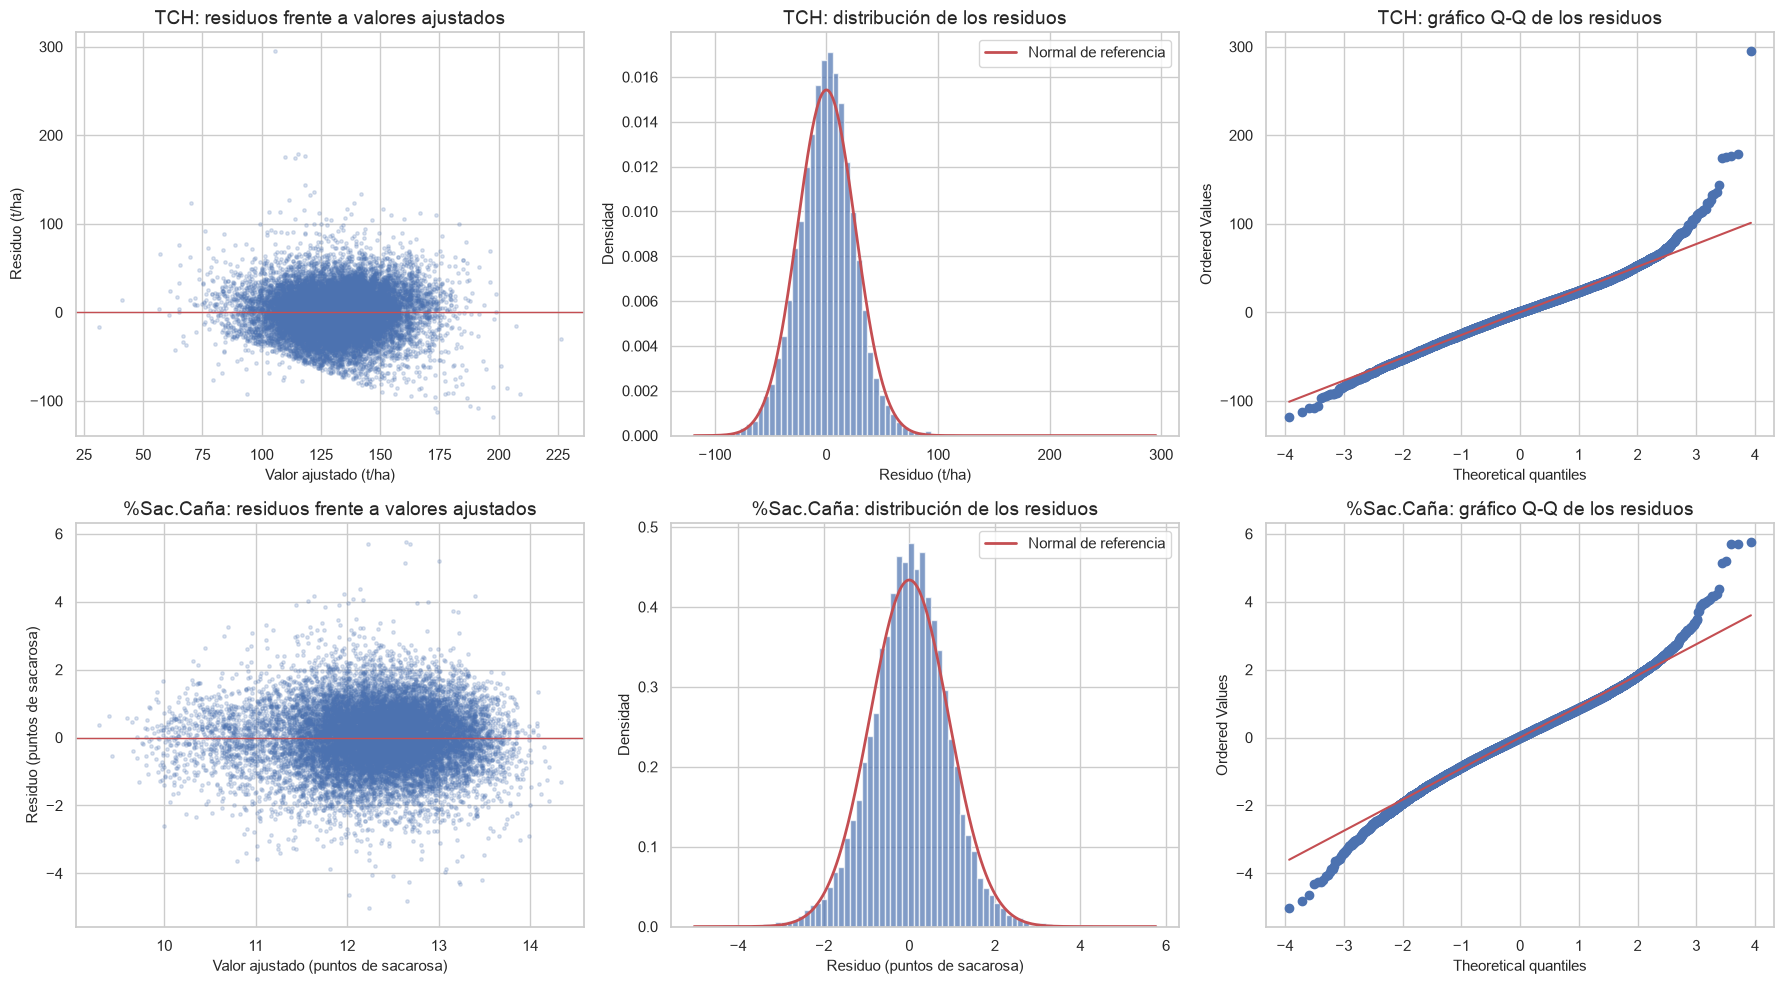

Resumen de las pruebas de supuestos (VIF en la celda de la matriz de diseño):


,TCH,%Sac.Caña
Durbin-Watson (orden por lote),1.346,1.772
Breusch-Pagan LM,702.373,707.324
Breusch-Pagan p-value,2.47e-110,7.32e-112
Shapiro-Wilk W (5000 residuos),0.989,0.984
Shapiro-Wilk p-value,9.15e-20,5.22e-23
Asimetría,0.247,-0.043
Curtosis en exceso,2.424,1.396


In [12]:
# 4.2 Verificación de supuestos: linealidad, independencia, homocedasticidad y normalidad de los residuos
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

UNIDADES = {"TCH": "t/ha", "%Sac.Caña": "puntos de sacarosa"}
ORDEN_POR_LOTE = ["Hacienda", "Suerte", "Período"]
TAMANO_MUESTRA_SHAPIRO = 5000  # límite por encima del cual scipy advierte que el p-value no es exacto


def residuos_ordenados_por_lote(target):
    """Residuos del OLS ordenados por lote y periodo, para que los cortes sucesivos de un lote queden contiguos."""
    datos = datos_por_target[target]
    residuos = pd.Series(ajustes_ols[target]["clasico"].resid.to_numpy(), index=datos.y_train.index)
    orden = df_train.loc[residuos.index, ORDEN_POR_LOTE].sort_values(ORDEN_POR_LOTE).index
    return residuos.loc[orden].to_numpy()


def formatear_supuestos(tabla):
    """p-values en notación científica (algunos son minúsculos) y el resto de estadísticos con 3 decimales."""
    return tabla.apply(
        lambda fila: fila.map(lambda valor: f"{valor:.2e}" if "p-value" in fila.name else f"{valor:.3f}"),
        axis=1,
    )


generador = np.random.default_rng(RANDOM_STATE)
resultados_supuestos = {}
fig, ejes = plt.subplots(2, 3, figsize=(18, 10))
for fila, target in enumerate(TARGETS):
    ajuste = ajustes_ols[target]["clasico"]
    residuos, ajustados = ajuste.resid.to_numpy(), ajuste.fittedvalues.to_numpy()

    # Independencia: Durbin-Watson con los cortes de cada lote en orden cronológico
    estadistico_dw = durbin_watson(residuos_ordenados_por_lote(target))
    # Homocedasticidad: Breusch-Pagan contra los mismos predictores del modelo
    lm_bp, p_bp, _, _ = het_breuschpagan(residuos, ajuste.model.exog)
    # Normalidad: Shapiro-Wilk sobre una muestra aleatoria de residuos
    muestra = generador.choice(residuos, size=min(TAMANO_MUESTRA_SHAPIRO, len(residuos)), replace=False)
    estadistico_sw, p_sw = stats.shapiro(muestra)

    resultados_supuestos[target] = {
        "Durbin-Watson (orden por lote)": estadistico_dw,
        "Breusch-Pagan LM": lm_bp,
        "Breusch-Pagan p-value": p_bp,
        "Shapiro-Wilk W (5000 residuos)": estadistico_sw,
        "Shapiro-Wilk p-value": p_sw,
        "Asimetría": stats.skew(residuos),
        "Curtosis en exceso": stats.kurtosis(residuos),
    }

    # Linealidad y homocedasticidad: los residuos deberían repartirse sin patrón alrededor de 0
    ejes[fila, 0].scatter(ajustados, residuos, s=6, alpha=0.2, color="#4C72B0")
    ejes[fila, 0].axhline(0, color="#C44E52", lw=1)
    ejes[fila, 0].set(title=f"{target}: residuos frente a valores ajustados",
                      xlabel=f"Valor ajustado ({UNIDADES[target]})", ylabel=f"Residuo ({UNIDADES[target]})")

    # Normalidad: histograma frente a una normal con la misma media y desviación estándar
    malla = np.linspace(residuos.min(), residuos.max(), 400)
    ejes[fila, 1].hist(residuos, bins=80, density=True, color="#4C72B0", alpha=0.7)
    ejes[fila, 1].plot(malla, stats.norm.pdf(malla, residuos.mean(), residuos.std()),
                       color="#C44E52", lw=2, label="Normal de referencia")
    ejes[fila, 1].legend()
    ejes[fila, 1].set(title=f"{target}: distribución de los residuos",
                      xlabel=f"Residuo ({UNIDADES[target]})", ylabel="Densidad")

    # Normalidad: los puntos del gráfico Q-Q deberían seguir la diagonal
    stats.probplot(residuos, dist="norm", plot=ejes[fila, 2])
    ejes[fila, 2].set_title(f"{target}: gráfico Q-Q de los residuos")

plt.tight_layout()
plt.show()

print("Resumen de las pruebas de supuestos (VIF en la celda de la matriz de diseño):")
display(formatear_supuestos(pd.DataFrame(resultados_supuestos)))

#### Conclusión de 4.2

**Supuestos.** El modelo lineal cumple el supuesto de colinealidad y, de forma aproximada, el de linealidad. No cumple los de homocedasticidad y normalidad, y el de independencia falla en `TCH`:

| Supuesto | `TCH` | `%Sac.Caña` | Lectura |
|---|---|---|---|
| Linealidad | Residuos sin curvas en el centro de la nube | Residuos sin patrón | Se cumple de forma aproximada. El borde inferior diagonal en `TCH` viene de excluir los lotes de molino con menos de 60 t/ha: en esos lotes, ningún residuo puede quedar por debajo de $60 - \hat{y}$ |
| Independencia | Durbin-Watson = 1.35 | 1.77 | En `TCH` el valor está por debajo de 1.5: hay autocorrelación positiva entre cortes sucesivos del mismo lote, de modo que un lote que supera la predicción en un corte tiende a superarla en el siguiente. En sacarosa el valor está en el rango aceptable |
| Homocedasticidad | Breusch-Pagan: LM = 702.4, p ≈ 1e-110 | LM = 707.3, p ≈ 1e-112 | No se cumple: la varianza del error cambia con los predictores |
| Normalidad | Shapiro-Wilk: W = 0.989, p ≈ 1e-20; curtosis en exceso 2.42 | W = 0.984, p ≈ 1e-23; curtosis en exceso 1.40 | Se rechaza, pero la desviación es moderada. El histograma sigue de cerca a la normal en el centro, y el gráfico Q-Q muestra que la diferencia está en las colas, más pesadas que las de una normal. En `TCH` hay un residuo cercano a +300 t/ha |
| Colinealidad | VIF < 5 en todas las columnas | VIF < 5 en todas las columnas | Se cumple. Si la referencia de una variable fuera una categoría rara, sus demás indicadoras sumarían casi siempre 1 y quedarían casi colineales entre sí; tomar como referencia la categoría más frecuente lo evita |

**Consecuencias para la inferencia.** Con heterocedasticidad y dependencia entre cortes de un mismo lote, los errores estándar clásicos no son válidos. Por eso la significancia de los coeficientes se decide con los errores agrupados por hacienda, que admiten las dos cosas; como cada lote pertenece a una sola hacienda, el agrupamiento también cubre la correlación entre sus cortes. La desviación de la normalidad pesa poco con más de 16 000 registros. Las columnas presentes en menos de 10 haciendas quedaron fuera de la interpretación.

**Lo que dice el modelo.** En tonelaje dominan el ciclo (la edad al corte y el número de corte), la variedad, la zona, la lluvia del inicio del ciclo y una tendencia decreciente entre años. En sacarosa dominan el madurante, la lluvia del final del ciclo y el mes de corte; la edad y el año no influyen. Los dos targets responden a factores distintos, y algunas variedades muestran una disyuntiva entre cantidad y calidad.

**Lo que no alcanza a capturar.** El R² dentro del entrenamiento es de 0.314 en `TCH` y 0.355 en `%Sac.Caña`. El gráfico de residuos frente a valores ajustados no muestra curvas, pero resume todos los predictores en uno solo, así que no puede revelar no linealidades de una variable en particular ni interacciones entre variables. El EDA encontró ambas: el codo del número de corte, que una pendiente única no representa, y el cambio de signo del efecto de la lluvia temprana según la variedad. Además, la autocorrelación en `TCH` indica que cada lote tiene un nivel propio de rendimiento que los predictores no recogen. Estos son los argumentos para probar los modelos basados en árboles de la sección 5.

### 4.3 Regresión regularizada: Ridge y Lasso

Ridge y Lasso estiman la misma regresión lineal, pero agregan a la suma de errores cuadrados una penalización sobre la magnitud de los coeficientes. En la forma que usa scikit-learn:

$$\text{Ridge:}\quad \min_{\beta}\; \lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_2^2 \qquad\qquad \text{Lasso:}\quad \min_{\beta}\; \frac{1}{2n}\lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_1$$

Con $\alpha = 0$ ambos coinciden con la regresión lineal, y a medida que $\alpha$ crece los coeficientes se encogen hacia 0. Ridge los encoge todos sin anular ninguno. Lasso, por la forma del valor absoluto, lleva algunos exactamente a 0, así que además selecciona variables. Las dos funciones objetivo están escaladas de forma distinta, por lo que un mismo valor de $\alpha$ no significa lo mismo en los dos modelos.

La penalización depende de la escala de cada predictor: sin estandarizar, un coeficiente en m³ de riego y otro en meses de edad se penalizarían de forma desigual. Por eso el pipeline agrega un `StandardScaler` después del preprocesamiento, ajustado también dentro de cada pliegue.

**Búsqueda de $\alpha$.** Se prueban 15 valores en escala logarítmica para cada modelo con `GridSearchCV`, en los mismos pliegues de la sección 3.3, y se elige el de menor RMSE medio de validación. Si el mejor valor queda en un extremo de la grilla, la grilla se tendría que ampliar. El RMSE del valor elegido es algo optimista, porque se elige y se mide con los mismos pliegues. Ese sesgo afecta a todos los modelos que se ajustan así en el notebook, y es mayor cuantas más configuraciones se prueban; por eso la estimación final la da el conjunto de prueba en la sección 7.

**Qué se espera.** En 4.1 el error de ajuste de la regresión lineal fue casi igual al de validación, es decir, el modelo no sobreajusta. Si es así, la penalización no debería mejorar mucho el error. Lo que se busca con esta sección es confirmarlo, y con Lasso, ver qué columnas se pueden eliminar sin perder desempeño.

In [13]:
# 4.3 Ridge y Lasso: búsqueda de la penalización con GridSearchCV en los pliegues fijos
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV

GRILLAS_REGULARIZADOS = {
    "Ridge": (Ridge(), {"modelo__alpha": np.logspace(-2, 5, 15)}),
    "Lasso": (Lasso(max_iter=20_000), {"modelo__alpha": np.logspace(-4, 1, 15)}),
}

# Búsquedas ajustadas por (modelo, target); se reutilizan en las secciones siguientes
busquedas = {}


def registrar_mejor_configuracion(nombre_modelo, target, busqueda):
    """Registra las métricas por pliegue de la mejor configuración, en el mismo formato que evaluar_cv."""
    resultados, mejor = busqueda.cv_results_, busqueda.best_index_
    por_pliegue = lambda clave: np.array([resultados[f"split{k}_{clave}"][mejor] for k in range(busqueda.n_splits_)])
    registrar_cv(nombre_modelo, target,
                 rmse=-por_pliegue("test_RMSE"), mae=-por_pliegue("test_MAE"), r2=por_pliegue("test_R2"),
                 rmse_ajuste=-por_pliegue("train_RMSE"))


def buscar_hiperparametros(nombre_modelo, pipeline, grilla, target, n_procesos=-1):
    """GridSearchCV en los pliegues fijos del target, con el RMSE como criterio. Reajusta la mejor
    configuración con todo el entrenamiento y registra sus métricas por pliegue.
    n_procesos limita los ajustes en paralelo cuando cada modelo ocupa mucha memoria (-1: todos los núcleos)."""
    datos = datos_por_target[target]
    busqueda = GridSearchCV(
        pipeline, grilla, cv=datos.pliegues, scoring=METRICAS_CV, refit="RMSE",
        return_train_score=True, n_jobs=n_procesos,
    )
    busqueda.fit(datos.X_train, datos.y_train)
    busquedas[(nombre_modelo, target)] = busqueda
    registrar_mejor_configuracion(nombre_modelo, target, busqueda)
    return busqueda


for target in TARGETS:
    for nombre_modelo, (modelo, grilla) in GRILLAS_REGULARIZADOS.items():
        busqueda = buscar_hiperparametros(nombre_modelo, crear_pipeline(modelo, escalar=True), grilla, target)
        valores_alpha = grilla["modelo__alpha"]
        mejor_alpha = busqueda.best_params_["modelo__alpha"]
        en_extremo = mejor_alpha in (valores_alpha.min(), valores_alpha.max())
        print(f"{target} | {nombre_modelo}: mejor alpha = {mejor_alpha:.4g} "
              f"({'en el extremo de la grilla' if en_extremo else 'dentro de la grilla'}) | "
              f"RMSE de validación = {-busqueda.best_score_:.3f}")

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Ridge", "Lasso"]).round(3))

TCH | Ridge: mejor alpha = 316.2 (dentro de la grilla) | RMSE de validación = 26.606
TCH | Lasso: mejor alpha = 0.07197 (dentro de la grilla) | RMSE de validación = 26.600
%Sac.Caña | Ridge: mejor alpha = 316.2 (dentro de la grilla) | RMSE de validación = 0.929
%Sac.Caña | Lasso: mejor alpha = 0.006105 (dentro de la grilla) | RMSE de validación = 0.929

Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Ridge             26.606  1.294  20.514  1.139  0.268  0.021   
          Lasso             26.600  1.268  20.514  1.117  0.268  0.020   
%Sac.Caña Ridge              0.929  0.026   0.715  0.025  0.335  0.055   
          Lasso              0.929  0.026   0.715  0.025  0.336  0.056   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Ridge                 25.937  0.337  
          Lasso                 25.937  0.337  
%Sac.Caña Ridge                  0.919  0.007  
          Lasso                  0.920  0.007

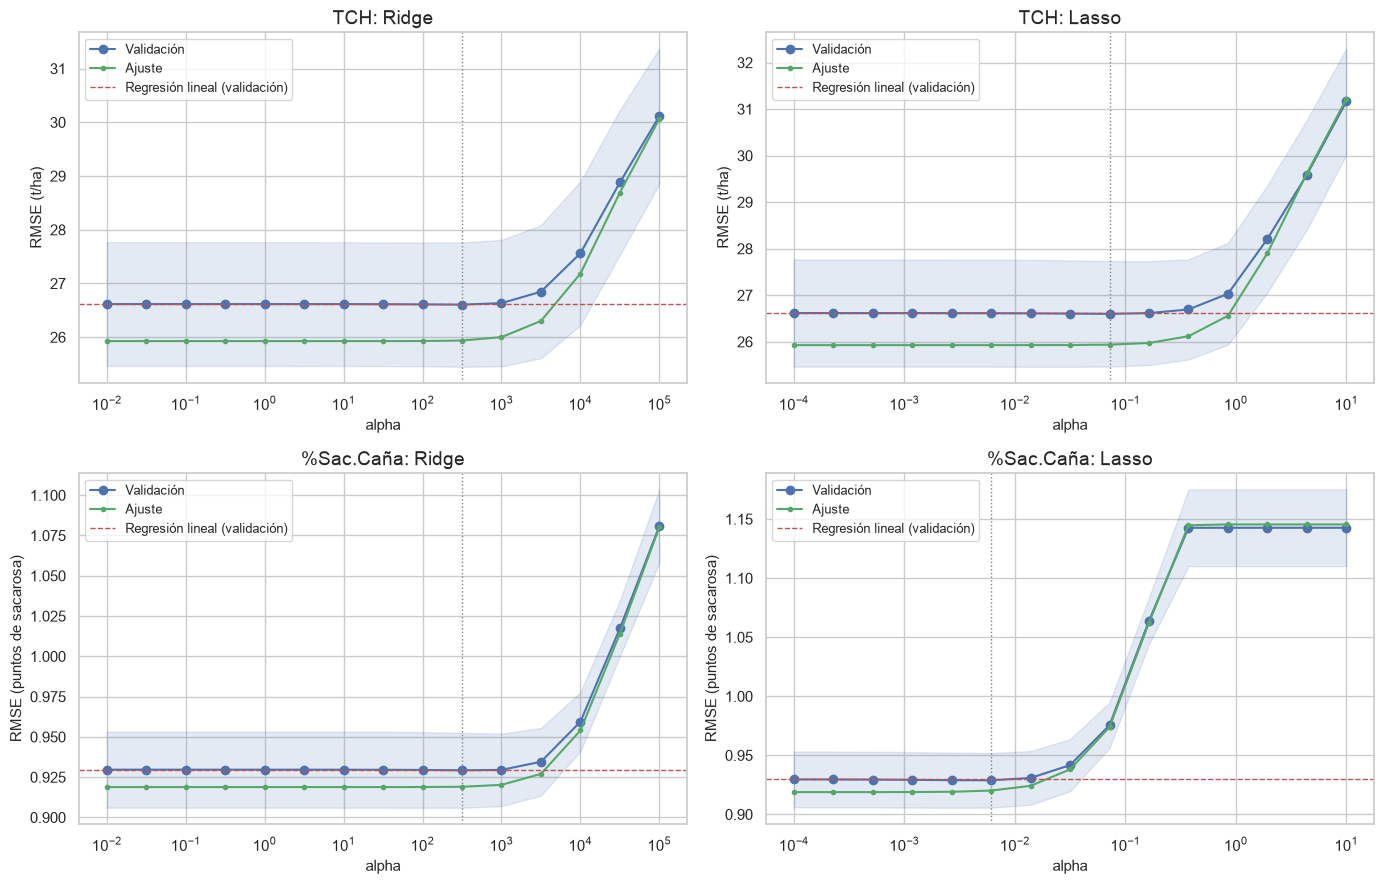

TCH: Lasso conserva 53 de 60 columnas. En cero: ['Luvias 9 -FC', 'Zona_agrup_IP03', 'T.Corte_agrup_NO DEF.', 'Tipo Quema_NO DEF.', 'Mes_03', 'Mes_09', 'Mes_10']
%Sac.Caña: Lasso conserva 50 de 59 columnas. En cero: ['Lluvias seis a nueve', 'Num.Riegos', 'Destino 1=Semilla', 'Zona_agrup_IP03', 'Suelo_agrup_GALPON', 'Suelo_agrup_PALMIRA', 'T.Corte_agrup_NO DEF.', 'Tenencia_agrup_31', 'Tenencia_agrup_OTRAS']


In [14]:
# 4.3 Curvas de validación de alpha y columnas que Lasso lleva a cero
fig, ejes = plt.subplots(len(TARGETS), len(GRILLAS_REGULARIZADOS), figsize=(14, 9))
for fila, target in enumerate(TARGETS):
    rmse_lineal = registro_cv[("Regresión lineal", target)]["RMSE"].mean()
    for columna, nombre_modelo in enumerate(GRILLAS_REGULARIZADOS):
        busqueda = busquedas[(nombre_modelo, target)]
        resultados = busqueda.cv_results_
        valores_alpha = np.array(resultados["param_modelo__alpha"], dtype=float)
        rmse_validacion = -resultados["mean_test_RMSE"]
        desviacion = resultados["std_test_RMSE"]

        eje = ejes[fila, columna]
        eje.plot(valores_alpha, rmse_validacion, marker="o", color="#4C72B0", label="Validación")
        eje.fill_between(valores_alpha, rmse_validacion - desviacion, rmse_validacion + desviacion,
                         color="#4C72B0", alpha=0.15)
        eje.plot(valores_alpha, -resultados["mean_train_RMSE"], marker=".", color="#55A868", label="Ajuste")
        eje.axhline(rmse_lineal, color="#C44E52", ls="--", lw=1, label="Regresión lineal (validación)")
        eje.axvline(busqueda.best_params_["modelo__alpha"], color="gray", ls=":", lw=1)
        eje.set(xscale="log", title=f"{target}: {nombre_modelo}", xlabel="alpha",
                ylabel=f"RMSE ({UNIDADES[target]})")
        eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Lasso reajustado con todo el entrenamiento y el alpha elegido: qué columnas quedan en cero
for target in TARGETS:
    mejor_lasso = busquedas[("Lasso", target)].best_estimator_
    nombres_columnas = mejor_lasso.named_steps["preprocesamiento"].get_feature_names_out()
    coeficientes = pd.Series(mejor_lasso.named_steps["modelo"].coef_, index=nombres_columnas)
    en_cero = coeficientes[coeficientes == 0].index.tolist()
    print(f"{target}: Lasso conserva {len(coeficientes) - len(en_cero)} de {len(coeficientes)} columnas. "
          f"En cero: {en_cero or 'ninguna'}")

#### Conclusión de 4.3

La regularización no mejora a la regresión lineal. Con el $\alpha$ elegido, el RMSE de validación baja de 26.616 a 26.606 t/ha con Ridge y a 26.600 con Lasso en `TCH`, y de 0.930 a 0.929 puntos con ambos en `%Sac.Caña`. Son diferencias unas 80 veces menores que la variación entre pliegues (1.29 t/ha y 0.026 puntos), y el MAE y el R² no cambian. En los cuatro casos el mejor $\alpha$ quedó dentro de la grilla.

Las curvas de validación muestran por qué. El error de ajuste y el de validación son planos mientras la penalización es pequeña, y cuando empieza a pesar (desde $\alpha \approx 10^3$ en Ridge y $\alpha \approx 0.1$ en Lasso) suben juntos. No hay un tramo en que la penalización reduzca el error de validación a costa del de ajuste, que sería la señal de un modelo con varianza que controlar; la brecha entre los dos se mantiene en unas 0.7 t/ha y 0.01 puntos. El valor elegido en Ridge ($\alpha = 316$) es además una penalización débil: en la forma de scikit-learn la suma de errores no se divide por el número de registros, y con más de 16 000 registros ese $\alpha$ apenas encoge los coeficientes. Esto confirma lo visto en 4.1: la regresión lineal no sobreajusta, y su error es de sesgo.

Lasso conserva 53 de 60 columnas en `TCH` y 50 de 59 en `%Sac.Caña`, y todas las que lleva a cero eran no significativas con errores agrupados en 4.2 o tenían un solo registro:

- **`TCH`:** la lluvia de 9 meses al corte, la zona IP03, los niveles sin definir de tipo de corte y de quema, y los meses de corte 03, 09 y 10.
- **`%Sac.Caña`:** la lluvia de 6 a 9 meses, el número de riegos, `Destino 1=Semilla`, la zona IP03, los suelos Galpón y Palmira, el tipo de corte sin definir y las tenencias 31 y `OTRAS`.

Las dos lecturas del modelo lineal, la inferencia de `statsmodels` y la selección de Lasso, coinciden en qué predictores no aportan. El caso de los meses es ilustrativo: septiembre y octubre se anulan en `TCH`, pero en `%Sac.Caña` estaban entre los coeficientes más grandes. El mes de corte influye en la calidad de la caña, no en su tonelaje. Que Lasso conserve casi todas las columnas indica, además, que la limitación del modelo lineal no viene de tener predictores de sobra, sino de la forma aditiva y lineal que les impone.

### Conclusión de la sección 4

Los cuatro modelos de referencia, evaluados en los mismos pliegues agrupados por hacienda:

| Modelo | `TCH`: RMSE (t/ha) | `TCH`: MAE | `TCH`: R² | `%Sac.Caña`: RMSE (puntos) | `%Sac.Caña`: MAE | `%Sac.Caña`: R² |
|---|---|---|---|---|---|---|
| Media constante | 31.16 ± 1.28 | 24.50 | −0.005 | 1.143 ± 0.036 | 0.894 | −0.002 |
| Regresión lineal | 26.62 ± 1.29 | 20.51 | 0.267 | 0.930 ± 0.026 | 0.716 | 0.335 |
| Ridge | 26.61 ± 1.29 | 20.51 | 0.268 | 0.929 ± 0.026 | 0.715 | 0.335 |
| Lasso | 26.60 ± 1.27 | 20.51 | 0.268 | 0.929 ± 0.026 | 0.715 | 0.336 |

La regresión lineal explica cerca de un cuarto de la variación del tonelaje y un tercio de la de la sacarosa en fincas que no vio durante el ajuste. La regularización no la mejora, así que la regresión lineal, el más simple de los tres, queda como modelo de referencia: los modelos de la sección 5 tienen que bajar de 26.6 t/ha y 0.93 puntos de RMSE. Como las diferencias entre modelos pueden ser pequeñas frente a la variación entre pliegues, en la sección 6 la comparación se hace pliegue a pliegue.

Además del desempeño, la sección dejó la lectura del modelo que se usará para contrastar la interpretabilidad de los modelos avanzados en la sección 8. Los factores con efecto claro sobre el tonelaje son el ciclo, la variedad, la zona y la lluvia del inicio del ciclo. Sobre la sacarosa, el madurante, la lluvia del final del ciclo y el mes de corte.

## 5. Modelos avanzados

La sección 4 mostró que la regresión lineal no sobreajusta y que su error es de sesgo: la forma aditiva y lineal no alcanza a describir la relación entre los predictores y los targets. Hay razones concretas para esperar que un modelo basado en árboles lo haga mejor:

- **Relaciones no lineales.** El TCH cae con el número de corte hasta el corte 9 o 10 y después se aplana, y la distancia al ingenio se relaciona con el TCH por tramos. Un árbol divide cada predictor en intervalos y asigna a cada uno su propio nivel, así que puede representar un codo o un escalón sin que se especifique su forma.
- **Interacciones.** En el EDA, el efecto de la lluvia temprana sobre el TCH cambia de signo según la variedad. Un modelo lineal solo representa esa interacción si se agrega como término explícito; un árbol la captura cuando divide primero por variedad y después por lluvia.
- **Supuestos.** Los árboles no suponen errores normales ni de varianza constante, dos supuestos que el modelo lineal no cumplió en 4.2, y no necesitan predictores estandarizados.

Los dos modelos combinan muchos árboles de forma distinta. **Random Forest** promedia árboles profundos entrenados en muestras bootstrap y con un subconjunto aleatorio de predictores en cada división: el promedio reduce la varianza de árboles individuales muy flexibles. **XGBoost** construye árboles poco profundos en secuencia, y cada uno corrige el error que dejaron los anteriores: reduce sobre todo el sesgo.

También tienen límites. No extrapolan fuera del rango de valores visto en el ajuste, y sus predicciones no se leen directamente como coeficientes. Su interpretación se aborda en la sección 8.

En 5.1 y 5.2 los dos se ajustan en los mismos pliegues y con los mismos predictores del modelo lineal, de modo que cualquier diferencia de desempeño se debe al modelo. En 5.3 se prueba una mejora que no depende del modelo: agregar a los tres el resultado del corte anterior de cada lote, a partir de la autocorrelación encontrada en 4.2.

### 5.1 Random Forest

**Búsqueda por etapas.** Random Forest y XGBoost tienen varios hiperparámetros, y una grilla con todas sus combinaciones sería inviable: con cinco hiperparámetros de tres a seis valores cada uno, Random Forest ya sumaría más de 800 configuraciones, es decir, más de 8000 bosques entre pliegues y targets. Por eso la búsqueda se hace por etapas. En cada etapa, `GridSearchCV` prueba todas las combinaciones de un grupo de hiperparámetros que interactúan entre sí, con los mejores valores de las etapas anteriores fijos. Cada grilla incluye el valor vigente, así que el error de validación no puede empeorar de una etapa a la siguiente. La búsqueda supone que la interacción entre grupos es menor que dentro de cada grupo. Para verificarlo, la última etapa repite la primera con los valores finales de las demás: si el resultado no cambia, el supuesto se sostiene. Además, con más configuraciones el RMSE de la mejor es algo más optimista, y por eso la estimación final la da el conjunto de prueba.

**Hiperparámetros que se buscan**

| Etapa | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| 1. Estructura | `max_features` | Fracción de predictores que se considera en cada división. Una fracción baja hace los árboles más distintos entre sí, lo que mejora el promedio, pero cada árbol es menos preciso | 0.1, 0.15, 0.2, 0.33, 0.5, 1.0 |
| | `min_samples_leaf` | Mínimo de registros por hoja: qué tan detallado es cada árbol. Con 1, cada árbol crece hasta separar casi cada registro de su muestra | 1, 2, 5, 10, 40 |
| 2. Muestreo y profundidad | `max_samples` | Tamaño de la muestra bootstrap de cada árbol, como fracción del entrenamiento. Muestras más pequeñas dan árboles más diversos | 0.5, 0.75, completa |
| | `max_depth` | Profundidad máxima de cada árbol | 12, 20, sin límite |
| 3. Número de árboles | `n_estimators` | Cuántos árboles se promedian. Más árboles no causan sobreajuste, solo estabilizan el promedio; esta etapa comprueba desde cuántos deja de mejorar | 150, 300, 600 |
| 4. Revisión de la estructura | `max_features`, `min_samples_leaf` | Segunda pasada de la etapa 1 con el muestreo, la profundidad y el número de árboles ya elegidos | Los de la etapa 1 |

En total son 72 configuraciones por target. Una primera búsqueda, con `max_features` desde 0.2 y `min_samples_leaf` desde 2, dejó el óptimo de `TCH` en esa esquina de la grilla y con el error todavía bajando, así que la grilla se extendió hacia valores menores. Los valores intermedios que quedaron lejos del óptimo en los dos targets (`max_features` = 0.75 y `min_samples_leaf` = 20) se quitaron para compensar el costo, pero se conservaron los extremos 1.0 y 40, de modo que la grilla sigue cubriendo todo el rango.

Con hojas de un registro y 600 árboles, cada bosque ocupa cientos de MB, así que la búsqueda de Random Forest limita a cuatro los ajustes en paralelo para no exceder la memoria del equipo.

**Hiperparámetros que no se buscan**

| Hiperparámetro | Motivo |
|---|---|
| `min_samples_split` | Es redundante con `min_samples_leaf`: si cada hoja necesita al menos $L$ registros, toda división necesita al menos $2L$, así que cualquier valor de `min_samples_split` menor o igual que $2L$ no tiene efecto |
| `max_leaf_nodes`, `min_impurity_decrease`, `ccp_alpha` | Son otras formas de limitar el tamaño de los árboles, que ya controlan `min_samples_leaf` y `max_depth` |
| `bootstrap` | `max_samples` ya cubre el muestreo; quitar el bootstrap elimina una fuente de diversidad entre árboles |
| `criterion` | El error cuadrático es coherente con el RMSE como criterio de selección. El error absoluto es órdenes de magnitud más lento con más de 16 000 registros, y `friedman_mse` da resultados casi idénticos |

**Resultados guardados.** La búsqueda tarda varios minutos, así que el resultado de cada modelo y target se guarda en la carpeta `resultados/`: el modelo final, la bitácora de etapas, los resultados de todas las configuraciones y la duración. Al ejecutar de nuevo el notebook, si las grillas no cambiaron, la búsqueda se carga en lugar de repetirse. Para recalcularla se cambia `RECALCULAR_BUSQUEDAS` a `True`; hay que hacerlo también si cambian los datos o el preprocesamiento, porque el archivo guardado no lo detecta.

In [15]:
# 5.1 Random Forest: búsqueda de hiperparámetros por etapas en los pliegues fijos
from datetime import datetime
from time import perf_counter

import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

RECALCULAR_BUSQUEDAS = False  # True repite las búsquedas aunque haya resultados guardados
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Códigos cortos y sin caracteres especiales para los nombres de los archivos guardados
CODIGOS_MODELO = {"Random Forest": "rf", "XGBoost": "xgb"}
CODIGOS_TARGET = {"TCH": "tch", "%Sac.Caña": "sac"}

# Con hojas de 1 registro y 600 árboles, cada bosque ocupa cientos de MB: se limitan los ajustes en paralelo
PROCESOS_RANDOM_FOREST = 4

GRILLA_ESTRUCTURA_RANDOM_FOREST = {
    "modelo__max_features": [0.1, 0.15, 0.2, 0.33, 0.5, 1.0],  # 1.0 es el máximo posible: todos los predictores
    "modelo__min_samples_leaf": [1, 2, 5, 10, 40],
}
ETAPAS_RANDOM_FOREST = {
    "1. Estructura": GRILLA_ESTRUCTURA_RANDOM_FOREST,
    "2. Muestreo y profundidad": {
        "modelo__max_samples": [0.5, 0.75, None],  # None: muestra bootstrap del tamaño del entrenamiento
        "modelo__max_depth": [12, 20, None],       # None: sin límite de profundidad
    },
    "3. Número de árboles": {
        "modelo__n_estimators": [150, 300, 600],
    },
    # Segunda pasada: verifica que la estructura elegida siga siendo la mejor con las demás etapas ya fijadas
    "4. Revisión de la estructura": GRILLA_ESTRUCTURA_RANDOM_FOREST,
}

# Detalle de cada búsqueda por etapas, por (modelo, target): bitácora, resultados por etapa, configuración y duración
detalle_busquedas = {}


def parametros_en_extremo(busqueda, grilla):
    """Hiperparámetros cuyo mejor valor quedó en el borde de su grilla, que podría ampliarse.
    None (sin límite, muestra completa) cuenta como el extremo superior."""
    en_extremo = []
    for parametro, valores in grilla.items():
        numericos = [valor for valor in valores if isinstance(valor, (int, float))]
        if not numericos:
            continue
        extremo_superior = None if None in valores else max(numericos)
        if busqueda.best_params_[parametro] in (min(numericos), extremo_superior):
            en_extremo.append(parametro.removeprefix("modelo__"))
    return en_extremo


def ruta_resultados(nombre_modelo, target):
    """Archivo de la búsqueda de un modelo y target. Un modelo sin código registrado detiene la ejecución,
    para no guardar con un nombre inesperado."""
    return CARPETA_RESULTADOS / f"busqueda_{CODIGOS_MODELO[nombre_modelo]}_{CODIGOS_TARGET[target]}.joblib"


def cargar_busqueda_guardada(ruta, etapas):
    """Búsqueda guardada, si existe, se puede leer y corresponde a las mismas etapas; si no, None."""
    if RECALCULAR_BUSQUEDAS or not ruta.exists():
        return None
    try:
        guardado = joblib.load(ruta)
    except Exception as error:  # archivo dañado o guardado con otra versión de las librerías
        print(f"  No se pudo leer {ruta} ({type(error).__name__}); la búsqueda se repite.")
        return None
    if not isinstance(guardado, dict) or guardado.get("etapas") != etapas:
        print(f"  {ruta} corresponde a otras grillas; la búsqueda se repite.")
        return None
    return guardado


def guardar_busqueda(ruta, contenido):
    """Guarda en un archivo temporal y lo renombra al terminar, para que una interrupción no deje un archivo
    a medias. Si no se puede escribir, avisa sin perder los resultados, que siguen en memoria."""
    try:
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta_temporal = ruta.with_suffix(".tmp")
        joblib.dump(contenido, ruta_temporal, compress=3)
        ruta_temporal.replace(ruta)
        return True
    except OSError as error:
        print(f"  No se pudo guardar {ruta} ({error}); los resultados quedan solo en memoria.")
        return False


def ejecutar_etapas(nombre_modelo, pipeline, etapas, target, n_procesos):
    """GridSearchCV por etapas: cada etapa busca un grupo de hiperparámetros con los mejores valores de las
    etapas anteriores fijos. Muestra el avance de cada etapa y devuelve la búsqueda de la última, que
    contiene la configuración completa."""
    n_pliegues = datos_por_target[target].pliegues.get_n_splits()
    mejores, bitacora, resultados_etapas = {}, [], {}
    for nombre_etapa, grilla in etapas.items():
        n_configuraciones = len(ParameterGrid(grilla))
        print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target} | {nombre_etapa}: {n_configuraciones} "
              f"configuraciones × {n_pliegues} pliegues = {n_configuraciones * n_pliegues} ajustes", flush=True)
        inicio_etapa = perf_counter()

        pipeline.set_params(**mejores)  # fija lo elegido en las etapas anteriores
        busqueda = buscar_hiperparametros(nombre_modelo, pipeline, grilla, target, n_procesos=n_procesos)
        mejores.update(busqueda.best_params_)
        minutos_etapa = (perf_counter() - inicio_etapa) / 60
        print(f"    terminada en {minutos_etapa:.1f} min | RMSE de validación = {-busqueda.best_score_:.3f}",
              flush=True)

        resultados_etapas[nombre_etapa] = pd.DataFrame(busqueda.cv_results_)
        bitacora.append({
            "etapa": nombre_etapa,
            "valores elegidos": ", ".join(f"{parametro.removeprefix('modelo__')} = {valor}"
                                          for parametro, valor in busqueda.best_params_.items()),
            "RMSE validación": -busqueda.best_score_,
            "en el extremo": ", ".join(parametros_en_extremo(busqueda, grilla)) or "-",
            "minutos": minutos_etapa,
        })
    configuracion = {parametro.removeprefix("modelo__"): valor for parametro, valor in mejores.items()}
    detalle = {"bitacora": pd.DataFrame(bitacora).set_index("etapa"),
               "resultados_etapas": resultados_etapas, "configuracion": configuracion}
    return busqueda, detalle


def buscar_por_etapas(nombre_modelo, pipeline, etapas, target, n_procesos=-1):
    """Búsqueda por etapas con resultados guardados: si hay un archivo válido con las mismas etapas, se carga
    y se registra; si no, se ejecuta la búsqueda y se guarda."""
    ruta = ruta_resultados(nombre_modelo, target)
    guardado = cargar_busqueda_guardada(ruta, etapas)

    if guardado is not None:
        busqueda, detalle, origen = guardado["busqueda"], guardado["detalle"], f"cargada de {ruta}"
        busquedas[(nombre_modelo, target)] = busqueda
        registrar_mejor_configuracion(nombre_modelo, target, busqueda)
    else:
        inicio = perf_counter()
        busqueda, detalle = ejecutar_etapas(nombre_modelo, pipeline, etapas, target, n_procesos)
        detalle["minutos"] = (perf_counter() - inicio) / 60
        guardada = guardar_busqueda(ruta, {"etapas": etapas, "busqueda": busqueda, "detalle": detalle})
        origen = f"calculada y guardada en {ruta}" if guardada else "calculada (sin guardar)"

    detalle_busquedas[(nombre_modelo, target)] = detalle
    return busqueda, detalle, origen


for target in TARGETS:
    bosque = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
    busqueda, detalle, origen = buscar_por_etapas("Random Forest", crear_pipeline(bosque), ETAPAS_RANDOM_FOREST,
                                                  target, n_procesos=PROCESOS_RANDOM_FOREST)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Random Forest"]).round(3))


TCH: búsqueda cargada de resultados/busqueda_rf_tch.joblib (14.4 min en total)
  Configuración final: {'max_features': 0.2, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': None, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.2, min_samples_leaf = 2",25.469,-,4.398
2. Muestreo y profundidad,"max_depth = None, max_samples = None",25.469,"max_samples, max_depth",0.761
3. Número de árboles,n_estimators = 600,25.464,n_estimators,0.585
4. Revisión de la estructura,"max_features = 0.2, min_samples_leaf = 2",25.464,-,8.701



%Sac.Caña: búsqueda cargada de resultados/busqueda_rf_sac.joblib (13.1 min en total)
  Configuración final: {'max_features': 0.33, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': 0.75, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.33, min_samples_leaf = 2",0.866,-,4.262
2. Muestreo y profundidad,"max_depth = None, max_samples = 0.75",0.866,max_depth,1.061
3. Número de árboles,n_estimators = 600,0.865,n_estimators,0.700
4. Revisión de la estructura,"max_features = 0.33, min_samples_leaf = 2",0.865,-,7.096



Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Random Forest     25.464  1.532  19.482  1.441  0.329  0.030   
%Sac.Caña Random Forest      0.865  0.029   0.658  0.028  0.424  0.051   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Random Forest         13.249  0.174  
%Sac.Caña Random Forest          0.494  0.004

TCH | RMSE de validación por número de árboles → 150 árboles: 25.513, 300 árboles: 25.469, 600 árboles: 25.464
%Sac.Caña | RMSE de validación por número de árboles → 150 árboles: 0.866, 300 árboles: 0.866, 600 árboles: 0.865


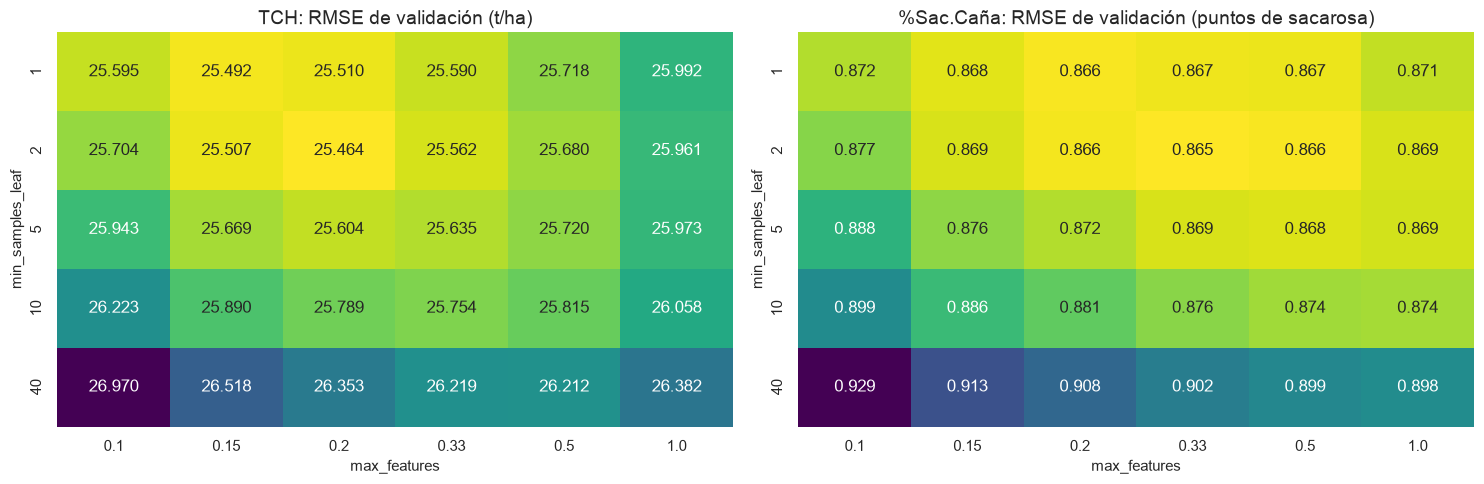

In [16]:
# 5.1 Revisión de los bordes de la grilla: RMSE de validación de la segunda pasada de la estructura
fig, ejes = plt.subplots(1, len(TARGETS), figsize=(15, 5))
for eje, target in zip(ejes, TARGETS):
    detalle = detalle_busquedas[("Random Forest", target)]
    resultados = detalle["resultados_etapas"]["4. Revisión de la estructura"]
    rmse_por_estructura = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
        index="param_modelo__min_samples_leaf", columns="param_modelo__max_features", values="RMSE",
    )
    sns.heatmap(rmse_por_estructura, annot=True, fmt=".3f", cmap="viridis_r", cbar=False, ax=eje)
    eje.set(title=f"{target}: RMSE de validación ({UNIDADES[target]})",
            xlabel="max_features", ylabel="min_samples_leaf")

    # Efecto del número de árboles, con la estructura de la etapa 1
    arboles = detalle["resultados_etapas"]["3. Número de árboles"]
    efecto_arboles = ", ".join(f"{int(n)} árboles: {-rmse:.3f}"
                               for n, rmse in zip(arboles["param_modelo__n_estimators"], arboles["mean_test_RMSE"]))
    print(f"{target} | RMSE de validación por número de árboles → {efecto_arboles}")
plt.tight_layout()
plt.show()

#### Conclusión de 5.1

**Configuración elegida**

| Hiperparámetro | `TCH` | `%Sac.Caña` |
|---|---|---|
| `max_features` | 0.2 | 0.33 |
| `min_samples_leaf` | 2 | 2 |
| `max_samples` | Muestra completa | 0.75 |
| `max_depth` | Sin límite | Sin límite |
| `n_estimators` | 600 | 600 |

Los dos targets prefieren árboles profundos y muy detallados, con hojas de dos registros, que en cada división consideran solo una fracción de los predictores: unas 12 de las 60 columnas en `TCH` y unas 20 en `%Sac.Caña`. Es la combinación que Random Forest aprovecha mejor, porque cada árbol tiene poco sesgo y el promedio de árboles distintos entre sí reduce su varianza.

**La grilla ya no limita el resultado.** En la segunda pasada de la estructura, el mapa de calor muestra el óptimo en el interior de la grilla ampliada. En `TCH`, bajar `max_features` de 0.2 a 0.15 o a 0.1 sube el RMSE (25.507 y 25.704 t/ha frente a 25.464), y lo mismo ocurre con hojas de un registro (25.510). En `%Sac.Caña` la superficie es casi plana alrededor del óptimo: todas las combinaciones entre 0.2 y 0.5 con hojas de 1 o 2 registros quedan entre 0.865 y 0.867 puntos. Los extremos que la bitácora todavía marca son límites naturales (sin límite de profundidad, muestra completa) o no tienen efecto práctico: pasar de 300 a 600 árboles baja el RMSE apenas 0.005 t/ha y 0.001 puntos, así que el promedio ya está estable. La segunda pasada eligió la misma estructura que la primera en los dos targets, lo que respalda el supuesto de la búsqueda por etapas.

**Desempeño frente a la regresión lineal**

| Target | Métrica | Regresión lineal | Random Forest |
|---|---|---|---|
| `TCH` | RMSE (t/ha) | 26.62 ± 1.29 | 25.46 ± 1.53 |
| | MAE (t/ha) | 20.51 | 19.48 |
| | R² | 0.267 | 0.329 |
| `%Sac.Caña` | RMSE (puntos) | 0.930 ± 0.026 | 0.865 ± 0.029 |
| | MAE (puntos) | 0.716 | 0.658 |
| | R² | 0.335 | 0.424 |

Random Forest reduce el RMSE de validación en 1.15 t/ha (4.3 %) en `TCH` y en 0.065 puntos (7.0 %) en `%Sac.Caña`, y mejora el MAE y el R² en los dos. La ganancia relativa es mayor en sacarosa, lo que sugiere que su relación con los predictores tiene más estructura no lineal o más interacciones que la del tonelaje. Qué variables la explican se revisa en la sección 8, y si la mejora se sostiene en cada pliegue, en la sección 6.

**Error de ajuste frente a validación.** El RMSE en la parte de ajuste (13.25 t/ha y 0.494 puntos) es mucho menor que el de validación. En Random Forest esa brecha es esperable: con hojas de dos registros, cada árbol casi reproduce su muestra. No indica un sobreajuste que haya que corregir, porque el mapa de calor muestra que los árboles más restringidos (hojas de 10 o 40 registros) tienen un error de validación mayor, no menor. El desempeño que importa es el de validación, en fincas que el modelo no vio.

**Costo.** Cada búsqueda tardó entre 13 y 15 minutos con cuatro procesos en paralelo, sobre todo por las dos etapas de estructura con 600 árboles en la segunda.

### 5.2 XGBoost

XGBoost construye los árboles en secuencia. Cada árbol nuevo $f_t$ se ajusta a lo que los anteriores no explicaron, y la predicción se actualiza con un paso pequeño:

$$\hat{y}^{(t)} = \hat{y}^{(t-1)} + \eta\, f_t(x)$$

donde $\eta$ es la tasa de aprendizaje (`learning_rate`). Cada árbol se elige minimizando la pérdida más una penalización sobre su complejidad:

$$\mathcal{L} = \sum_{i} \left(y_i - \hat{y}_i\right)^2 + \sum_{t} \Omega(f_t), \qquad \Omega(f) = \gamma\, T + \tfrac{1}{2}\lambda \lVert w \rVert_2^2 + \alpha \lVert w \rVert_1$$

donde $T$ es el número de hojas del árbol y $w$ los valores que predicen sus hojas. Casi todos los hiperparámetros controlan algún término de estas dos expresiones.

**Hiperparámetros que se buscan.** Se usa la misma búsqueda por etapas de Random Forest. El orden sigue la práctica habitual: primero la forma de los árboles, después la poda, el muestreo y la regularización, y al final la tasa de aprendizaje junto con el número de árboles, que son los dos hiperparámetros que más interactúan.

| Etapa | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| 1. Estructura | `max_depth` | Profundidad de cada árbol: de qué orden son las interacciones que puede capturar | 3, 4, 6, 8, 10 |
| | `min_child_weight` | Peso mínimo de una hoja; en regresión con error cuadrático, el número mínimo de registros | 1, 5, 10, 20 |
| 2. Poda | `gamma` ($\gamma$) | Mejora mínima de la pérdida para aceptar una división. Está en las unidades de la pérdida, que son muy distintas en `TCH` (t/ha al cuadrado) y en `%Sac.Caña`, por eso la grilla cubre varios órdenes de magnitud | 0, 0.01, 0.1, 1, 10, 100 |
| 3. Muestreo | `subsample` | Fracción de registros con que se ajusta cada árbol | 0.6, 0.8, 1.0 |
| | `colsample_bytree` | Fracción de predictores disponible para cada árbol | 0.5, 0.7, 0.85, 1.0 |
| 4. Regularización | `reg_alpha` ($\alpha$), `reg_lambda` ($\lambda$) | Penalización L1 y L2 sobre los valores de las hojas | $\alpha$: 0, 0.1, 1, 10; $\lambda$: 0.1, 1, 10, 100 |
| 5. Aprendizaje | `learning_rate` ($\eta$), `n_estimators` | Tamaño del paso y número de árboles. Un paso más pequeño necesita más árboles, pero suele generalizar mejor | $\eta$: 0.01, 0.03, 0.05, 0.1; árboles: 300, 600, 1000, 2000 |
| 6. Revisión de la estructura | `max_depth`, `min_child_weight` | Segunda pasada de la etapa 1 con todo lo demás ya elegido | Los de la etapa 1 |

En total son 90 configuraciones por target. Los valores iniciales son los de la librería, con 300 árboles, y todos están en la grilla de su etapa.

**Hiperparámetros que no se buscan**

| Hiperparámetro | Motivo |
|---|---|
| `colsample_bylevel`, `colsample_bynode` | Muestrean predictores por nivel o por división; cumplen el mismo papel que `colsample_bytree` |
| `max_leaves`, `grow_policy` | Son otra forma de limitar el tamaño de los árboles, que ya controlan `max_depth` y `min_child_weight` |
| `max_bin` | Número de intervalos en que el método `hist` divide cada predictor. El valor por defecto (256) es más fino que la resolución de casi todos los predictores |
| `max_delta_step`, `scale_pos_weight` | Están pensados para clasificación con clases desbalanceadas |
| `booster` | `dart` y `gblinear` son otros algoritmos; el segundo es un modelo lineal |

**Sin parada temprana.** XGBoost puede detener el entrenamiento cuando el error deja de bajar en un conjunto de validación. Aquí no se usa, porque ese conjunto sería el mismo pliegue con el que se mide el desempeño, y el RMSE de validación quedaría sesgado a favor de XGBoost. El número de árboles se elige como un hiperparámetro más, igual que en Random Forest.

**Implementación.** Se usa `XGBRegressor`, la interfaz de XGBoost para scikit-learn, dentro del mismo `Pipeline` que los demás modelos, de modo que el preprocesamiento se reajusta en cada pliegue. Internamente, con `tree_method="hist"`, `XGBRegressor` convierte los datos en un `QuantileDMatrix`, la estructura de datos de XGBoost que agrupa cada predictor en intervalos y ahorra memoria. Usar `DMatrix` directamente obligaría a preprocesar fuera del `Pipeline` y a evaluar XGBoost con un procedimiento distinto al de los demás modelos.

In [17]:
# 5.2 XGBoost: búsqueda de hiperparámetros por etapas en los pliegues fijos
from xgboost import XGBRegressor

GRILLA_ESTRUCTURA_XGBOOST = {
    "modelo__max_depth": [3, 4, 6, 8, 10],
    "modelo__min_child_weight": [1, 5, 10, 20],
}
ETAPAS_XGBOOST = {
    "1. Estructura": GRILLA_ESTRUCTURA_XGBOOST,
    "2. Poda": {
        "modelo__gamma": [0, 0.01, 0.1, 1, 10, 100],  # varios órdenes de magnitud: la escala depende del target
    },
    "3. Muestreo": {
        "modelo__subsample": [0.6, 0.8, 1.0],
        "modelo__colsample_bytree": [0.5, 0.7, 0.85, 1.0],
    },
    "4. Regularización": {
        "modelo__reg_alpha": [0, 0.1, 1, 10],
        "modelo__reg_lambda": [0.1, 1, 10, 100],
    },
    "5. Aprendizaje": {
        "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "modelo__n_estimators": [300, 600, 1000, 2000],
    },
    # Segunda pasada: verifica la estructura con la tasa de aprendizaje y el número de árboles ya elegidos
    "6. Revisión de la estructura": GRILLA_ESTRUCTURA_XGBOOST,
}


def crear_xgboost():
    """XGBoost con los valores iniciales de la búsqueda; cada uno aparece en la grilla de su etapa."""
    return XGBRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=6, min_child_weight=1, gamma=0,
        subsample=1.0, colsample_bytree=1.0, reg_alpha=0, reg_lambda=1,
        tree_method="hist",  # divide cada predictor en intervalos; internamente usa un QuantileDMatrix
        n_jobs=1,            # el paralelismo lo maneja GridSearchCV, con un ajuste por núcleo
        random_state=RANDOM_STATE,
    )


for target in TARGETS:
    busqueda, detalle, origen = buscar_por_etapas("XGBoost", crear_pipeline(crear_xgboost()), ETAPAS_XGBOOST, target)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Random Forest", "XGBoost"]).round(3))


TCH: búsqueda cargada de resultados/busqueda_xgb_tch.joblib (2.0 min en total)
  Configuración final: {'max_depth': 6, 'min_child_weight': 5, 'gamma': 0, 'colsample_bytree': 1.0, 'subsample': 0.8, 'reg_alpha': 1, 'reg_lambda': 100, 'learning_rate': 0.03, 'n_estimators': 1000}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 10",25.449,-,0.355
2. Poda,gamma = 0,25.449,gamma,0.061
3. Muestreo,"colsample_bytree = 1.0, subsample = 0.8",25.413,colsample_bytree,0.111
4. Regularización,"reg_alpha = 1, reg_lambda = 100",25.348,reg_lambda,0.132
5. Aprendizaje,"learning_rate = 0.03, n_estimators = 1000",25.312,-,0.310
6. Revisión de la estructura,"max_depth = 6, min_child_weight = 5",25.239,-,1.000



%Sac.Caña: búsqueda cargada de resultados/busqueda_xgb_sac.joblib (1.6 min en total)
  Configuración final: {'max_depth': 4, 'min_child_weight': 20, 'gamma': 0, 'colsample_bytree': 0.85, 'subsample': 0.8, 'reg_alpha': 0, 'reg_lambda': 10, 'learning_rate': 0.05, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 20",0.849,min_child_weight,0.342
2. Poda,gamma = 0,0.849,gamma,0.045
3. Muestreo,"colsample_bytree = 0.85, subsample = 0.8",0.848,-,0.098
4. Regularización,"reg_alpha = 0, reg_lambda = 10",0.848,reg_alpha,0.131
5. Aprendizaje,"learning_rate = 0.05, n_estimators = 600",0.845,-,0.306
6. Revisión de la estructura,"max_depth = 4, min_child_weight = 20",0.845,min_child_weight,0.634



Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Random Forest     25.464  1.532  19.482  1.441  0.329  0.030   
%Sac.Caña Random Forest      0.865  0.029   0.658  0.028  0.424  0.051   
TCH       XGBoost           25.239  1.112  19.285  1.021  0.341  0.009   
%Sac.Caña XGBoost            0.845  0.027   0.643  0.024  0.450  0.047   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Random Forest         13.249  0.174  
%Sac.Caña Random Forest          0.494  0.004  
TCH       XGBoost               18.061  0.187  
%Sac.Caña XGBoost                0.719  0.008

#### Revisión de los bordes de la grilla

La bitácora de cada target marca algunos hiperparámetros en el extremo de su grilla. Varios de ellos son límites naturales que no se pueden extender: `gamma` = 0 (ninguna poda adicional), `reg_alpha` = 0 (sin penalización L1) y `colsample_bytree` = 1.0 (todos los predictores disponibles para cada árbol). Hay dos que sí podrían estar limitando el resultado:

- En `TCH`, `reg_lambda` = 100, el valor más alto de su grilla.
- En `%Sac.Caña`, `min_child_weight` = 20, también el más alto, elegido tanto en la etapa 1 como en la segunda pasada.

Para decidir si conviene ampliar la grilla, se revisa cómo cambia el RMSE de validación alrededor de esos valores en las tres etapas que combinan dos hiperparámetros: la regularización, la tasa de aprendizaje con el número de árboles, y la segunda pasada de la estructura.

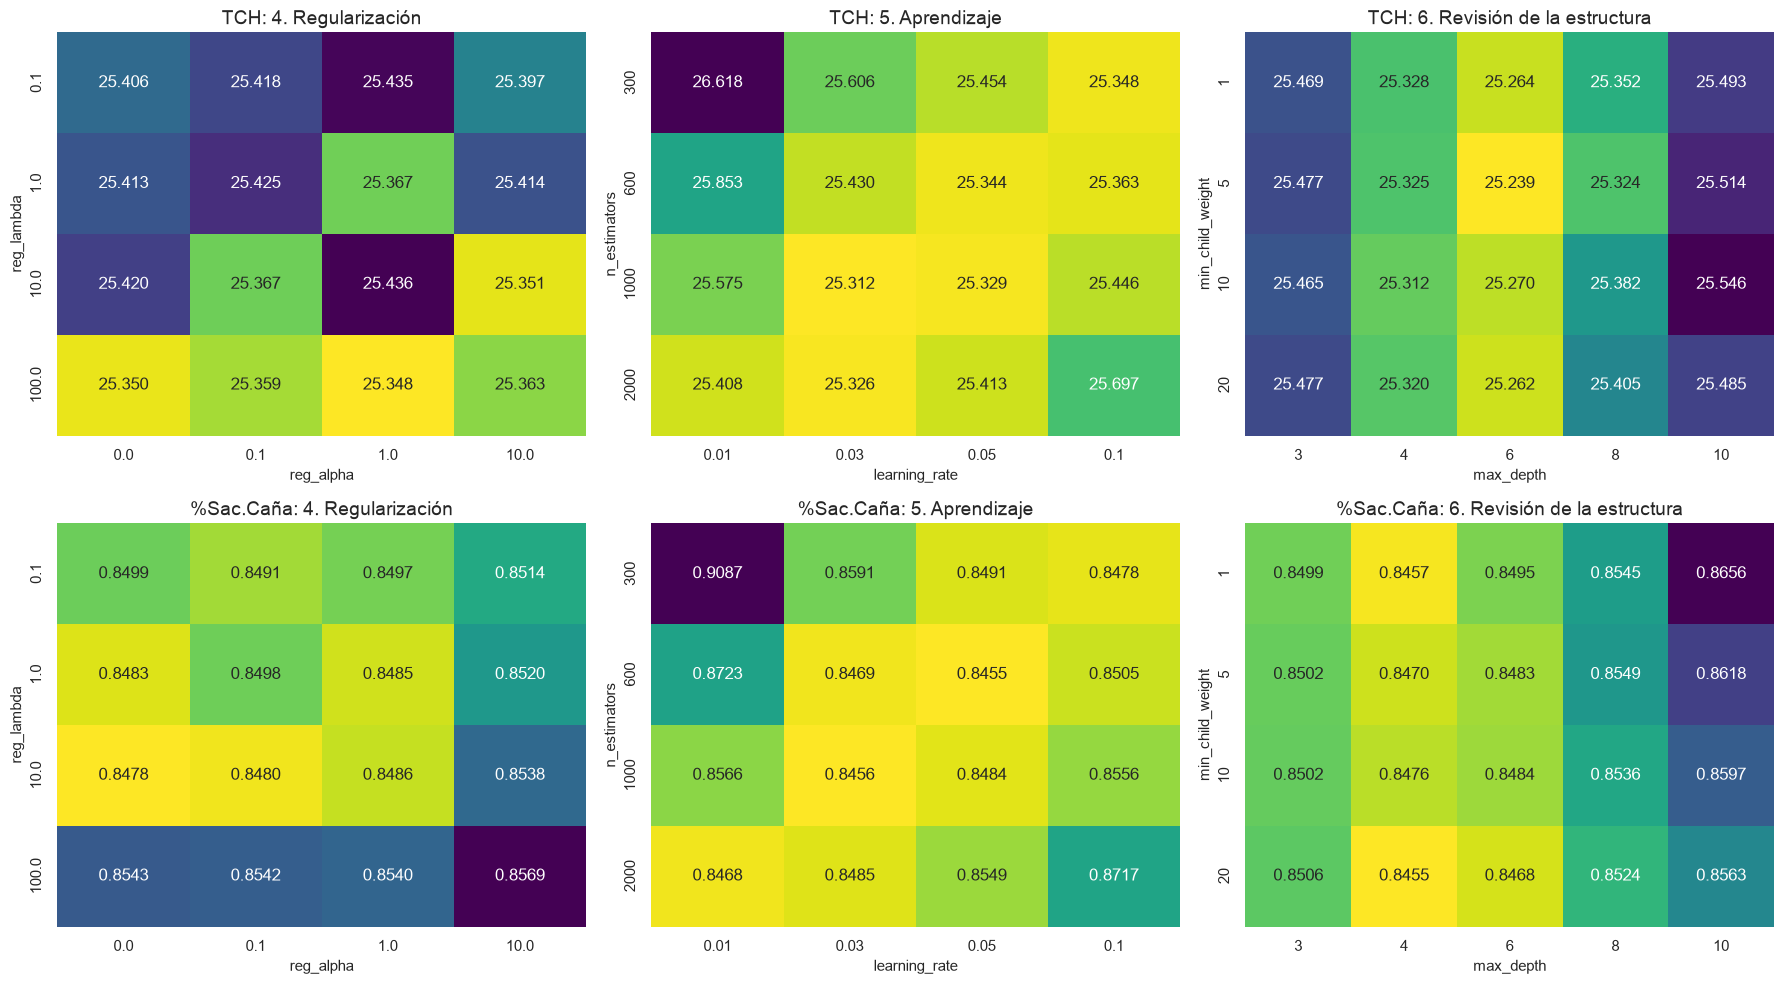

In [18]:
# 5.2 Revisión de los bordes de la grilla de XGBoost: RMSE de validación en las etapas con dos hiperparámetros
ETAPAS_XGBOOST_A_REVISAR = {  # etapa: (hiperparámetro en las filas, hiperparámetro en las columnas)
    "4. Regularización": ("modelo__reg_lambda", "modelo__reg_alpha"),
    "5. Aprendizaje": ("modelo__n_estimators", "modelo__learning_rate"),
    "6. Revisión de la estructura": ("modelo__min_child_weight", "modelo__max_depth"),
}
DECIMALES_MAPA = {"TCH": ".3f", "%Sac.Caña": ".4f"}  # las diferencias en sacarosa están en milésimas

fig, ejes = plt.subplots(len(TARGETS), len(ETAPAS_XGBOOST_A_REVISAR), figsize=(18, 10))
for fila, target in enumerate(TARGETS):
    resultados_etapas = detalle_busquedas[("XGBoost", target)]["resultados_etapas"]
    for columna, (etapa, (parametro_filas, parametro_columnas)) in enumerate(ETAPAS_XGBOOST_A_REVISAR.items()):
        resultados = resultados_etapas[etapa]
        rmse_por_combinacion = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
            index=f"param_{parametro_filas}", columns=f"param_{parametro_columnas}", values="RMSE",
        )
        eje = ejes[fila, columna]
        sns.heatmap(rmse_por_combinacion, annot=True, fmt=DECIMALES_MAPA[target], cmap="viridis_r", cbar=False, ax=eje)
        eje.set(title=f"{target}: {etapa}", xlabel=parametro_columnas.removeprefix("modelo__"),
                ylabel=parametro_filas.removeprefix("modelo__"))
plt.tight_layout()
plt.show()

#### Decisión sobre los bordes

La grilla de XGBoost no se amplía. A diferencia de Random Forest, ninguno de los dos bordes muestra una tendencia que valga la pena seguir:

- **`reg_lambda` en `TCH`.** Las 16 combinaciones de la regularización quedan entre 25.348 y 25.436 t/ha, una diferencia de 0.09 t/ha, y el patrón es irregular: con `reg_alpha` = 1, por ejemplo, el error sube y baja al aumentar `reg_lambda`. La fila de `reg_lambda` = 100 es mejor que las demás por unas 0.04 t/ha en promedio, una diferencia del orden del ruido entre configuraciones.
- **`min_child_weight` en `%Sac.Caña`.** Con profundidad 4, que es la elegida, el error es prácticamente el mismo en los dos extremos de la grilla: 0.8457 puntos con `min_child_weight` = 1 y 0.8455 con 20. El valor elegido está en el borde, pero el óptimo no está más allá.

Ampliar la grilla en una zona tan plana elegiría entre configuraciones equivalentes según el ruido de los pliegues, y además haría más optimista el RMSE de la configuración elegida.

La etapa de aprendizaje muestra la relación esperada entre la tasa de aprendizaje y el número de árboles: cuanto más pequeño el paso, más árboles se necesitan, y las mejores combinaciones forman una diagonal. En `TCH`, 0.03 con 1000 árboles (25.312), 0.05 con 600 (25.344) y 0.1 con 300 (25.348) son casi equivalentes; con 0.01, ni siquiera 2000 árboles alcanzan ese nivel (25.408).

#### Conclusión de 5.2

**Configuración elegida**

| Hiperparámetro | `TCH` | `%Sac.Caña` |
|---|---|---|
| `max_depth` | 6 | 4 |
| `min_child_weight` | 5 | 20 |
| `gamma` | 0 | 0 |
| `subsample` | 0.8 | 0.8 |
| `colsample_bytree` | 1.0 | 0.85 |
| `reg_alpha` | 1 | 0 |
| `reg_lambda` | 100 | 10 |
| `learning_rate` | 0.03 | 0.05 |
| `n_estimators` | 1000 | 600 |

Los dos modelos usan árboles de profundidad moderada, una tasa de aprendizaje baja con cientos de árboles, muestreo del 80 % de los registros en cada árbol y, en `TCH`, una regularización L2 fuerte. La poda con `gamma` no aportó en ningún target.

**Recorrido de la búsqueda.** En `TCH` el RMSE de validación bajó de 25.449 a 25.239 t/ha a lo largo de las seis etapas. Las mayores mejoras vinieron de la regularización (−0.065) y de la segunda pasada de la estructura (−0.073), que cambió la profundidad de 4 a 6 y `min_child_weight` de 10 a 5 una vez fijadas la tasa de aprendizaje y la regularización. Eso muestra que en XGBoost la estructura de los árboles sí interactúa con las etapas posteriores, y que la segunda pasada era necesaria. En `%Sac.Caña` la búsqueda bajó de 0.849 a 0.845 puntos, y la segunda pasada confirmó la estructura de la primera.

**Desempeño frente a los modelos anteriores**

| Target | Métrica | Regresión lineal | Random Forest | XGBoost |
|---|---|---|---|---|
| `TCH` | RMSE (t/ha) | 26.62 ± 1.29 | 25.46 ± 1.53 | 25.24 ± 1.11 |
| | MAE (t/ha) | 20.51 | 19.48 | 19.29 |
| | R² | 0.267 ± 0.021 | 0.329 ± 0.030 | 0.341 ± 0.009 |
| `%Sac.Caña` | RMSE (puntos) | 0.930 ± 0.026 | 0.865 ± 0.029 | 0.845 ± 0.027 |
| | MAE (puntos) | 0.716 | 0.658 | 0.643 |
| | R² | 0.335 ± 0.055 | 0.424 ± 0.051 | 0.450 ± 0.047 |

XGBoost tiene el menor error de validación en los dos targets. Frente a la regresión lineal, reduce el RMSE en 1.38 t/ha (5.2 %) en `TCH` y en 0.085 puntos (9.1 %) en `%Sac.Caña`. Frente a Random Forest la ventaja es más pequeña, de 0.22 t/ha y 0.020 puntos, del orden de la variación entre pliegues; si es consistente en cada pliegue se revisa en la sección 6. En `TCH`, además, el R² de XGBoost varía mucho menos entre pliegues (0.009 frente a 0.030 en Random Forest), es decir, su desempeño depende menos del grupo de fincas que se evalúa.

**Error de ajuste frente a validación.** La brecha es menor que en Random Forest: 18.06 frente a 25.24 t/ha en `TCH`, y 0.719 frente a 0.845 puntos en `%Sac.Caña`. Es coherente con su diseño: árboles poco profundos, regularización sobre las hojas y una tasa de aprendizaje baja limitan cuánto se adapta cada árbol al entrenamiento.

**Costo.** Cada búsqueda tardó menos de 2 minutos con 90 configuraciones, frente a los 13 a 15 minutos de Random Forest con 72. XGBoost obtiene el mejor resultado con una fracción del costo computacional.

### 5.3 Historial del lote

En 4.2, la prueba de Durbin-Watson con los registros ordenados por lote dio 1.35 en `TCH`: un lote que supera la predicción del modelo lineal en un corte tiende a superarla también en el siguiente. Cada lote tiene un nivel propio de rendimiento que los predictores no recogen, probablemente por condiciones que el histórico no registra, como la calidad del suelo dentro de la finca, el drenaje o el manejo particular del lote. En `%Sac.Caña` el estadístico fue 1.77 y esa persistencia es más débil.

La forma más directa de darle esa información al modelo es el resultado del corte anterior del mismo lote. Para cada cosecha se construyen tres columnas:

- **`TCH_corte_anterior`** y **`Sac_corte_anterior`**: el TCH y la sacarosa de la cosecha anterior del mismo lote en el histórico. Las dos entran en los modelos de ambos targets.
- **`sin_historial`**: vale 1 cuando el lote no tiene una cosecha anterior en el histórico. Ocurre con la primera aparición de cada lote, ya sea porque es su primer corte o porque el anterior fue antes de enero de 2017, cuando empiezan los datos. En esos registros los valores anteriores se imputan, dentro del `Pipeline`, con la mediana del entrenamiento de cada pliegue, y la bandera permite que el modelo los distinga.

**Por qué no es fuga de información.** Al programar un corte, el Ingenio ya conoce el resultado del corte anterior del mismo lote, que se cosechó en el ciclo previo. La columna solo usa el pasado del propio lote: no se estima ningún estadístico con otros registros, así que se puede calcular sobre todo el histórico sin que la información de un conjunto pase al otro. Como la partición agrupa por hacienda, todos los cortes de un lote quedan en el mismo conjunto, y el historial de un lote de prueba sale solo de cosechas de prueba anteriores.

**Cómo se compara.** Se usan los mismos registros, los mismos pliegues y las mismas etapas de búsqueda de 5.1 y 5.2, y se evalúan los tres modelos (regresión lineal, Random Forest y XGBoost) con el historial. Así, la ganancia de la variable se mide por separado en cada modelo y se puede distinguir de la ganancia que aporta el modelo.

Antes de ajustar los modelos se verifica la construcción: qué fracción de registros no tiene historial y cómo cambia por año, cuánto tiempo pasa entre un corte y el anterior, y qué tan asociado está cada target con su valor del corte anterior en el entrenamiento.

In [19]:
# 5.3 Historial del lote: resultado del corte anterior de cada lote, calculado solo con su propio pasado
COLUMNAS_HISTORIAL_VALOR = ["TCH_corte_anterior", "Sac_corte_anterior"]
COLUMNAS_HISTORIAL = COLUMNAS_HISTORIAL_VALOR + ["sin_historial"]


def meses_absolutos(periodo):
    """Período AAAAMM convertido en un conteo de meses, para poder restar fechas."""
    return (periodo // 100) * 12 + periodo % 100


def historial_por_lote(df):
    """Para cada cosecha, el TCH y la sacarosa de la cosecha anterior del mismo lote en el histórico.
    No tiene estado entre lotes: cada valor sale solo del pasado de su propio lote."""
    ordenado = df.sort_values(ORDEN_POR_LOTE)
    anterior = ordenado.groupby(["Hacienda", "Suerte"])[["TCH", "%Sac.Caña", "Período", "Cod.Estado #"]].shift(1)
    historial = pd.DataFrame({
        "TCH_corte_anterior": anterior["TCH"],
        "Sac_corte_anterior": anterior["%Sac.Caña"],
        "sin_historial": anterior["Período"].isna().astype(int),
        # Las dos columnas siguientes solo sirven para verificar la construcción; no son predictores
        "meses_desde_corte_anterior": meses_absolutos(ordenado["Período"]) - meses_absolutos(anterior["Período"]),
        "corte_consecutivo": (ordenado["Cod.Estado #"] - anterior["Cod.Estado #"]) == 1,
    }, index=ordenado.index)
    return historial.reindex(df.index)


historial_lotes = historial_por_lote(df_suertes)
assert historial_lotes.index.equals(df_suertes.index)
assert (historial_lotes["meses_desde_corte_anterior"].dropna() > 0).all(), "Un corte anterior no es anterior en el tiempo"

# Las columnas se agregan a los conjuntos de cada target. El preprocesador de las secciones 4, 5.1 y 5.2
# solo usa COLUMNAS_CRUDAS, así que los modelos ya ajustados no cambian.
for target, datos in datos_por_target.items():
    datos.X_train = datos.X_train.drop(columns=COLUMNAS_HISTORIAL, errors="ignore").join(historial_lotes[COLUMNAS_HISTORIAL])
    datos.X_test = datos.X_test.drop(columns=COLUMNAS_HISTORIAL, errors="ignore").join(historial_lotes[COLUMNAS_HISTORIAL])

# 1. Registros sin historial: en total, por conjunto y por año de cosecha
con_historial = historial_lotes["sin_historial"] == 0
print(f"Registros sin historial: {historial_lotes['sin_historial'].mean():.1%} del histórico")
for target, datos in datos_por_target.items():
    print(f"  {target}: entrenamiento {datos.X_train['sin_historial'].mean():.1%} | "
          f"prueba {datos.X_test['sin_historial'].mean():.1%}")
sin_historial_por_año = (historial_lotes["sin_historial"].groupby(df_suertes["Período"] // 100).mean() * 100)
display(sin_historial_por_año.round(1).rename("% sin historial").rename_axis("año de cosecha").to_frame().T)

# 2. Tiempo entre un corte y el anterior del mismo lote, y si el número de corte avanza en uno
meses_entre_cortes = historial_lotes.loc[con_historial, "meses_desde_corte_anterior"]
print("\nMeses entre un corte y el anterior del mismo lote:")
display(meses_entre_cortes.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1).to_frame().T)
print(f"El número de corte aumenta en exactamente 1 respecto al corte anterior en el "
      f"{historial_lotes.loc[con_historial, 'corte_consecutivo'].mean():.1%} de los registros con historial")

# 3. Asociación de cada target con su valor del corte anterior, solo en el entrenamiento
print("\nCorrelación de Spearman en el entrenamiento (registros con historial):")
for target, columna_anterior in {"TCH": "TCH_corte_anterior", "%Sac.Caña": "Sac_corte_anterior"}.items():
    datos = datos_por_target[target]
    rho = datos.y_train.corr(datos.X_train[columna_anterior], method="spearman")
    print(f"  {target} con {columna_anterior}: {rho:.3f}")

Registros sin historial: 27.6% del histórico
  TCH: entrenamiento 28.0% | prueba 26.1%
  %Sac.Caña: entrenamiento 28.0% | prueba 26.3%


año de cosecha,2017,2018,2019,2020,2021,2022,2023,2024
% sin historial,99.0,33.1,13.8,16.3,14.8,20.3,13.8,7.5



Meses entre un corte y el anterior del mismo lote:


,count,mean,std,min,1%,5%,50%,95%,99%,max
meses_desde_corte_anterior,15228.0,13.9,4.8,1.0,9.0,11.0,13.0,19.0,37.0,83.0


El número de corte aumenta en exactamente 1 respecto al corte anterior en el 85.8% de los registros con historial

Correlación de Spearman en el entrenamiento (registros con historial):
  TCH con TCH_corte_anterior: 0.389
  %Sac.Caña con Sac_corte_anterior: 0.277


#### Cortes anteriores demasiado cercanos

La construcción se comporta como se esperaba. En 2017 casi ningún registro tiene historial, porque los datos empiezan ese año; desde 2019 la fracción sin historial baja a entre 8 % y 20 %, que corresponde a las primeras apariciones reales de los lotes. La mediana entre un corte y el anterior es de 13 meses, y el número de corte avanza en exactamente uno en el 85.8 % de los casos; el resto son renovaciones del cultivo o cortes que no quedaron en el histórico. En el entrenamiento, el TCH del corte anterior tiene una correlación de Spearman de 0.389 con el TCH, mayor que la de cualquier predictor del EDA, y la sacarosa anterior una de 0.277 con la sacarosa.

Sin embargo, el intervalo mínimo entre cortes es de un mes. La caña no completa un ciclo en uno o dos meses, así que en esos registros la cosecha "anterior" no pertenece a un ciclo previo del lote: lo más probable es que sea una misma cosecha registrada en dos periodos. Su resultado describe casi el mismo cultivo que se quiere predecir, y no la historia del lote. Por eso, un corte anterior se considera válido solo si ocurrió al menos 6 meses antes, un umbral muy por debajo de la duración de un ciclo comercial (el percentil 1 de los intervalos es de 9 meses). Los registros que no lo cumplen se tratan como registros sin historial.

In [20]:
# 5.3 Corrección del historial: un corte a menos de 6 meses no corresponde a un ciclo previo del lote
MESES_MINIMOS_ENTRE_CORTES = 6


def incorporar_historial(historial):
    """Agrega (o reemplaza) las columnas del historial en los conjuntos de entrenamiento y prueba de cada target."""
    for datos in datos_por_target.values():
        datos.X_train = datos.X_train.drop(columns=COLUMNAS_HISTORIAL, errors="ignore").join(historial[COLUMNAS_HISTORIAL])
        datos.X_test = datos.X_test.drop(columns=COLUMNAS_HISTORIAL, errors="ignore").join(historial[COLUMNAS_HISTORIAL])


cortes_cercanos = historial_lotes["meses_desde_corte_anterior"] < MESES_MINIMOS_ENTRE_CORTES
print(f"Registros cuyo corte anterior está a menos de {MESES_MINIMOS_ENTRE_CORTES} meses: "
      f"{formato_miles(int(cortes_cercanos.sum()))} ({cortes_cercanos.mean():.2%} del histórico)")
display(historial_lotes.loc[cortes_cercanos, "meses_desde_corte_anterior"].value_counts().sort_index()
        .rename("registros").rename_axis("meses desde el corte anterior").to_frame().T)

# Esos registros pasan a tratarse como registros sin historial
historial_lotes.loc[cortes_cercanos, COLUMNAS_HISTORIAL_VALOR] = np.nan
historial_lotes.loc[cortes_cercanos, "sin_historial"] = 1
incorporar_historial(historial_lotes)

# Verificación después de la corrección
print(f"\nRegistros sin historial: {historial_lotes['sin_historial'].mean():.1%} del histórico")
for target, datos in datos_por_target.items():
    print(f"  {target}: entrenamiento {datos.X_train['sin_historial'].mean():.1%} | "
          f"prueba {datos.X_test['sin_historial'].mean():.1%}")
print("Correlación de Spearman en el entrenamiento (registros con historial válido):")
for target, columna_anterior in {"TCH": "TCH_corte_anterior", "%Sac.Caña": "Sac_corte_anterior"}.items():
    datos = datos_por_target[target]
    rho = datos.y_train.corr(datos.X_train[columna_anterior], method="spearman")
    print(f"  {target} con {columna_anterior}: {rho:.3f}")

Registros cuyo corte anterior está a menos de 6 meses: 19 (0.09% del histórico)


meses desde el corte anterior,1.0,2.0,4.0,5.0
registros,2,1,9,7



Registros sin historial: 27.7% del histórico
  TCH: entrenamiento 28.1% | prueba 26.2%
  %Sac.Caña: entrenamiento 28.1% | prueba 26.3%
Correlación de Spearman en el entrenamiento (registros con historial válido):
  TCH con TCH_corte_anterior: 0.390
  %Sac.Caña con Sac_corte_anterior: 0.278


#### Modelos con historial

Los tres modelos usan un preprocesador que extiende el de la sección 2: aplica las mismas reglas a los predictores originales y agrega las tres columnas del historial. Los valores anteriores faltantes se imputan con la mediana del ajuste de cada pliegue, igual que las demás imputaciones.

La regresión lineal se evalúa directamente, porque no tiene hiperparámetros. Random Forest y XGBoost repiten la búsqueda por etapas de 5.1 y 5.2 con las mismas grillas, porque con un predictor tan informativo la mejor configuración puede cambiar; por ejemplo, los árboles podrían necesitar menos profundidad. Sus resultados se guardan en archivos aparte, sin reemplazar los de los modelos sin historial.

Como todos los modelos se evalúan en los mismos pliegues, la ganancia del historial se mide pliegue a pliegue: para cada modelo se compara su RMSE con y sin historial en cada uno de los cinco grupos de fincas.

In [21]:
# 5.3 Preprocesador con historial y regresión lineal con historial
# Códigos de archivo de las búsquedas con historial (ver ruta_resultados en 5.1)
CODIGOS_MODELO.update({"Random Forest + historial": "rf_hist", "XGBoost + historial": "xgb_hist"})


class PreprocesadorConHistorial(PreprocesadorSuertes):
    """Preprocesamiento de la sección 2 más las columnas del historial del lote. Los valores del corte
    anterior que faltan se imputan con la mediana del ajuste; sin_historial marca esos registros."""

    def fit(self, X, y=None):
        super().fit(X, y)
        self.medianas_historial_ = X[COLUMNAS_HISTORIAL_VALOR].median()
        self.nombres_columnas_ = np.append(self.nombres_columnas_, COLUMNAS_HISTORIAL).astype(object)
        return self

    def transform(self, X):
        base = super().transform(X)
        historial = X[COLUMNAS_HISTORIAL_VALOR].fillna(self.medianas_historial_).astype(float)
        return pd.concat([base, historial, X[["sin_historial"]].astype(float)], axis=1)


def crear_pipeline_con_historial(modelo):
    """Preprocesamiento con historial del lote y modelo. Ninguno de los modelos con historial necesita escalado."""
    return Pipeline([("preprocesamiento", PreprocesadorConHistorial()), ("modelo", modelo)])


# Verificación: las columnas del historial se agregan sin faltantes y en el orden de get_feature_names_out
for target, datos in datos_por_target.items():
    preprocesador = PreprocesadorConHistorial().fit(datos.X_train)
    matriz = preprocesador.transform(datos.X_test)
    assert matriz.isna().sum().sum() == 0, f"{target}: el preprocesador con historial dejó faltantes"
    assert list(matriz.columns) == list(preprocesador.get_feature_names_out())
    assert list(matriz.columns[-len(COLUMNAS_HISTORIAL):]) == COLUMNAS_HISTORIAL
    print(f"{target}: {matriz.shape[1]} columnas ({matriz.shape[1] - len(COLUMNAS_HISTORIAL)} originales "
          f"+ {len(COLUMNAS_HISTORIAL)} del historial), sin faltantes")

for target in TARGETS:
    evaluar_cv("Regresión lineal + historial", crear_pipeline_con_historial(LinearRegression()), target)

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Regresión lineal + historial"]).round(3))

TCH: 63 columnas (60 originales + 3 del historial), sin faltantes
%Sac.Caña: 62 columnas (59 originales + 3 del historial), sin faltantes

Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2  \
                                          mean    std    mean    std   mean   
target    modelo                                                              
TCH       Regresión lineal              26.616  1.288  20.510  1.135  0.267   
%Sac.Caña Regresión lineal               0.930  0.026   0.716  0.025  0.335   
TCH       Regresión lineal + historial  25.674  0.890  19.631  0.796  0.317   
%Sac.Caña Regresión lineal + historial   0.915  0.025   0.704  0.025  0.356   

                                              RMSE_ajuste         
                                          std        mean    std  
target    modelo                                                  
TCH       Regresión lineal              0.021      25.934  0.338  
%Sac.Caña Regresión lineal              0.055       0.919  0.007  
TCH       Regresión lineal + historial  0.018      25.086  0.238  
%Sac.Caña Regresión lineal + historial  0.051       0.905  0.007

In [22]:
# 5.3 Random Forest con historial: misma búsqueda por etapas de 5.1
for target in TARGETS:
    bosque = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
    busqueda, detalle, origen = buscar_por_etapas("Random Forest + historial", crear_pipeline_con_historial(bosque),
                                                  ETAPAS_RANDOM_FOREST, target, n_procesos=PROCESOS_RANDOM_FOREST)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))


TCH: búsqueda cargada de resultados/busqueda_rf_hist_tch.joblib (17.9 min en total)
  Configuración final: {'max_features': 0.33, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': None, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.33, min_samples_leaf = 1",24.005,min_samples_leaf,5.204
2. Muestreo y profundidad,"max_depth = None, max_samples = None",24.005,"max_samples, max_depth",1.459
3. Número de árboles,n_estimators = 600,24.001,n_estimators,1.212
4. Revisión de la estructura,"max_features = 0.33, min_samples_leaf = 2",23.990,-,10.040



%Sac.Caña: búsqueda cargada de resultados/busqueda_rf_hist_sac.joblib (17.0 min en total)
  Configuración final: {'max_features': 0.33, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': None, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.33, min_samples_leaf = 2",0.863,-,4.963
2. Muestreo y profundidad,"max_depth = None, max_samples = None",0.863,"max_samples, max_depth",1.254
3. Número de árboles,n_estimators = 600,0.862,n_estimators,0.976
4. Revisión de la estructura,"max_features = 0.33, min_samples_leaf = 2",0.862,-,9.803


In [23]:
# 5.3 XGBoost con historial y ganancia del historial en cada modelo, pliegue a pliegue
for target in TARGETS:
    busqueda, detalle, origen = buscar_por_etapas("XGBoost + historial", crear_pipeline_con_historial(crear_xgboost()),
                                                  ETAPAS_XGBOOST, target)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))

# Mismos pliegues en todos los modelos: la diferencia de RMSE se calcula en cada pliegue
MODELOS_CON_HISTORIAL = {
    "Regresión lineal": "Regresión lineal + historial",
    "Random Forest": "Random Forest + historial",
    "XGBoost": "XGBoost + historial",
}
filas_ganancia = []
for target in TARGETS:
    for modelo_base, modelo_historial in MODELOS_CON_HISTORIAL.items():
        sin_historial, con_historial = registro_cv[(modelo_base, target)], registro_cv[(modelo_historial, target)]
        diferencia = con_historial["RMSE"] - sin_historial["RMSE"]
        filas_ganancia.append({
            "target": target,
            "modelo": modelo_base,
            "RMSE sin historial": sin_historial["RMSE"].mean(),
            "RMSE con historial": con_historial["RMSE"].mean(),
            "diferencia media": diferencia.mean(),
            "pliegues en que mejora": f"{(diferencia < 0).sum()} de {len(diferencia)}",
            "R² sin historial": sin_historial["R2"].mean(),
            "R² con historial": con_historial["R2"].mean(),
        })

print("\nGanancia del historial del lote en validación cruzada (diferencia negativa = menor error con historial):")
display(pd.DataFrame(filas_ganancia).set_index(["target", "modelo"]).round(3))


TCH: búsqueda cargada de resultados/busqueda_xgb_hist_tch.joblib (1.5 min en total)
  Configuración final: {'max_depth': 4, 'min_child_weight': 5, 'gamma': 100, 'colsample_bytree': 1.0, 'subsample': 0.8, 'reg_alpha': 10, 'reg_lambda': 0.1, 'learning_rate': 0.05, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 5",23.775,-,0.361
2. Poda,gamma = 100,23.754,gamma,0.061
3. Muestreo,"colsample_bytree = 1.0, subsample = 0.8",23.712,colsample_bytree,0.108
4. Regularización,"reg_alpha = 10, reg_lambda = 0.1",23.664,"reg_alpha, reg_lambda",0.134
5. Aprendizaje,"learning_rate = 0.05, n_estimators = 600",23.631,-,0.326
6. Revisión de la estructura,"max_depth = 4, min_child_weight = 5",23.631,-,0.503



%Sac.Caña: búsqueda cargada de resultados/busqueda_xgb_hist_sac.joblib (1.1 min en total)
  Configuración final: {'max_depth': 4, 'min_child_weight': 1, 'gamma': 0.1, 'colsample_bytree': 0.7, 'subsample': 1.0, 'reg_alpha': 1, 'reg_lambda': 10, 'learning_rate': 0.1, 'n_estimators': 300}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 20",0.842,min_child_weight,0.359
2. Poda,gamma = 0.1,0.842,-,0.050
3. Muestreo,"colsample_bytree = 0.7, subsample = 1.0",0.841,subsample,0.105
4. Regularización,"reg_alpha = 1, reg_lambda = 10",0.840,-,0.106
5. Aprendizaje,"learning_rate = 0.1, n_estimators = 300",0.840,"learning_rate, n_estimators",0.253
6. Revisión de la estructura,"max_depth = 4, min_child_weight = 1",0.840,min_child_weight,0.196



Ganancia del historial del lote en validación cruzada (diferencia negativa = menor error con historial):


RMSE sin historial  RMSE con historial  \
target    modelo                                                     
TCH       Regresión lineal              26.616              25.674   
          Random Forest                 25.464              23.990   
          XGBoost                       25.239              23.631   
%Sac.Caña Regresión lineal               0.930               0.915   
          Random Forest                  0.865               0.862   
          XGBoost                        0.845               0.840   

                            diferencia media pliegues en que mejora  \
target    modelo                                                      
TCH       Regresión lineal            -0.942                 5 de 5   
          Random Forest               -1.474                 5 de 5   
          XGBoost                     -1.608                 5 de 5   
%Sac.Caña Regresión lineal            -0.015                 5 de 5   
          Random Forest               -0.003                 3 de 5   
          XGBoost                     -0.006                 5 de 5   

                            R² sin historial  R² con historial  
target    modelo                                                
TCH       Regresión lineal             0.267             0.317  
          Random Forest                0.329             0.404  
          XGBoost                      0.341             0.422  
%Sac.Caña Regresión lineal             0.335             0.356  
          Random Forest                0.424             0.428  
          XGBoost                      0.450             0.457

#### Revisión de los bordes de los modelos con historial

Como en 5.1 y 5.2, antes de cerrar la búsqueda se revisa si algún hiperparámetro quedó limitado por el borde de su grilla.

En Random Forest con historial, la bitácora final no marca ningún borde real: los extremos señalados son límites naturales (sin límite de profundidad, muestra completa) o el número de árboles, que en 5.1 mostró estar saturado. En `TCH`, la primera etapa eligió hojas de un registro, el valor más pequeño de la grilla, pero la segunda pasada eligió hojas de dos. Su mapa de calor muestra esa superficie.

En XGBoost con historial, la búsqueda en `TCH` eligió una regularización muy distinta a la de 5.2: más poda (`gamma` = 100) y más penalización L1 (`reg_alpha` = 10), y casi ninguna penalización L2 (`reg_lambda` = 0.1). Los tres valores quedaron en el extremo de su grilla. En `%Sac.Caña`, la etapa de aprendizaje eligió la tasa más alta (0.1) con el menor número de árboles (300), también en una esquina de su grilla. La poda se muestra en una tabla, porque es un solo hiperparámetro, y las etapas de dos hiperparámetros en mapas de calor.

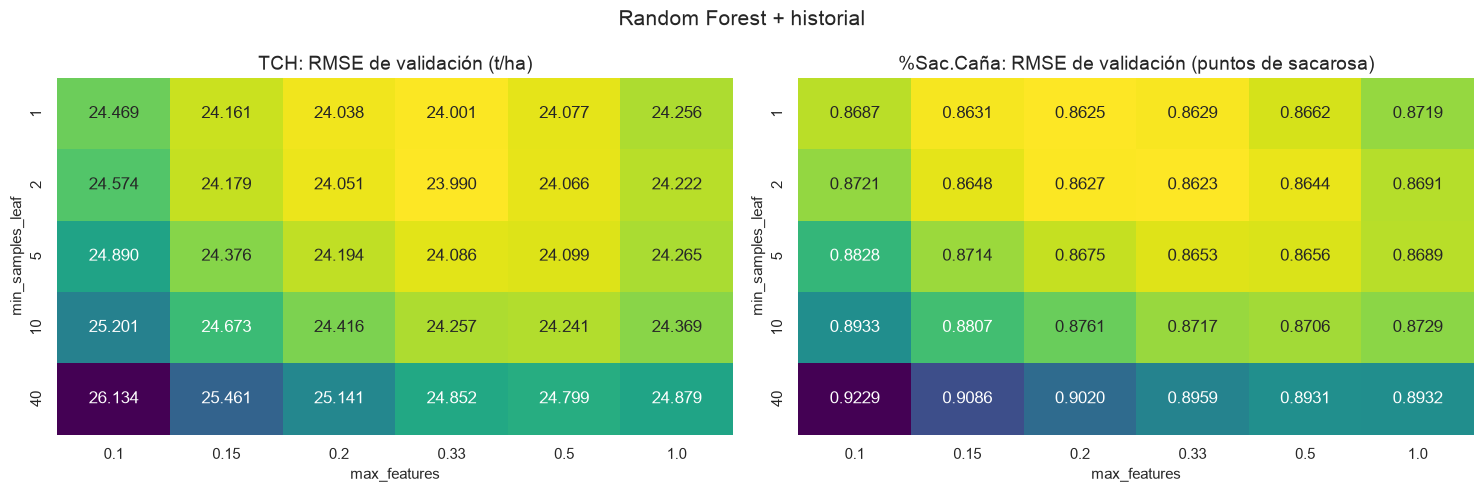

RMSE de validación según gamma (etapa 2, XGBoost con historial):


gamma,0.00,0.01,0.10,1.00,10.00,100.00
TCH,23.7747,23.7747,23.7747,23.7747,23.7726,23.7537
%Sac.Caña,0.8421,0.8421,0.8421,0.8430,0.8679,0.9405


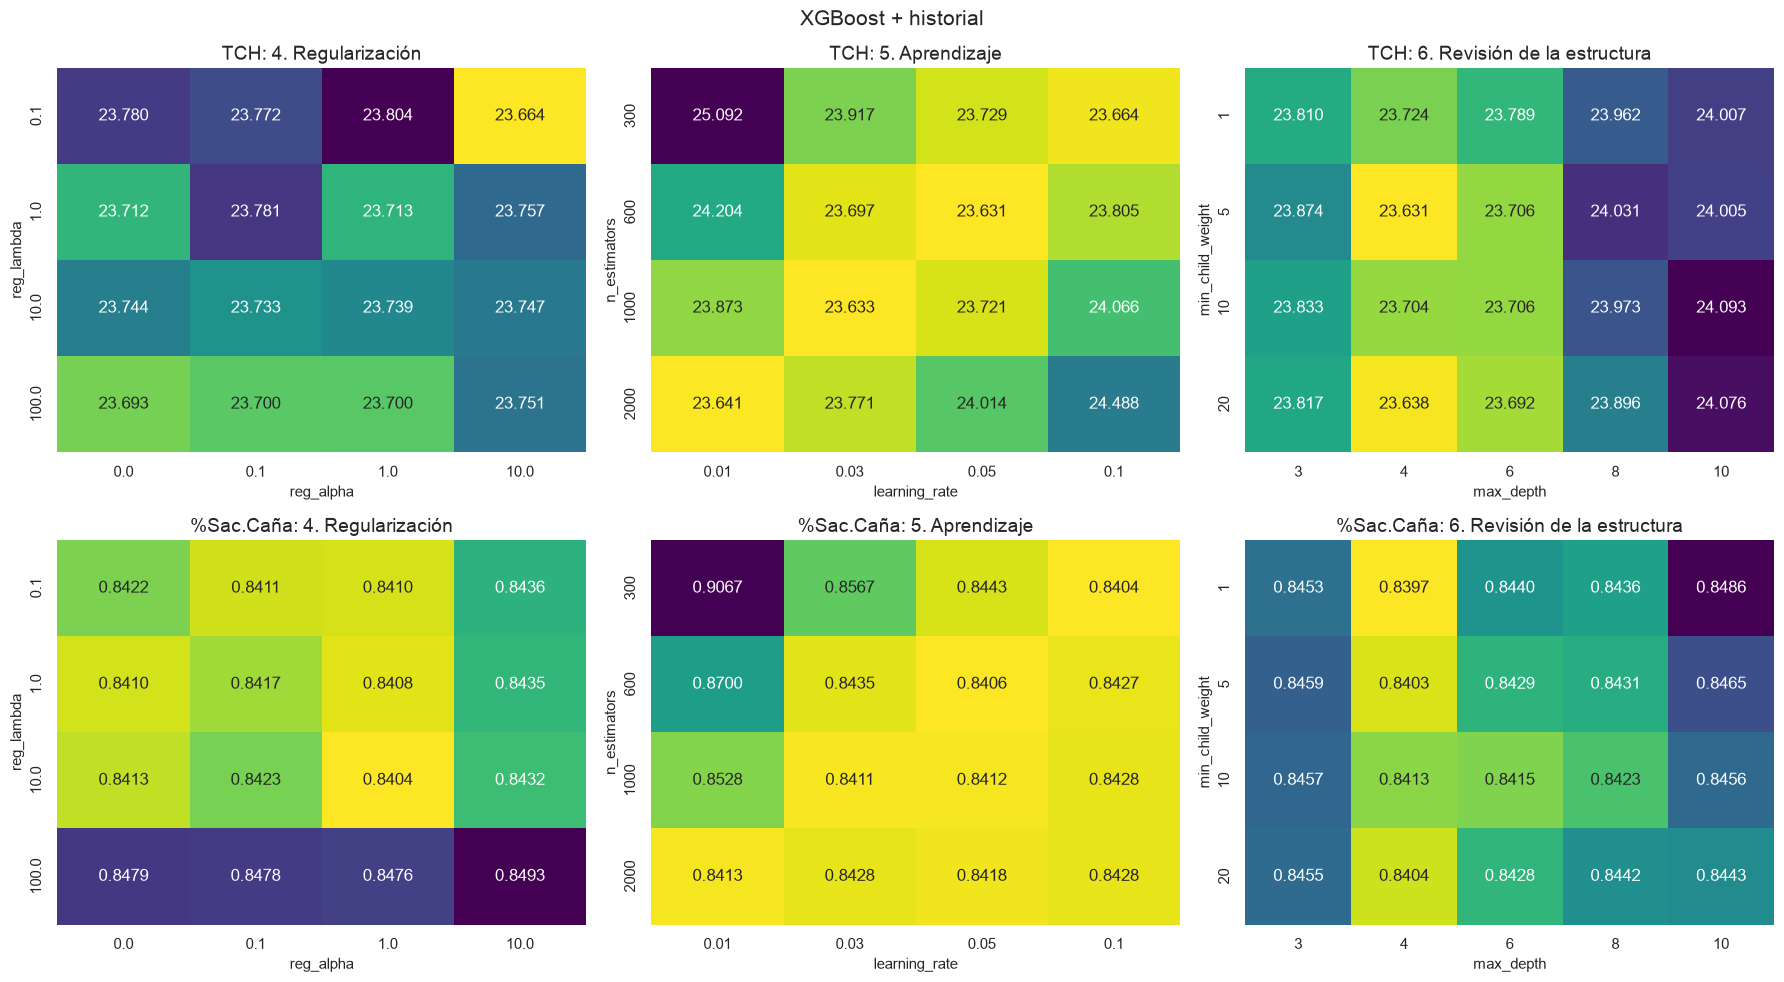

In [24]:
# 5.3 Revisión de los bordes de la grilla de los modelos con historial
def graficar_estructura_random_forest(nombre_modelo):
    """Mapa de calor del RMSE de validación de la segunda pasada de la estructura de Random Forest."""
    fig, ejes = plt.subplots(1, len(TARGETS), figsize=(15, 5))
    for eje, target in zip(ejes, TARGETS):
        resultados = detalle_busquedas[(nombre_modelo, target)]["resultados_etapas"]["4. Revisión de la estructura"]
        rmse_por_estructura = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
            index="param_modelo__min_samples_leaf", columns="param_modelo__max_features", values="RMSE",
        )
        sns.heatmap(rmse_por_estructura, annot=True, fmt=DECIMALES_MAPA[target], cmap="viridis_r", cbar=False, ax=eje)
        eje.set(title=f"{target}: RMSE de validación ({UNIDADES[target]})",
                xlabel="max_features", ylabel="min_samples_leaf")
    fig.suptitle(nombre_modelo, fontsize=15)
    plt.tight_layout()
    plt.show()


def graficar_etapas_xgboost(nombre_modelo):
    """Mapas de calor del RMSE de validación en las etapas de XGBoost que combinan dos hiperparámetros."""
    fig, ejes = plt.subplots(len(TARGETS), len(ETAPAS_XGBOOST_A_REVISAR), figsize=(18, 10))
    for fila, target in enumerate(TARGETS):
        resultados_etapas = detalle_busquedas[(nombre_modelo, target)]["resultados_etapas"]
        for columna, (etapa, (parametro_filas, parametro_columnas)) in enumerate(ETAPAS_XGBOOST_A_REVISAR.items()):
            resultados = resultados_etapas[etapa]
            rmse_por_combinacion = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
                index=f"param_{parametro_filas}", columns=f"param_{parametro_columnas}", values="RMSE",
            )
            eje = ejes[fila, columna]
            sns.heatmap(rmse_por_combinacion, annot=True, fmt=DECIMALES_MAPA[target], cmap="viridis_r",
                        cbar=False, ax=eje)
            eje.set(title=f"{target}: {etapa}", xlabel=parametro_columnas.removeprefix("modelo__"),
                    ylabel=parametro_filas.removeprefix("modelo__"))
    fig.suptitle(nombre_modelo, fontsize=15)
    plt.tight_layout()
    plt.show()


# Random Forest con historial: estructura de la segunda pasada
graficar_estructura_random_forest("Random Forest + historial")

# XGBoost con historial: la poda tiene un solo hiperparámetro y se muestra en una tabla
rmse_por_gamma = {}
for target in TARGETS:
    poda = detalle_busquedas[("XGBoost + historial", target)]["resultados_etapas"]["2. Poda"]
    rmse_por_gamma[target] = pd.Series(-poda["mean_test_RMSE"].to_numpy(),
                                       index=poda["param_modelo__gamma"].astype(float))
print("RMSE de validación según gamma (etapa 2, XGBoost con historial):")
display(pd.DataFrame(rmse_por_gamma).rename_axis("gamma").T.round(4))

graficar_etapas_xgboost("XGBoost + historial")

#### Decisión sobre los bordes de los modelos con historial

Ninguna de las dos grillas se amplía.

- **Random Forest con historial.** El óptimo está en el interior de la grilla. En `TCH`, `max_features` = 0.33 con hojas de dos registros da 23.990 t/ha, y con hojas de un registro 24.001; en `%Sac.Caña`, la mejor combinación (0.8623 puntos) y sus vecinas difieren en menos de una milésima.
- **XGBoost con historial, `TCH`.** El RMSE es idéntico con `gamma` entre 0 y 1 (23.775 t/ha), y baja apenas a 23.773 con 10 y a 23.754 con 100. Aunque la tendencia apunta al borde, multiplicar `gamma` por diez ganó solo 0.02 t/ha, así que extender la grilla movería el error en centésimas, frente a una variación entre pliegues del orden de 1 t/ha. En la regularización, la mejor combinación (`reg_alpha` = 10 con `reg_lambda` = 0.1, 23.664) es una celda aislada: las demás de su fila quedan entre 23.77 y 23.80, y las de su columna entre 23.75 y 23.76. Es una fluctuación, no una tendencia hacia el borde. La tasa de aprendizaje y el número de árboles forman de nuevo una diagonal plana (23.631, 23.633 y 23.641).
- **XGBoost con historial, `%Sac.Caña`.** Con `gamma` entre 0 y 0.1 el error es el mismo, y con valores mayores empeora con claridad (0.9405 con 100). La esquina elegida en la etapa de aprendizaje, 0.1 con 300 árboles (0.8404), equivale a 0.05 con 600 (0.8406).

#### Conclusión de 5.3

**El historial del lote mejora a los tres modelos en `TCH`, y poco en `%Sac.Caña`.**

| Target | Modelo | RMSE sin historial | RMSE con historial | Diferencia | Pliegues en que mejora | R² sin → con historial |
|---|---|---|---|---|---|---|
| `TCH` | Regresión lineal | 26.62 | 25.67 | −0.94 | 5 de 5 | 0.267 → 0.317 |
| | Random Forest | 25.46 | 23.99 | −1.47 | 5 de 5 | 0.329 → 0.404 |
| | XGBoost | 25.24 | 23.63 | −1.61 | 5 de 5 | 0.341 → 0.422 |
| `%Sac.Caña` | Regresión lineal | 0.930 | 0.915 | −0.015 | 5 de 5 | 0.335 → 0.356 |
| | Random Forest | 0.865 | 0.862 | −0.003 | 3 de 5 | 0.424 → 0.428 |
| | XGBoost | 0.845 | 0.840 | −0.006 | 5 de 5 | 0.450 → 0.457 |

En `TCH`, el resultado del corte anterior es la mejora más grande del notebook: baja el error de los tres modelos en todos los pliegues, es decir, en los cinco grupos de fincas. Confirma lo que sugería la autocorrelación de 4.2: cada lote tiene un nivel propio de rendimiento que los predictores originales no recogen, y el corte anterior lo resume. Los modelos de árboles aprovechan el historial más que la regresión lineal (1.5 y 1.6 t/ha frente a 0.9). Eso sugiere que su relación con el TCH no es un simple desplazamiento: depende de otras condiciones del lote, por ejemplo de si el corte anterior pertenece al mismo ciclo de cultivo o a uno previo a una renovación. Cómo lo usa cada modelo se revisa en la sección 8.

En `%Sac.Caña` la ganancia es pequeña. En Random Forest no es consistente (mejora en 3 de 5 pliegues), y en XGBoost es consistente pero de solo 0.006 puntos. Coincide con la autocorrelación débil que mostró la prueba de Durbin-Watson en 4.2: la sacarosa de un corte depende más de las condiciones del ciclo, como el madurante o la lluvia del final y el mes de cosecha, que de la historia del lote.

**Configuración de los modelos con historial.** Con el historial cambian algunas configuraciones en `TCH`. Random Forest pasa a considerar una fracción mayor de predictores en cada división (`max_features` de 0.2 a 0.33), y XGBoost usa árboles menos profundos (de 6 a 4 niveles) y una regularización distinta. Una lectura posible es que, con el nivel del lote ya resumido en una sola variable, los árboles necesitan menos divisiones para aproximarlo a partir de la zona, la distancia o el suelo. Ninguna grilla quedó limitada por sus bordes. La búsqueda tardó entre 17 y 18 minutos por target en Random Forest, y menos de 2 en XGBoost.

**Alcance.** El historial solo existe para lotes con una cosecha anterior registrada: el 27.7 % de los registros no lo tiene, sea por ser la primera aparición del lote en los datos o porque su corte anterior estaba a menos de 6 meses. La corrección de esos 19 registros cercanos no cambió la asociación con los targets, pero hace que la variable signifique lo mismo en todos los casos. En esos registros, el modelo depende solo de los demás predictores, así que en la sección 7 el error en prueba se reporta también por separado para registros con y sin historial.

### Conclusión de la sección 5

**Resumen de los modelos en validación cruzada**

| Modelo | `TCH`: RMSE (t/ha) | `TCH`: R² | `%Sac.Caña`: RMSE (puntos) | `%Sac.Caña`: R² |
|---|---|---|---|---|
| Regresión lineal | 26.62 | 0.267 | 0.930 | 0.335 |
| Random Forest | 25.46 | 0.329 | 0.865 | 0.424 |
| XGBoost | 25.24 | 0.341 | 0.845 | 0.450 |
| Regresión lineal + historial | 25.67 | 0.317 | 0.915 | 0.356 |
| Random Forest + historial | 23.99 | 0.404 | 0.862 | 0.428 |
| XGBoost + historial | **23.63** | **0.422** | **0.840** | **0.457** |

Los modelos de árboles superan a la regresión lineal en los dos targets, como anticipaban la no linealidad y las interacciones que mostraron el EDA y la sección 4. XGBoost es el mejor de los dos y, además, el más rápido de ajustar.

Las dos mejoras, la del modelo y la del historial, se suman. En `TCH` aportan cantidades parecidas: pasar de la regresión lineal a XGBoost baja el RMSE en 1.38 t/ha, y agregar el historial a XGBoost lo baja otras 1.61 t/ha. En total, el error baja de 26.62 a 23.63 t/ha (11.2 %) y el R² sube de 0.267 a 0.422. En `%Sac.Caña` casi toda la ganancia viene del modelo: XGBoost reduce el RMSE en 0.085 puntos y el historial solo en 0.006 más, para una reducción total de 9.7 %.

XGBoost con historial tiene el menor error en los dos targets, pero varias diferencias entre los mejores modelos son pequeñas frente a la variación entre pliegues. En la sección 6 se comparan pliegue a pliegue, se verifica que la ventaja de los árboles no dependa de reconocer el periodo de cosecha y se elige el modelo final de cada target.

## 6. Comparación en validación cruzada y elección del modelo

Todos los modelos se evaluaron en los mismos cinco pliegues agrupados por hacienda. Esta sección los compara en tres pasos: primero el desempeño medio y la diferencia pliegue a pliegue entre pares de modelos (6.1); después, una prueba de robustez que verifica que la ventaja de los modelos de árboles no venga de reconocer el periodo de cosecha (6.2); por último, la elección del modelo de cada target (6.3).

**Regla de elección.** Se fija antes de ver las comparaciones, para que no se acomode a los resultados:

1. El candidato es el modelo de menor RMSE medio de validación.
2. Su ventaja frente a la alternativa más simple debe ser consistente: menor error en al menos 4 de los 5 pliegues. Si no lo es, se elige la alternativa más simple. Se considera más simple el modelo lineal frente a los de árboles, el que no usa historial frente al que lo usa, porque no necesita registros del corte anterior, y XGBoost frente a Random Forest, porque se ajusta en una fracción del tiempo y la memoria.
3. La prueba de robustez de 6.2 no debe invertir la elección.

### 6.1 Desempeño y diferencias pliegue a pliegue

La tabla reúne el desempeño medio de todos los modelos, y el gráfico muestra el RMSE de cada pliegue. Como los pliegues son los mismos para todos los modelos, la diferencia entre dos modelos se puede calcular en cada pliegue. Esa diferencia varía mucho menos que el error de cada modelo por separado, porque un grupo de fincas difícil de predecir es difícil para todos los modelos. Por eso la comparación pareada distingue diferencias que las medias, con su desviación entre pliegues, no alcanzan a separar.


TCH (t/ha): media entre los 5 pliegues de validación


,RMSE,RMSE (desv.),MAE,R²,R² (desv.),RMSE de ajuste
modelo,,,,,,
Media constante,31.164,1.275,24.498,-0.005,0.004,31.218
Regresión lineal,26.616,1.288,20.510,0.267,0.021,25.934
Ridge,26.606,1.294,20.514,0.268,0.021,25.937
Lasso,26.600,1.268,20.514,0.268,0.020,25.937
Random Forest,25.464,1.532,19.482,0.329,0.030,13.249
XGBoost,25.239,1.112,19.285,0.341,0.009,18.061
Regresión lineal + historial,25.674,0.890,19.631,0.317,0.018,25.086
Random Forest + historial,23.990,1.023,18.050,0.404,0.010,11.501
XGBoost + historial,23.631,0.923,17.742,0.422,0.012,18.520



%Sac.Caña (puntos de sacarosa): media entre los 5 pliegues de validación


,RMSE,RMSE (desv.),MAE,R²,R² (desv.),RMSE de ajuste
modelo,,,,,,
Media constante,1.143,0.036,0.894,-0.002,0.003,1.145
Regresión lineal,0.930,0.026,0.716,0.335,0.055,0.919
Ridge,0.929,0.026,0.715,0.335,0.055,0.919
Lasso,0.929,0.026,0.715,0.336,0.056,0.920
Random Forest,0.865,0.029,0.658,0.424,0.051,0.494
XGBoost,0.845,0.027,0.643,0.450,0.047,0.719
Regresión lineal + historial,0.915,0.025,0.704,0.356,0.051,0.905
Random Forest + historial,0.862,0.025,0.657,0.428,0.044,0.420
XGBoost + historial,0.840,0.023,0.638,0.457,0.045,0.714


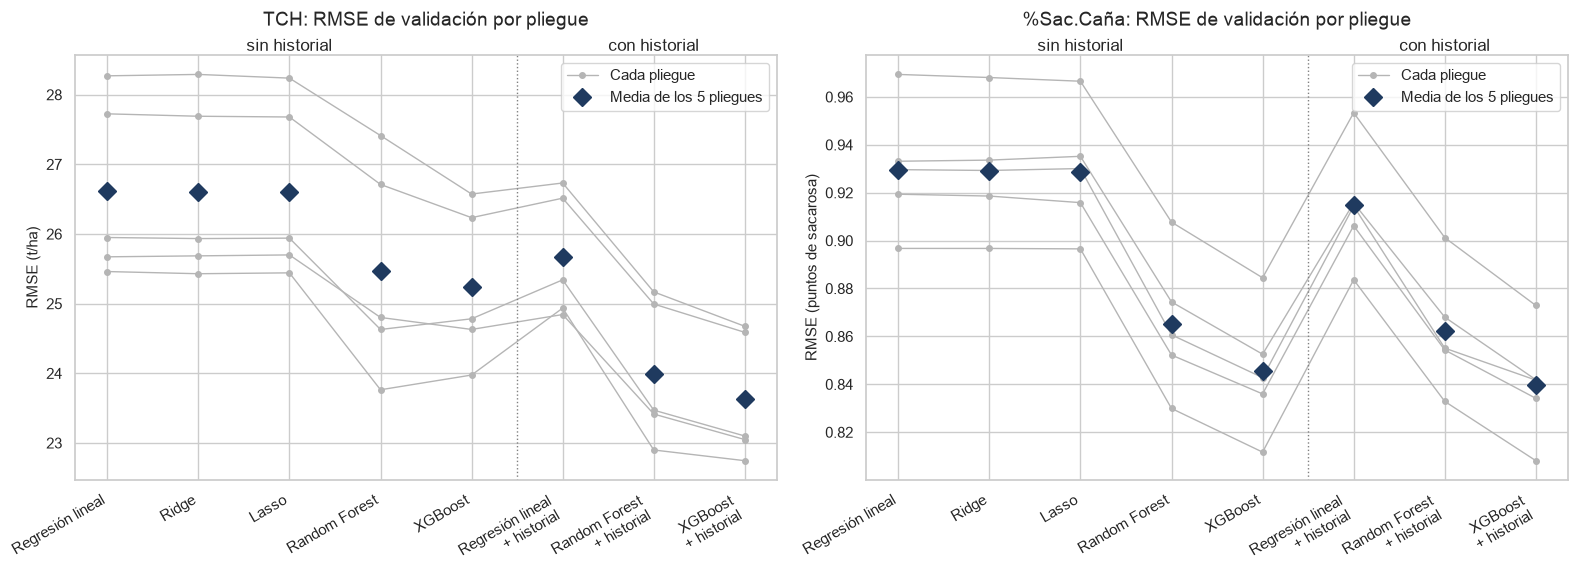

In [25]:
# 6.1 Desempeño de todos los modelos en validación cruzada
MODELOS_SIN_HISTORIAL = ["Media constante", "Regresión lineal", "Ridge", "Lasso", "Random Forest", "XGBoost"]
MODELOS_CON_HISTORIAL = ["Regresión lineal + historial", "Random Forest + historial", "XGBoost + historial"]
MODELOS_COMPARADOS = MODELOS_SIN_HISTORIAL + MODELOS_CON_HISTORIAL


def tabla_comparativa(target):
    """Media entre pliegues de cada métrica, y desviación del RMSE y del R², para todos los modelos."""
    filas = []
    for modelo in MODELOS_COMPARADOS:
        resultados = registro_cv[(modelo, target)]
        filas.append({
            "modelo": modelo,
            "RMSE": resultados["RMSE"].mean(),
            "RMSE (desv.)": resultados["RMSE"].std(),
            "MAE": resultados["MAE"].mean(),
            "R²": resultados["R2"].mean(),
            "R² (desv.)": resultados["R2"].std(),
            "RMSE de ajuste": resultados["RMSE_ajuste"].mean(),
        })
    return pd.DataFrame(filas).set_index("modelo")


for target in TARGETS:
    print(f"\n{target} ({UNIDADES[target]}): media entre los 5 pliegues de validación")
    display(tabla_comparativa(target).round(3))

# Gráfico: el RMSE de cada pliegue (una línea gris por pliegue) y la media de los cinco (rombo).
# La media constante se omite porque su error, muy superior, comprimiría la escala.
MODELOS_GRAFICO = MODELOS_COMPARADOS[1:]
n_sin_historial = len(MODELOS_SIN_HISTORIAL) - 1
posiciones = np.arange(len(MODELOS_GRAFICO))
etiquetas = [modelo.replace(" + ", "\n+ ") for modelo in MODELOS_GRAFICO]

fig, ejes = plt.subplots(1, len(TARGETS), figsize=(16, 6))
for eje, target in zip(ejes, TARGETS):
    rmse_por_pliegue = pd.DataFrame({modelo: registro_cv[(modelo, target)]["RMSE"].to_numpy() for modelo in MODELOS_GRAFICO})
    for numero_pliegue, rmse_pliegue in rmse_por_pliegue.iterrows():
        eje.plot(posiciones, rmse_pliegue.to_numpy(), color="#B5B5B5", lw=1, marker="o", ms=4, zorder=1,
                 label="Cada pliegue" if numero_pliegue == 0 else None)
    eje.plot(posiciones, rmse_por_pliegue.mean().to_numpy(), color="#1F3A5F", lw=0, marker="D", ms=9, zorder=2,
             label="Media de los 5 pliegues")
    eje.axvline(n_sin_historial - 0.5, color="gray", ls=":", lw=1)
    eje.text(n_sin_historial / 2 - 0.5, 1.01, "sin historial", transform=eje.get_xaxis_transform(), ha="center")
    eje.text(n_sin_historial + (len(MODELOS_GRAFICO) - n_sin_historial) / 2 - 0.5, 1.01, "con historial",
             transform=eje.get_xaxis_transform(), ha="center")
    eje.set_xticks(posiciones, etiquetas, rotation=30, ha="right")
    eje.set(title=f"{target}: RMSE de validación por pliegue\n", ylabel=f"RMSE ({UNIDADES[target]})")
    eje.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [26]:
# 6.1 Diferencias de RMSE pliegue a pliegue entre pares de modelos
# Cada par se lee como "modelo frente a referencia"; una diferencia negativa indica que el modelo tiene menor error
COMPARACIONES = [
    ("Random Forest", "Regresión lineal"),
    ("XGBoost", "Regresión lineal"),
    ("XGBoost", "Random Forest"),
    ("Regresión lineal + historial", "Regresión lineal"),
    ("Random Forest + historial", "Random Forest"),
    ("XGBoost + historial", "XGBoost"),
    ("XGBoost + historial", "Random Forest + historial"),
    ("XGBoost + historial", "Regresión lineal + historial"),
    ("XGBoost + historial", "Regresión lineal"),
]


def comparar_pliegue_a_pliegue(modelo, referencia, target):
    """Diferencia de RMSE (modelo menos referencia) en cada pliegue, resumida."""
    rmse_modelo = registro_cv[(modelo, target)]["RMSE"].to_numpy()
    rmse_referencia = registro_cv[(referencia, target)]["RMSE"].to_numpy()
    diferencia = rmse_modelo - rmse_referencia
    return {
        "modelo": modelo,
        "frente a": referencia,
        "diferencia media": diferencia.mean(),
        "desv. de la diferencia": diferencia.std(ddof=1),
        "diferencia relativa": f"{diferencia.mean() / rmse_referencia.mean():+.1%}",
        "pliegues en que gana": f"{(diferencia < 0).sum()} de {len(diferencia)}",
    }


for target in TARGETS:
    print(f"\n{target}: diferencia de RMSE pliegue a pliegue ({UNIDADES[target]}; negativa = menor error que la referencia)")
    comparaciones = pd.DataFrame([comparar_pliegue_a_pliegue(modelo, referencia, target)
                                  for modelo, referencia in COMPARACIONES])
    display(comparaciones.set_index(["modelo", "frente a"]).round(3))


TCH: diferencia de RMSE pliegue a pliegue (t/ha; negativa = menor error que la referencia)


diferencia media  \
modelo                       frente a                                         
Random Forest                Regresión lineal                        -1.152   
XGBoost                      Regresión lineal                        -1.377   
                             Random Forest                           -0.225   
Regresión lineal + historial Regresión lineal                        -0.942   
Random Forest + historial    Random Forest                           -1.474   
XGBoost + historial          XGBoost                                 -1.608   
                             Random Forest + historial               -0.359   
                             Regresión lineal + historial            -2.043   
                             Regresión lineal                        -2.985   

                                                           desv. de la diferencia  \
modelo                       frente a                                               
Random Forest                Regresión lineal                               0.357   
XGBoost                      Regresión lineal                               0.266   
                             Random Forest                                  0.441   
Regresión lineal + historial Regresión lineal                               0.426   
Random Forest + historial    Random Forest                                  0.532   
XGBoost + historial          XGBoost                                        0.243   
                             Random Forest + historial                      0.125   
                             Regresión lineal + historial                   0.185   
                             Regresión lineal                               0.393   

                                                          diferencia relativa  \
modelo                       frente a                                           
Random Forest                Regresión lineal                           -4.3%   
XGBoost                      Regresión lineal                           -5.2%   
                             Random Forest                              -0.9%   
Regresión lineal + historial Regresión lineal                           -3.5%   
Random Forest + historial    Random Forest                              -5.8%   
XGBoost + historial          XGBoost                                    -6.4%   
                             Random Forest + historial                  -1.5%   
                             Regresión lineal + historial               -8.0%   
                             Regresión lineal                          -11.2%   

                                                          pliegues en que gana  
modelo                       frente a                                           
Random Forest                Regresión lineal                           5 de 5  
XGBoost                      Regresión lineal                           5 de 5  
                             Random Forest                              3 de 5  
Regresión lineal + historial Regresión lineal                           5 de 5  
Random Forest + historial    Random Forest                              5 de 5  
XGBoost + historial          XGBoost                                    5 de 5  
                             Random Forest + historial                  5 de 5  
                             Regresión lineal + historial               5 de 5  
                             Regresión lineal                           5 de 5


%Sac.Caña: diferencia de RMSE pliegue a pliegue (puntos de sacarosa; negativa = menor error que la referencia)


diferencia media  \
modelo                       frente a                                         
Random Forest                Regresión lineal                        -0.065   
XGBoost                      Regresión lineal                        -0.084   
                             Random Forest                           -0.019   
Regresión lineal + historial Regresión lineal                        -0.015   
Random Forest + historial    Random Forest                           -0.003   
XGBoost + historial          XGBoost                                 -0.006   
                             Random Forest + historial               -0.023   
                             Regresión lineal + historial            -0.075   
                             Regresión lineal                        -0.090   

                                                           desv. de la diferencia  \
modelo                       frente a                                               
Random Forest                Regresión lineal                               0.004   
XGBoost                      Regresión lineal                               0.002   
                             Random Forest                                  0.003   
Regresión lineal + historial Regresión lineal                               0.002   
Random Forest + historial    Random Forest                                  0.005   
XGBoost + historial          XGBoost                                        0.005   
                             Random Forest + historial                      0.006   
                             Regresión lineal + historial                   0.003   
                             Regresión lineal                               0.004   

                                                          diferencia relativa  \
modelo                       frente a                                           
Random Forest                Regresión lineal                           -7.0%   
XGBoost                      Regresión lineal                           -9.1%   
                             Random Forest                              -2.3%   
Regresión lineal + historial Regresión lineal                           -1.6%   
Random Forest + historial    Random Forest                              -0.3%   
XGBoost + historial          XGBoost                                    -0.7%   
                             Random Forest + historial                  -2.6%   
                             Regresión lineal + historial               -8.2%   
                             Regresión lineal                           -9.7%   

                                                          pliegues en que gana  
modelo                       frente a                                           
Random Forest                Regresión lineal                           5 de 5  
XGBoost                      Regresión lineal                           5 de 5  
                             Random Forest                              5 de 5  
Regresión lineal + historial Regresión lineal                           5 de 5  
Random Forest + historial    Random Forest                              3 de 5  
XGBoost + historial          XGBoost                                    5 de 5  
                             Random Forest + historial                  5 de 5  
                             Regresión lineal + historial               5 de 5  
                             Regresión lineal                           5 de 5

#### Conclusión de 6.1

Los modelos de árboles superan a la regresión lineal en todos los pliegues y en los dos targets, y el historial del lote mejora a los tres modelos en `TCH`. El gráfico muestra además por qué la comparación pareada es necesaria: el orden de los pliegues casi no cambia entre modelos, porque un grupo de fincas difícil de predecir es difícil para todos. Por eso la diferencia entre dos modelos varía poco entre pliegues aunque el error de cada uno varíe mucho. Por ejemplo, el RMSE de XGBoost en `TCH` cambia en 1.1 t/ha de un pliegue a otro, pero su ventaja sobre la regresión lineal (1.38 t/ha) cambia apenas en 0.27.

**Aplicación de la regla de elección**

| Paso | `TCH` | `%Sac.Caña` |
|---|---|---|
| Menor RMSE medio | XGBoost + historial (23.63 t/ha) | XGBoost + historial (0.840 puntos) |
| Frente a XGBoost sin historial | −1.61 t/ha, menor error en 5 de 5 pliegues | −0.006 puntos, 5 de 5 |
| Frente a Random Forest + historial | −0.36 t/ha, 5 de 5 | −0.023 puntos, 5 de 5 |
| Frente a la regresión lineal + historial | −2.04 t/ha, 5 de 5 | −0.075 puntos, 5 de 5 |

En los dos targets, XGBoost con historial cumple los dos primeros pasos de la regla: tiene el menor error medio y su ventaja sobre cada alternativa más simple es consistente en los cinco pliegues. En `%Sac.Caña` la ventaja del historial es pequeña (0.7 %), pero no agrega un requisito operativo, porque el modelo de `TCH` ya necesita el registro del corte anterior de cada lote.

Otras comparaciones muestran lo que no es consistente. Sin historial, XGBoost y Random Forest no se distinguen en `TCH` (XGBoost tiene menor error en solo 3 de 5 pliegues), aunque XGBoost sí es mejor en `%Sac.Caña` (5 de 5). El historial no mejora de forma consistente a Random Forest en sacarosa (3 de 5). Ridge y Lasso quedan prácticamente empatados con la regresión lineal, como se vio en 4.3.

Falta el tercer paso de la regla: verificar que esta ventaja no dependa de que los pliegues comparten periodos de cosecha.

### 6.2 Robustez: validación con doble agrupación

Los pliegues de la sección 3.3 impiden que el modelo vea en el ajuste las fincas que valida, pero no impiden que vea los mismos periodos de cosecha. Una cosecha de marzo de 2022 en validación tiene, en el ajuste, cosechas de otras fincas de ese mismo mes. Un modelo flexible podría aprovechar esa coincidencia: `Año` y `Mes` identifican el periodo, y las ventanas de lluvia de fincas cercanas cosechadas el mismo mes son casi iguales. Un árbol podría aprender que en cierto periodo el rendimiento fue alto, información que no existe para cosechas futuras. La regresión lineal tiene menos capacidad para hacerlo, así que la ventaja de los árboles podría estar inflada.

Agrupar solo por año tampoco resolvería el problema, porque las fincas se repetirían entre ajuste y validación, y un modelo flexible las podría reconocer por su distancia al ingenio o por su historial. Por eso la prueba usa una **doble agrupación**: en el pliegue $k$, se valida con las fincas del pliegue $k$ de la sección 3.3 cosechadas en los años del grupo $k$, y se ajusta solo con las fincas de los demás pliegues cosechadas en los demás años. Los años se reparten en cinco grupos de tamaño parecido. Así, ninguna finca ni ningún año aparecen a la vez en ajuste y en validación.

La prueba es más exigente que la validación anterior: cada modelo se ajusta con cerca del 64 % del entrenamiento, valida en un conjunto más pequeño y debe predecir años que no vio. Se espera que el error suba en todos los modelos. Lo que importa es la **ventaja de cada modelo sobre la regresión lineal** en el mismo esquema: si se mantiene, viene de relaciones que se trasladan a fincas y años nuevos; si se reduce mucho, una parte venía de reconocer el periodo. Se evalúan los modelos con y sin historial, con los hiperparámetros elegidos en la sección 5 y sin repetir la búsqueda.

In [27]:
# 6.2 Robustez: validación cruzada con doble agrupación, por hacienda y por año de cosecha
from sklearn.base import clone

MODELOS_ROBUSTEZ = [
    "Regresión lineal", "Random Forest", "XGBoost",
    "Regresión lineal + historial", "Random Forest + historial", "XGBoost + historial",
]
RUTA_ROBUSTEZ = CARPETA_RESULTADOS / "robustez_doble_agrupacion.joblib"

# Grupo de años de cada registro de entrenamiento: los 8 años se reparten en 5 grupos de tamaño parecido
años_entrenamiento = df_train["Período"] // 100
grupo_año = pd.Series(-1, index=df_train.index, name="grupo_año")
for numero_grupo, (_, posiciones) in enumerate(GroupKFold(n_splits=N_PLIEGUES_CV).split(df_train, groups=años_entrenamiento)):
    grupo_año.iloc[posiciones] = numero_grupo


def pliegues_doble_agrupacion(datos):
    """Pliegue k: valida con las fincas del pliegue k cosechadas en los años del grupo k, y ajusta con las fincas
    de los demás pliegues cosechadas en los demás años. Ninguna finca ni ningún año se comparte."""
    grupo_finca = pliegue_por_registro.loc[datos.X_train.index].to_numpy()
    grupo_anual = grupo_año.loc[datos.X_train.index].to_numpy()
    return [(np.flatnonzero((grupo_finca != k) & (grupo_anual != k)),
             np.flatnonzero((grupo_finca == k) & (grupo_anual == k)))
            for k in range(N_PLIEGUES_CV)]


def pipeline_final(nombre_modelo, target):
    """Pipeline sin ajustar de cada modelo con su configuración final (los hiperparámetros elegidos en la sección 5)."""
    if nombre_modelo == "Regresión lineal":
        return crear_pipeline(LinearRegression())
    if nombre_modelo == "Regresión lineal + historial":
        return crear_pipeline_con_historial(LinearRegression())
    return clone(busquedas[(nombre_modelo, target)].best_estimator_)


def evaluar_doble_agrupacion():
    """RMSE, MAE y R² por pliegue de cada modelo con la doble agrupación."""
    resultados = {}
    for target in TARGETS:
        datos = datos_por_target[target]
        pliegues = pliegues_doble_agrupacion(datos)
        for nombre_modelo in MODELOS_ROBUSTEZ:
            print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target}", flush=True)
            validacion = cross_validate(pipeline_final(nombre_modelo, target), datos.X_train, datos.y_train,
                                        cv=pliegues, scoring=METRICAS_CV, n_jobs=PROCESOS_RANDOM_FOREST)
            resultados[(nombre_modelo, target)] = pd.DataFrame({
                "RMSE": -validacion["test_RMSE"], "MAE": -validacion["test_MAE"], "R2": validacion["test_R2"],
            })
    return resultados


# Verificación de los pliegues: sin fincas ni años compartidos entre ajuste y validación
filas_pliegues = []
for target, datos in datos_por_target.items():
    haciendas = datos.haciendas_train.to_numpy()
    años = años_entrenamiento.loc[datos.X_train.index].to_numpy()
    for k, (ajuste, validacion) in enumerate(pliegues_doble_agrupacion(datos)):
        assert set(haciendas[ajuste]).isdisjoint(haciendas[validacion]), f"{target}: fincas compartidas en el pliegue {k}"
        assert set(años[ajuste]).isdisjoint(años[validacion]), f"{target}: años compartidos en el pliegue {k}"
        filas_pliegues.append({"target": target, "pliegue": k, "registros de ajuste": len(ajuste),
                               "registros de validación": len(validacion),
                               "años de validación": ", ".join(map(str, sorted(set(años[validacion]))))})
print("Pliegues con doble agrupación:")
display(pd.DataFrame(filas_pliegues).set_index(["target", "pliegue"]))

# Resultados guardados: la evaluación ajusta 60 modelos y tarda varios minutos
guardado = None
if RUTA_ROBUSTEZ.exists() and not RECALCULAR_BUSQUEDAS:
    try:
        guardado = joblib.load(RUTA_ROBUSTEZ)
    except Exception as error:  # archivo dañado o de otra versión de las librerías
        print(f"No se pudo leer {RUTA_ROBUSTEZ} ({type(error).__name__}); la evaluación se repite.")
if isinstance(guardado, dict) and guardado.get("modelos") == MODELOS_ROBUSTEZ:
    resultados_robustez = guardado["resultados"]
    print(f"\nResultados cargados de {RUTA_ROBUSTEZ}")
else:
    resultados_robustez = evaluar_doble_agrupacion()
    guardar_busqueda(RUTA_ROBUSTEZ, {"modelos": MODELOS_ROBUSTEZ, "resultados": resultados_robustez})

# Ventaja de cada modelo sobre la regresión lineal sin historial, en cada esquema de validación
for target in TARGETS:
    filas = []
    for nombre_modelo in MODELOS_ROBUSTEZ:
        rmse_hacienda = registro_cv[(nombre_modelo, target)]["RMSE"].to_numpy()
        rmse_doble = resultados_robustez[(nombre_modelo, target)]["RMSE"].to_numpy()
        ventaja_hacienda = registro_cv[("Regresión lineal", target)]["RMSE"].to_numpy() - rmse_hacienda
        ventaja_doble = resultados_robustez[("Regresión lineal", target)]["RMSE"].to_numpy() - rmse_doble
        filas.append({
            "modelo": nombre_modelo,
            "RMSE (hacienda)": rmse_hacienda.mean(),
            "RMSE (doble)": rmse_doble.mean(),
            "R² (hacienda)": registro_cv[(nombre_modelo, target)]["R2"].mean(),
            "R² (doble)": resultados_robustez[(nombre_modelo, target)]["R2"].mean(),
            "ventaja sobre la lineal (hacienda)": ventaja_hacienda.mean(),
            "ventaja sobre la lineal (doble)": ventaja_doble.mean(),
            "pliegues en que gana (doble)": f"{(ventaja_doble > 0).sum()} de {len(ventaja_doble)}",
        })
    print(f"\n{target} ({UNIDADES[target]}): validación agrupada por hacienda frente a doble agrupación")
    display(pd.DataFrame(filas).set_index("modelo").round(3))

Pliegues con doble agrupación:


registros de ajuste  registros de validación  \
target    pliegue                                                 
TCH       0                      11140                      494   
          1                      11519                      415   
          2                       9860                      872   
          3                      10232                      740   
          4                       9773                      782   
%Sac.Caña 0                      11048                      494   
          1                      11454                      412   
          2                       9839                      852   
          3                      10108                      748   
          4                       9732                      778   

                  años de validación  
target    pliegue                     
TCH       0                     2023  
          1                     2018  
          2               2022, 2024  
          3               2019, 2021  
          4               2017, 2020  
%Sac.Caña 0                     2023  
          1                     2018  
          2               2022, 2024  
          3               2019, 2021  
          4               2017, 2020


Resultados cargados de resultados/robustez_doble_agrupacion.joblib

TCH (t/ha): validación agrupada por hacienda frente a doble agrupación


,RMSE (hacienda),RMSE (doble),R² (hacienda),R² (doble),ventaja sobre la lineal (hacienda),ventaja sobre la lineal (doble),pliegues en que gana (doble)
modelo,,,,,,,
Regresión lineal,26.616,27.305,0.267,0.180,0.000,0.000,0 de 5
Random Forest,25.464,27.126,0.329,0.186,1.152,0.179,3 de 5
XGBoost,25.239,27.258,0.341,0.180,1.377,0.047,3 de 5
Regresión lineal + historial,25.674,26.895,0.317,0.203,0.942,0.411,4 de 5
Random Forest + historial,23.990,26.266,0.404,0.237,2.626,1.039,4 de 5
XGBoost + historial,23.631,26.295,0.422,0.239,2.985,1.010,5 de 5



%Sac.Caña (puntos de sacarosa): validación agrupada por hacienda frente a doble agrupación


,RMSE (hacienda),RMSE (doble),R² (hacienda),R² (doble),ventaja sobre la lineal (hacienda),ventaja sobre la lineal (doble),pliegues en que gana (doble)
modelo,,,,,,,
Regresión lineal,0.930,0.932,0.335,0.283,0.000,0.000,0 de 5
Random Forest,0.865,0.918,0.424,0.307,0.065,0.014,4 de 5
XGBoost,0.845,0.918,0.450,0.307,0.084,0.014,4 de 5
Regresión lineal + historial,0.915,0.920,0.356,0.306,0.015,0.012,3 de 5
Random Forest + historial,0.862,0.914,0.428,0.314,0.067,0.018,4 de 5
XGBoost + historial,0.840,0.915,0.457,0.315,0.090,0.018,4 de 5


#### Lectura de la doble agrupación

Con la doble agrupación el error sube en todos los modelos, como se esperaba: en `TCH`, el R² de la regresión lineal baja de 0.267 a 0.180. Pero la ventaja de los modelos de árboles cae mucho más que el error de la regresión lineal:

- **`TCH` sin historial.** La ventaja sobre la regresión lineal pasa de 1.15 a 0.18 t/ha en Random Forest y de 1.38 a 0.05 t/ha en XGBoost, y ya no es consistente (menor error en 3 de 5 pliegues).
- **`TCH` con historial.** La ventaja se reduce, pero se mantiene: 1.04 t/ha en Random Forest (4 de 5 pliegues) y 1.01 t/ha en XGBoost (5 de 5). La regresión lineal con historial conserva una ventaja de 0.41 t/ha (4 de 5).
- **`%Sac.Caña`.** La ventaja de los árboles baja de 0.065–0.090 a 0.014–0.018 puntos, pero sigue siendo consistente (4 de 5 pliegues).

Con historial, Random Forest y XGBoost quedan prácticamente empatados (26.27 y 26.30 t/ha en `TCH`; 0.914 y 0.915 puntos en `%Sac.Caña`).

La doble agrupación cambia tres cosas a la vez, y cualquiera de ellas podría perjudicar más a los árboles que a la regresión lineal:

1. **Ya no se comparten periodos** entre ajuste y validación. Es el efecto que se quiere medir.
2. **Cada modelo se ajusta con menos datos**, cerca del 64 % del entrenamiento, y los modelos flexibles suelen necesitar más datos que uno lineal.
3. **Algunos años de validación quedan fuera del rango del ajuste** (2017 y 2024). La regresión lineal extrapola la tendencia del año, mientras que un árbol deja constante su predicción más allá del último año visto.

Para separar el primer efecto del segundo se hace un experimento de control: se valida con los mismos registros de la doble agrupación, pero el ajuste usa registros de las demás fincas de **todos** los años, tomados al azar hasta igualar el tamaño del ajuste de la doble agrupación. Si en el control la ventaja de los árboles vuelve a ser alta, la caída se debe a que ya no se comparten periodos; si sigue siendo baja, se debe al menor tamaño del ajuste o a la dificultad de esos registros.

In [28]:
# 6.2 Control: mismos registros de validación, ajuste del mismo tamaño pero con todos los años de las demás fincas
RUTA_CONTROL = CARPETA_RESULTADOS / "robustez_control_tamano.joblib"


def pliegues_control_tamano(datos):
    """Misma validación que la doble agrupación. El ajuste toma, al azar, registros de las demás fincas de todos los
    años, en el mismo número que el ajuste de la doble agrupación: solo cambia que ahora sí se comparten periodos."""
    grupo_finca = pliegue_por_registro.loc[datos.X_train.index].to_numpy()
    generador = np.random.default_rng(RANDOM_STATE)
    pliegues = []
    for k, (ajuste_doble, validacion) in enumerate(pliegues_doble_agrupacion(datos)):
        candidatos = np.flatnonzero(grupo_finca != k)
        ajuste = np.sort(generador.choice(candidatos, size=len(ajuste_doble), replace=False))
        pliegues.append((ajuste, validacion))
    return pliegues


def evaluar_esquema(funcion_pliegues):
    """RMSE, MAE y R² por pliegue de cada modelo de MODELOS_ROBUSTEZ con los pliegues que genera funcion_pliegues."""
    resultados = {}
    for target in TARGETS:
        datos = datos_por_target[target]
        pliegues = funcion_pliegues(datos)
        for nombre_modelo in MODELOS_ROBUSTEZ:
            print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target}", flush=True)
            validacion = cross_validate(pipeline_final(nombre_modelo, target), datos.X_train, datos.y_train,
                                        cv=pliegues, scoring=METRICAS_CV, n_jobs=PROCESOS_RANDOM_FOREST)
            resultados[(nombre_modelo, target)] = pd.DataFrame({
                "RMSE": -validacion["test_RMSE"], "MAE": -validacion["test_MAE"], "R2": validacion["test_R2"],
            })
    return resultados


# Verificación: misma validación que la doble agrupación, mismo tamaño de ajuste y sin fincas compartidas
for target, datos in datos_por_target.items():
    haciendas = datos.haciendas_train.to_numpy()
    for (ajuste_control, validacion_control), (ajuste_doble, validacion_doble) in zip(
            pliegues_control_tamano(datos), pliegues_doble_agrupacion(datos)):
        assert np.array_equal(validacion_control, validacion_doble)
        assert len(ajuste_control) == len(ajuste_doble)
        assert set(haciendas[ajuste_control]).isdisjoint(haciendas[validacion_control])

guardado = None
if RUTA_CONTROL.exists() and not RECALCULAR_BUSQUEDAS:
    try:
        guardado = joblib.load(RUTA_CONTROL)
    except Exception as error:  # archivo dañado o de otra versión de las librerías
        print(f"No se pudo leer {RUTA_CONTROL} ({type(error).__name__}); la evaluación se repite.")
if isinstance(guardado, dict) and guardado.get("modelos") == MODELOS_ROBUSTEZ:
    resultados_control = guardado["resultados"]
    print(f"Resultados cargados de {RUTA_CONTROL}")
else:
    resultados_control = evaluar_esquema(pliegues_control_tamano)
    guardar_busqueda(RUTA_CONTROL, {"modelos": MODELOS_ROBUSTEZ, "resultados": resultados_control})


def ventaja_sobre_lineal(resultados, nombre_modelo, target):
    """RMSE de la regresión lineal menos RMSE del modelo, en cada pliegue (positiva = el modelo tiene menor error)."""
    return (resultados[("Regresión lineal", target)]["RMSE"].to_numpy()
            - resultados[(nombre_modelo, target)]["RMSE"].to_numpy())


# Ventaja sobre la regresión lineal en los tres esquemas
ESQUEMAS = {"hacienda": registro_cv, "control": resultados_control, "doble": resultados_robustez}
for target in TARGETS:
    filas = []
    for nombre_modelo in MODELOS_ROBUSTEZ[1:]:
        fila = {"modelo": nombre_modelo}
        for esquema, resultados in ESQUEMAS.items():
            ventaja = ventaja_sobre_lineal(resultados, nombre_modelo, target)
            fila[f"ventaja ({esquema})"] = ventaja.mean()
            fila[f"gana ({esquema})"] = f"{(ventaja > 0).sum()} de {len(ventaja)}"
        filas.append(fila)
    print(f"\n{target}: ventaja sobre la regresión lineal ({UNIDADES[target]}; positiva = menor error que la lineal)")
    display(pd.DataFrame(filas).set_index("modelo").round(3))

# Comparación directa de los dos mejores modelos en cada esquema
print("\nXGBoost + historial frente a Random Forest + historial (diferencia de RMSE; negativa = XGBoost tiene menor error):")
filas = []
for target in TARGETS:
    for esquema, resultados in ESQUEMAS.items():
        diferencia = (resultados[("XGBoost + historial", target)]["RMSE"].to_numpy()
                      - resultados[("Random Forest + historial", target)]["RMSE"].to_numpy())
        filas.append({"target": target, "esquema": esquema, "diferencia media": diferencia.mean(),
                      "pliegues en que XGBoost gana": f"{(diferencia < 0).sum()} de {len(diferencia)}"})
display(pd.DataFrame(filas).set_index(["target", "esquema"]).round(3))

Resultados cargados de resultados/robustez_control_tamano.joblib

TCH: ventaja sobre la regresión lineal (t/ha; positiva = menor error que la lineal)


,ventaja (hacienda),gana (hacienda),ventaja (control),gana (control),ventaja (doble),gana (doble)
modelo,,,,,,
Random Forest,1.152,5 de 5,0.847,5 de 5,0.179,3 de 5
XGBoost,1.377,5 de 5,0.878,5 de 5,0.047,3 de 5
Regresión lineal + historial,0.942,5 de 5,0.734,5 de 5,0.411,4 de 5
Random Forest + historial,2.626,5 de 5,2.167,5 de 5,1.039,4 de 5
XGBoost + historial,2.985,5 de 5,2.349,5 de 5,1.010,5 de 5



%Sac.Caña: ventaja sobre la regresión lineal (puntos de sacarosa; positiva = menor error que la lineal)


,ventaja (hacienda),gana (hacienda),ventaja (control),gana (control),ventaja (doble),gana (doble)
modelo,,,,,,
Random Forest,0.065,5 de 5,0.056,5 de 5,0.014,4 de 5
XGBoost,0.084,5 de 5,0.075,5 de 5,0.014,4 de 5
Regresión lineal + historial,0.015,5 de 5,0.014,4 de 5,0.012,3 de 5
Random Forest + historial,0.067,5 de 5,0.058,5 de 5,0.018,4 de 5
XGBoost + historial,0.090,5 de 5,0.080,5 de 5,0.018,4 de 5



XGBoost + historial frente a Random Forest + historial (diferencia de RMSE; negativa = XGBoost tiene menor error):


diferencia media pliegues en que XGBoost gana
target    esquema                                                
TCH       hacienda            -0.359                       5 de 5
          control             -0.183                       3 de 5
          doble                0.029                       3 de 5
%Sac.Caña hacienda            -0.023                       5 de 5
          control             -0.023                       5 de 5
          doble                0.000                       4 de 5

#### Lectura del control

El control deja casi intacta la ventaja de los árboles. Con el mismo tamaño de ajuste y los mismos registros de validación que la doble agrupación, pero compartiendo años, XGBoost conserva en `TCH` una ventaja de 0.88 t/ha sobre la regresión lineal (frente a 1.38 en la validación por hacienda), Random Forest una de 0.85, y los dos tienen menor error en los cinco pliegues. En `%Sac.Caña` la ventaja de XGBoost apenas baja, de 0.084 a 0.075 puntos. El menor tamaño del ajuste explica, por tanto, solo una parte pequeña de la caída. La mayor parte ocurre al pasar del control a la doble agrupación, es decir, cuando el ajuste deja de incluir cosechas de los mismos años que se validan: en `TCH` la ventaja de XGBoost cae de 0.88 a 0.05 t/ha.

Eso deja dos explicaciones: que los árboles aprovechen condiciones propias de cada periodo, comunes a todas las fincas, o que pierdan precisión en los años que quedan fuera del rango del ajuste (2017 y 2024), donde no pueden extrapolar la tendencia. Se pueden separar mirando la ventaja en cada pliegue: tres de ellos validan solo años interiores (2018, 2023, y 2019 con 2021), donde no hay extrapolación. En la misma tabla se compara, pliegue a pliegue, XGBoost con historial frente a la regresión lineal con historial, el modelo más simple que también aprovecha el corte anterior.

In [29]:
# 6.2 Ventaja por pliegue con doble agrupación, según los años que valida cada pliegue
for target in TARGETS:
    datos = datos_por_target[target]
    años = años_entrenamiento.loc[datos.X_train.index].to_numpy()
    años_por_pliegue = [", ".join(map(str, sorted(set(años[validacion]))))
                        for _, validacion in pliegues_doble_agrupacion(datos)]
    rmse_lineal_historial = resultados_robustez[("Regresión lineal + historial", target)]["RMSE"].to_numpy()
    rmse_xgboost_historial = resultados_robustez[("XGBoost + historial", target)]["RMSE"].to_numpy()

    tabla_pliegues = pd.DataFrame({
        "años de validación": años_por_pliegue,
        "XGBoost (control)": ventaja_sobre_lineal(resultados_control, "XGBoost", target),
        "XGBoost (doble)": ventaja_sobre_lineal(resultados_robustez, "XGBoost", target),
        "XGBoost + historial (doble)": ventaja_sobre_lineal(resultados_robustez, "XGBoost + historial", target),
        "lineal + historial (doble)": ventaja_sobre_lineal(resultados_robustez, "Regresión lineal + historial", target),
        "XGBoost + historial frente a lineal + historial (doble)": rmse_lineal_historial - rmse_xgboost_historial,
    }).rename_axis("pliegue")
    print(f"\n{target}: ventaja sobre la regresión lineal en cada pliegue ({UNIDADES[target]}; positiva = menor error)")
    display(tabla_pliegues.round(3))


TCH: ventaja sobre la regresión lineal en cada pliegue (t/ha; positiva = menor error)


,años de validación,XGBoost (control),XGBoost (doble),XGBoost + historial (doble),lineal + historial (doble),XGBoost + historial frente a lineal + historial (doble)
pliegue,,,,,,
0,2023,0.012,-0.896,0.840,0.040,0.800
1,2018,1.782,0.218,1.103,0.601,0.502
2,"2022, 2024",0.816,-0.643,0.547,1.265,-0.718
3,"2019, 2021",1.029,0.573,1.936,0.252,1.684
4,"2017, 2020",0.751,0.983,0.626,-0.104,0.730



%Sac.Caña: ventaja sobre la regresión lineal en cada pliegue (puntos de sacarosa; positiva = menor error)


,años de validación,XGBoost (control),XGBoost (doble),XGBoost + historial (doble),lineal + historial (doble),XGBoost + historial frente a lineal + historial (doble)
pliegue,,,,,,
0,2023,0.073,-0.023,-0.023,-0.019,-0.004
1,2018,0.103,0.021,0.048,0.044,0.004
2,"2022, 2024",0.070,0.033,0.012,0.011,0.001
3,"2019, 2021",0.075,0.015,0.013,-0.005,0.018
4,"2017, 2020",0.052,0.023,0.038,0.029,0.009


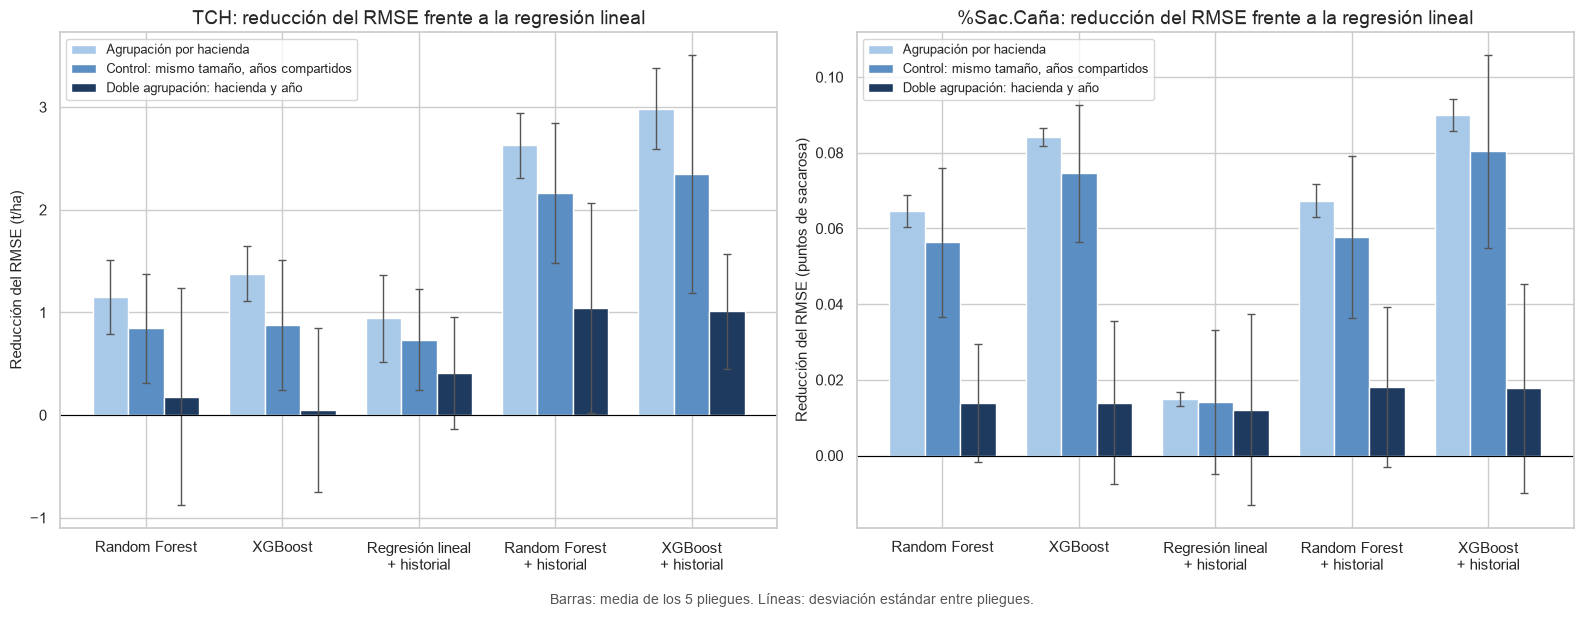

In [30]:
# 6.2 Resumen gráfico: ventaja de cada modelo sobre la regresión lineal en los tres esquemas de validación
MODELOS_VENTAJA = MODELOS_ROBUSTEZ[1:]  # todos menos la regresión lineal, que es la referencia
# Un solo tono, de claro a oscuro según qué tan exigente es el esquema
COLORES_ESQUEMA = {"hacienda": "#A9C9E8", "control": "#5B8FC4", "doble": "#1F3A5F"}
NOMBRES_ESQUEMA = {
    "hacienda": "Agrupación por hacienda",
    "control": "Control: mismo tamaño, años compartidos",
    "doble": "Doble agrupación: hacienda y año",
}
ANCHO_BARRA = 0.26

posiciones = np.arange(len(MODELOS_VENTAJA))
fig, ejes = plt.subplots(1, len(TARGETS), figsize=(16, 6))
for eje, target in zip(ejes, TARGETS):
    for desplazamiento, (esquema, resultados) in zip((-1, 0, 1), ESQUEMAS.items()):
        ventajas = [ventaja_sobre_lineal(resultados, nombre_modelo, target) for nombre_modelo in MODELOS_VENTAJA]
        eje.bar(posiciones + desplazamiento * ANCHO_BARRA, [ventaja.mean() for ventaja in ventajas],
                width=ANCHO_BARRA, color=COLORES_ESQUEMA[esquema], edgecolor="white", linewidth=1,
                yerr=[ventaja.std(ddof=1) for ventaja in ventajas], capsize=3,
                error_kw={"elinewidth": 1, "ecolor": "#555555"}, label=NOMBRES_ESQUEMA[esquema])
    eje.axhline(0, color="black", lw=0.8)
    eje.set_xticks(posiciones, [nombre_modelo.replace(" + ", "\n+ ") for nombre_modelo in MODELOS_VENTAJA])
    eje.set(title=f"{target}: reducción del RMSE frente a la regresión lineal",
            ylabel=f"Reducción del RMSE ({UNIDADES[target]})")
    eje.legend(fontsize=9, loc="upper left")
fig.text(0.5, -0.02, "Barras: media de los 5 pliegues. Líneas: desviación estándar entre pliegues.",
         ha="center", fontsize=10, color="#555555")
plt.tight_layout()
plt.show()

#### Conclusión de 6.2

La figura resume la prueba. En cada modelo, las dos barras claras (agrupación por hacienda y control) son parecidas, mientras que la oscura (doble agrupación) es mucho más baja. Es decir, la ventaja sobre la regresión lineal casi no cambia al reducir el tamaño del ajuste, pero cae al dejar de compartir años. Sin historial, la barra oscura de `TCH` queda prácticamente en cero, con una variación entre pliegues que cruza el cero de lado a lado. Con historial, se mantiene en alrededor de 1 t/ha. En `%Sac.Caña` todas las barras oscuras bajan a una fracción de las claras, salvo la de la regresión lineal con historial, cuya ventaja era pequeña desde el principio.

**La ventaja de los árboles sin historial depende de compartir años.** En `TCH`, la ventaja de XGBoost sobre la regresión lineal cae también en los pliegues que validan solo años interiores, donde no hay que extrapolar: de 0.01 a −0.90 t/ha en 2023, de 1.78 a 0.22 en 2018 y de 1.03 a 0.57 en 2019 y 2021. En cambio, en el pliegue que valida 2017 y 2020, que incluye el primer año del histórico, la ventaja sube. La caída no se debe a los años fuera de rango ni al menor tamaño del ajuste: aparece cuando el ajuste deja de incluir cosechas de los mismos años que se validan. Los árboles aprovechan condiciones propias de cada año que afectan a todas las fincas a la vez y que el histórico no registra de forma explícita, como la temperatura, la radiación o la distribución de la lluvia dentro de los meses; `Año` y `Mes` les permiten reconocer el periodo y asignarle su nivel. La regresión lineal solo representa una tendencia anual y un efecto por mes, y no puede aprender esos choques de cada año. Para predecir un año que no está en los datos, esa información no existe.

**El historial del lote sí se traslada a fincas y años nuevos.** Con doble agrupación, XGBoost con historial conserva en `TCH` una ventaja de 1.01 t/ha sobre la regresión lineal (5 de 5 pliegues), y de 0.60 t/ha sobre la regresión lineal con historial (4 de 5). En `%Sac.Caña` la ventaja de todos los modelos sobre la regresión lineal se reduce a 0.014–0.018 puntos, pequeña pero consistente en 4 de 5 pliegues.

**Qué significa para la evaluación.** Los dos esquemas responden preguntas distintas:

| Esquema | Pregunta | `TCH`: R² de XGBoost + historial | `%Sac.Caña`: R² de XGBoost + historial |
|---|---|---|---|
| Agrupación por hacienda | ¿Qué tan bien predice fincas nuevas en años con cosechas conocidas? | 0.422 | 0.457 |
| Doble agrupación | ¿Qué tan bien predice fincas nuevas en años sin cosechas conocidas? | 0.239 | 0.315 |

El primer escenario corresponde, por ejemplo, a estimar las cosechas que faltan de una zafra en curso, cuando ya se conocen las de otras fincas. El segundo, a pronosticar una zafra futura. El conjunto de prueba de la sección 7 se separó por hacienda y comparte años con el entrenamiento, así que su error corresponde al primer escenario; para el segundo, la referencia es la doble agrupación.

Los hiperparámetros de la sección 5 se eligieron con la validación por hacienda, que favorece a los modelos capaces de aprovechar el periodo. Una búsqueda con doble agrupación podría preferir árboles más suaves, más adecuados para años nuevos; queda como una línea de trabajo futuro.

### 6.3 Elección del modelo

| Paso de la regla | `TCH` | `%Sac.Caña` |
|---|---|---|
| 1. Menor RMSE medio (agrupación por hacienda) | XGBoost + historial | XGBoost + historial |
| 2. Ventaja consistente frente a las alternativas más simples | Sí: 5 de 5 pliegues frente a XGBoost sin historial, Random Forest con historial y la regresión lineal con historial | Sí: 5 de 5 pliegues frente a las mismas alternativas |
| 3. La prueba de robustez no invierte la elección | No la invierte: Random Forest con historial no le gana de forma consistente (XGBoost gana en 3 de 5 pliegues), y la ventaja sobre la regresión lineal con historial se mantiene en 4 de 5 | No la invierte: frente a Random Forest con historial el resultado es un empate (diferencia media de 0.000), y frente a la regresión lineal con historial XGBoost gana en 3 de 5 pliegues por 0.006 puntos |

El modelo elegido para los dos targets es **XGBoost con historial del lote**. En `TCH`, la elección es clara en los dos esquemas de validación. En `%Sac.Caña`, el modelo es el mejor con la agrupación por hacienda, pero con doble agrupación su ventaja sobre las alternativas es mínima; se mantiene porque usa los mismos datos que el modelo de `TCH` y porque, a igual desempeño, XGBoost se ajusta en una fracción del tiempo y la memoria de Random Forest.

In [31]:
# 6.3 Modelo elegido para cada target según la regla de elección; las secciones 7 y 8 parten de esta elección
MODELO_ELEGIDO = {"TCH": "XGBoost + historial", "%Sac.Caña": "XGBoost + historial"}

for target, nombre_modelo in MODELO_ELEGIDO.items():
    hacienda = registro_cv[(nombre_modelo, target)]
    doble = resultados_robustez[(nombre_modelo, target)]
    print(f"{target}: {nombre_modelo}")
    print(f"  Validación por hacienda: RMSE = {hacienda['RMSE'].mean():.3f} ± {hacienda['RMSE'].std():.3f} | "
          f"MAE = {hacienda['MAE'].mean():.3f} | R² = {hacienda['R2'].mean():.3f}")
    print(f"  Doble agrupación:        RMSE = {doble['RMSE'].mean():.3f} ± {doble['RMSE'].std():.3f} | "
          f"MAE = {doble['MAE'].mean():.3f} | R² = {doble['R2'].mean():.3f}")
    print(f"  Configuración: {detalle_busquedas[(nombre_modelo, target)]['configuracion']}")

TCH: XGBoost + historial
  Validación por hacienda: RMSE = 23.631 ± 0.923 | MAE = 17.742 | R² = 0.422
  Doble agrupación:        RMSE = 26.295 ± 1.723 | MAE = 20.017 | R² = 0.239
  Configuración: {'max_depth': 4, 'min_child_weight': 5, 'gamma': 100, 'colsample_bytree': 1.0, 'subsample': 0.8, 'reg_alpha': 10, 'reg_lambda': 0.1, 'learning_rate': 0.05, 'n_estimators': 600}
%Sac.Caña: XGBoost + historial
  Validación por hacienda: RMSE = 0.840 ± 0.023 | MAE = 0.638 | R² = 0.457
  Doble agrupación:        RMSE = 0.915 ± 0.053 | MAE = 0.711 | R² = 0.315
  Configuración: {'max_depth': 4, 'min_child_weight': 1, 'gamma': 0.1, 'colsample_bytree': 0.7, 'subsample': 1.0, 'reg_alpha': 1, 'reg_lambda': 10, 'learning_rate': 0.1, 'n_estimators': 300}


### Conclusión de la sección 6

La comparación pareada en los mismos pliegues permite distinguir diferencias que las medias no separan, porque un grupo de fincas difícil lo es para todos los modelos. Con la validación agrupada por hacienda, los modelos de árboles superan a la regresión lineal en todos los pliegues, y el historial del lote los mejora en `TCH`. XGBoost con historial es el mejor modelo para los dos targets: reduce el RMSE de la regresión lineal en 11.2 % en `TCH` y en 9.7 % en `%Sac.Caña`.

La prueba de robustez mostró que buena parte de esa ventaja depende de que el ajuste incluya cosechas de los mismos años que se predicen. Para fincas nuevas en años sin cosechas conocidas, la ventaja de los árboles sin historial casi desaparece en `TCH` y se reduce mucho en `%Sac.Caña`. La mejora que sí se traslada es la del historial del lote, que mantiene a XGBoost con historial como el mejor modelo también en ese escenario.

El modelo elegido se evalúa en la sección 7 sobre el conjunto de prueba, junto con los demás modelos para comparar. Ese error corresponde a fincas nuevas en años conocidos, y se lee junto con el de la doble agrupación como referencia para años futuros.

## 7. Evaluación en el conjunto de prueba

El conjunto de prueba, separado en la sección 3, no se ha usado en ninguna decisión: ni en la búsqueda de hiperparámetros, ni en la comparación, ni en la elección del modelo. Aquí se usa una sola vez y no se cambia nada después de ver los resultados.

Se evalúan todos los modelos, no solo el elegido, para comprobar si el orden de la validación cruzada se mantiene en datos nuevos. Los modelos con hiperparámetros ya están reajustados con todo el entrenamiento desde la búsqueda; la media constante y las dos regresiones lineales se ajustan aquí con todo el entrenamiento.

Hay que tener presentes dos cosas al leer los resultados. La primera es qué representa este error: la prueba está formada por fincas que no aparecen en el entrenamiento, pero cosechadas en los mismos años, así que corresponde al escenario de fincas nuevas en años conocidos de la sección 6.2. La segunda es su composición: en la sección 3.2 se vio que el 47.0 % de los registros de prueba no tiene lluvia medida, frente al 34.2 % del entrenamiento, lo que puede hacer el error de prueba algo mayor que el de validación.

### 7.1 Desempeño en prueba

Además de las métricas de cada modelo, se estima la incertidumbre de las diferencias entre modelos con un **bootstrap por hacienda**: se remuestrean con reemplazo las 186 haciendas de prueba, con todos sus registros, y en cada remuestra se recalcula la diferencia de RMSE entre dos modelos. Se remuestrean fincas completas y no registros sueltos porque los registros de una finca están correlacionados, igual que en los errores agrupados de 4.2. Si el intervalo del 95 % no incluye el 0, la diferencia no depende de qué fincas quedaron en la prueba.

In [32]:
# 7.1 Evaluación única en el conjunto de prueba: ajuste final de cada modelo y métricas
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

N_REMUESTRAS_BOOTSTRAP = 2000


def modelo_final_ajustado(nombre_modelo, target):
    """Modelo final ajustado con todo el entrenamiento. Los que tuvieron búsqueda de hiperparámetros ya están
    reajustados en `busquedas`; los demás se ajustan aquí."""
    if (nombre_modelo, target) in busquedas:
        return busquedas[(nombre_modelo, target)].best_estimator_
    pipelines_sin_busqueda = {
        "Media constante": lambda: crear_pipeline(DummyRegressor(strategy="mean")),
        "Regresión lineal": lambda: crear_pipeline(LinearRegression()),
        "Regresión lineal + historial": lambda: crear_pipeline_con_historial(LinearRegression()),
    }
    datos = datos_por_target[target]
    return pipelines_sin_busqueda[nombre_modelo]().fit(datos.X_train, datos.y_train)


# Primera y única vez que se usan X_test e y_test: predicciones de todos los modelos
predicciones_prueba = {}
filas_prueba = []
for target in TARGETS:
    datos = datos_por_target[target]
    for nombre_modelo in MODELOS_COMPARADOS:
        prediccion = pd.Series(modelo_final_ajustado(nombre_modelo, target).predict(datos.X_test),
                               index=datos.X_test.index, name=nombre_modelo)
        predicciones_prueba[(nombre_modelo, target)] = prediccion
        validacion = registro_cv[(nombre_modelo, target)]
        doble = resultados_robustez.get((nombre_modelo, target))
        filas_prueba.append({
            "target": target,
            "modelo": nombre_modelo,
            "RMSE prueba": root_mean_squared_error(datos.y_test, prediccion),
            "MAE prueba": mean_absolute_error(datos.y_test, prediccion),
            "R² prueba": r2_score(datos.y_test, prediccion),
            "RMSE validación (hacienda)": validacion["RMSE"].mean(),
            "RMSE validación (doble)": doble["RMSE"].mean() if doble is not None else np.nan,
        })

metricas_prueba = pd.DataFrame(filas_prueba).set_index(["target", "modelo"])
metricas_prueba["prueba − validación"] = metricas_prueba["RMSE prueba"] - metricas_prueba["RMSE validación (hacienda)"]
for target in TARGETS:
    print(f"\n{target} ({UNIDADES[target]}): conjunto de prueba frente a validación cruzada")
    display(metricas_prueba.loc[target].round(3))


def intervalo_diferencia_rmse(modelo, referencia, target):
    """Diferencia de RMSE en prueba (modelo menos referencia) e intervalo del 95 % por bootstrap de haciendas."""
    datos = datos_por_target[target]
    error_modelo = (datos.y_test - predicciones_prueba[(modelo, target)]).to_numpy() ** 2
    error_referencia = (datos.y_test - predicciones_prueba[(referencia, target)]).to_numpy() ** 2
    codigos_hacienda, haciendas = pd.factorize(df_test.loc[datos.X_test.index, "Hacienda"])

    # Sumas por hacienda: una remuestra solo cambia cuántas veces entra cada hacienda
    suma_modelo = np.bincount(codigos_hacienda, weights=error_modelo)
    suma_referencia = np.bincount(codigos_hacienda, weights=error_referencia)
    registros = np.bincount(codigos_hacienda)
    generador = np.random.default_rng(RANDOM_STATE)
    remuestras = generador.integers(0, len(haciendas), size=(N_REMUESTRAS_BOOTSTRAP, len(haciendas)))
    veces = np.zeros((N_REMUESTRAS_BOOTSTRAP, len(haciendas)))
    np.add.at(veces, (np.arange(N_REMUESTRAS_BOOTSTRAP)[:, None], remuestras), 1)

    total_registros = veces @ registros
    diferencias = np.sqrt(veces @ suma_modelo / total_registros) - np.sqrt(veces @ suma_referencia / total_registros)
    observada = np.sqrt(error_modelo.mean()) - np.sqrt(error_referencia.mean())
    inferior, superior = np.percentile(diferencias, [2.5, 97.5])
    return {"modelo": modelo, "frente a": referencia, "diferencia de RMSE": observada,
            "IC95 inferior": inferior, "IC95 superior": superior}


COMPARACIONES_PRUEBA = [
    ("XGBoost + historial", "Regresión lineal"),
    ("XGBoost + historial", "Regresión lineal + historial"),
    ("XGBoost + historial", "XGBoost"),
    ("XGBoost + historial", "Random Forest + historial"),
    ("XGBoost", "Regresión lineal"),
]
for target in TARGETS:
    print(f"\n{target}: diferencia de RMSE en prueba con intervalo del 95 % por bootstrap de haciendas "
          f"({UNIDADES[target]}; negativa = menor error que la referencia)")
    intervalos = pd.DataFrame([intervalo_diferencia_rmse(modelo, referencia, target)
                               for modelo, referencia in COMPARACIONES_PRUEBA])
    display(intervalos.set_index(["modelo", "frente a"]).round(3))


TCH (t/ha): conjunto de prueba frente a validación cruzada


,RMSE prueba,MAE prueba,R² prueba,RMSE validación (hacienda),RMSE validación (doble),prueba − validación
modelo,,,,,,
Media constante,31.827,25.192,-0.001,31.164,NaN,0.664
Regresión lineal,26.531,20.395,0.304,26.616,27.305,-0.084
Ridge,26.507,20.414,0.306,26.606,NaN,-0.099
Lasso,26.545,20.425,0.304,26.600,NaN,-0.055
Random Forest,25.467,19.752,0.359,25.464,27.126,0.003
XGBoost,24.655,18.982,0.399,25.239,27.258,-0.584
Regresión lineal + historial,25.059,19.186,0.380,25.674,26.895,-0.615
Random Forest + historial,23.487,18.006,0.455,23.990,26.266,-0.503
XGBoost + historial,23.109,17.647,0.472,23.631,26.295,-0.522



%Sac.Caña (puntos de sacarosa): conjunto de prueba frente a validación cruzada


,RMSE prueba,MAE prueba,R² prueba,RMSE validación (hacienda),RMSE validación (doble),prueba − validación
modelo,,,,,,
Media constante,1.146,0.905,-0.002,1.143,NaN,0.003
Regresión lineal,0.946,0.731,0.316,0.930,0.932,0.017
Ridge,0.947,0.731,0.316,0.929,NaN,0.017
Lasso,0.947,0.731,0.315,0.929,NaN,0.018
Random Forest,0.869,0.676,0.423,0.865,0.918,0.004
XGBoost,0.845,0.653,0.455,0.845,0.918,-0.001
Regresión lineal + historial,0.926,0.714,0.345,0.915,0.920,0.011
Random Forest + historial,0.863,0.670,0.431,0.862,0.914,0.001
XGBoost + historial,0.837,0.646,0.465,0.840,0.915,-0.002



TCH: diferencia de RMSE en prueba con intervalo del 95 % por bootstrap de haciendas (t/ha; negativa = menor error que la referencia)


diferencia de RMSE  \
modelo              frente a                                           
XGBoost + historial Regresión lineal                          -3.422   
                    Regresión lineal + historial              -1.950   
                    XGBoost                                   -1.546   
                    Random Forest + historial                 -0.378   
XGBoost             Regresión lineal                          -1.877   

                                                  IC95 inferior  IC95 superior  
modelo              frente a                                                    
XGBoost + historial Regresión lineal                     -4.743         -2.109  
                    Regresión lineal + historial         -2.947         -1.097  
                    XGBoost                              -2.253         -0.857  
                    Random Forest + historial            -0.703         -0.039  
XGBoost             Regresión lineal                     -3.162         -0.817


%Sac.Caña: diferencia de RMSE en prueba con intervalo del 95 % por bootstrap de haciendas (puntos de sacarosa; negativa = menor error que la referencia)


diferencia de RMSE  \
modelo              frente a                                           
XGBoost + historial Regresión lineal                          -0.109   
                    Regresión lineal + historial              -0.088   
                    XGBoost                                   -0.007   
                    Random Forest + historial                 -0.026   
XGBoost             Regresión lineal                          -0.102   

                                                  IC95 inferior  IC95 superior  
modelo              frente a                                                    
XGBoost + historial Regresión lineal                     -0.133         -0.086  
                    Regresión lineal + historial         -0.110         -0.068  
                    XGBoost                              -0.014         -0.000  
                    Random Forest + historial            -0.036         -0.018  
XGBoost             Regresión lineal                     -0.124         -0.081

#### Conclusión de 7.1

**El orden de los modelos se mantiene en datos nuevos.** En los dos targets, la clasificación en prueba es la misma que en validación cruzada: la media constante, después las regresiones lineales, luego los modelos de árboles, y en cada caso el historial mejora al modelo. XGBoost con historial es el mejor también en prueba:

| Target | Modelo | RMSE prueba | MAE prueba | R² prueba | RMSE validación (hacienda) |
|---|---|---|---|---|---|
| `TCH` | Regresión lineal | 26.53 | 20.40 | 0.304 | 26.62 |
| | XGBoost + historial | 23.11 | 17.65 | 0.472 | 23.63 |
| `%Sac.Caña` | Regresión lineal | 0.946 | 0.731 | 0.316 | 0.930 |
| | XGBoost + historial | 0.837 | 0.646 | 0.465 | 0.840 |

**El error de prueba confirma el de validación.** El RMSE de prueba queda igual o por debajo del de validación: 0.52 t/ha menos en `TCH` y prácticamente igual en `%Sac.Caña`. La selección del modelo con los pliegues de validación no produjo una estimación optimista para fincas nuevas. Tampoco se ve el aumento de error que podía causar la mayor proporción de registros sin lluvia medida en la prueba; en 7.3 se revisa si se compensa entre subgrupos. Como la prueba comparte años con el entrenamiento, estos resultados corresponden al escenario de fincas nuevas en años conocidos. Para una zafra futura, la referencia sigue siendo la doble agrupación de 6.2 (26.30 t/ha y 0.915 puntos).

**Las diferencias no dependen de qué fincas quedaron en la prueba.** En el bootstrap por hacienda, ningún intervalo del 95 % incluye el cero:

| Comparación | `TCH` (t/ha) | `%Sac.Caña` (puntos) |
|---|---|---|
| XGBoost + historial frente a la regresión lineal | −3.42 [−4.74, −2.11] | −0.109 [−0.133, −0.086] |
| XGBoost + historial frente a la regresión lineal + historial | −1.95 [−2.95, −1.10] | −0.088 [−0.110, −0.068] |
| XGBoost + historial frente a XGBoost | −1.55 [−2.25, −0.86] | −0.007 [−0.014, −0.000] |
| XGBoost + historial frente a Random Forest + historial | −0.38 [−0.70, −0.04] | −0.026 [−0.036, −0.018] |

La ganancia del historial en `%Sac.Caña` vuelve a ser la más pequeña, con un intervalo que llega casi al cero.

**En unidades del negocio.** El error absoluto medio del modelo elegido es de 17.6 t/ha en `TCH`, cerca del 14 % del tonelaje medio de la prueba (130.2 t/ha), frente a 20.4 t/ha de la regresión lineal. En `%Sac.Caña` es de 0.65 puntos, cerca del 5 % de la sacarosa media (12.4 %), frente a 0.73 de la regresión lineal.

### 7.2 Valores reales frente a predichos

El gráfico compara, en la prueba, el valor real de cada cosecha con el predicho por la regresión lineal y por el modelo elegido. Si un modelo predijera perfectamente, los puntos estarían sobre la diagonal. La línea naranja une el promedio de las predicciones en cada décimo de los valores reales, ordenados de menor a mayor. Si esa línea es más plana que la diagonal, el modelo comprime sus predicciones hacia el centro: sobrestima los lotes de rendimiento bajo y subestima los de rendimiento alto. Es lo esperable en un modelo que explica menos de la mitad de la variación, y es importante conocerlo para usar las predicciones en la programación del corte.

La tabla resume el mismo efecto en cinco grupos, del 20 % de cosechas con el valor real más bajo al 20 % con el más alto: el valor real medio, la predicción media, el sesgo (predicción media menos valor real medio) y el MAE de cada grupo.

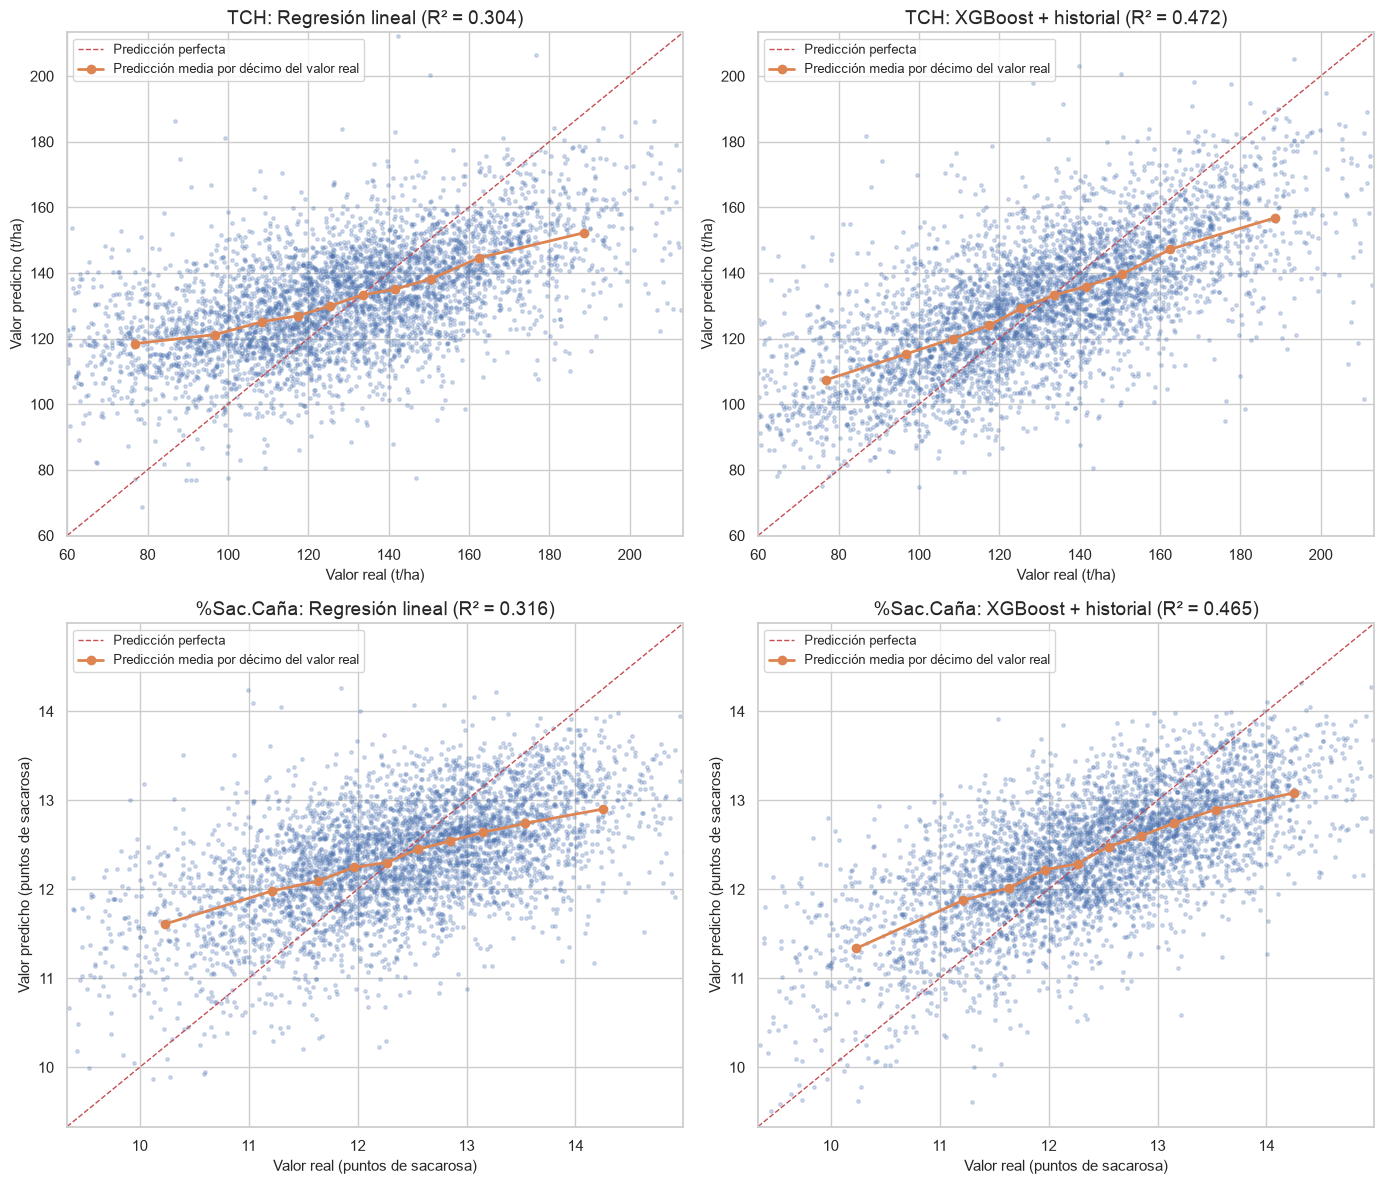

TCH | Regresión lineal: 47 de 4265 registros fuera de los ejes
TCH | XGBoost + historial: 45 de 4265 registros fuera de los ejes
%Sac.Caña | Regresión lineal: 77 de 4279 registros fuera de los ejes
%Sac.Caña | XGBoost + historial: 76 de 4279 registros fuera de los ejes

TCH (t/ha): XGBoost + historial en la prueba, por quintil del valor real


,registros,valor real medio,predicción media,sesgo,MAE
quintil del valor real,,,,,
20 % más bajo,853,86.872,111.376,24.505,25.073
20–40 %,853,113.027,122.028,9.001,13.583
40–60 %,853,129.551,131.225,1.674,11.212
60–80 %,853,146.096,137.767,-8.328,13.421
20 % más alto,853,175.559,151.996,-23.562,24.944



%Sac.Caña (puntos de sacarosa): XGBoost + historial en la prueba, por quintil del valor real


,registros,valor real medio,predicción media,sesgo,MAE
quintil del valor real,,,,,
20 % más bajo,856,10.723,11.605,0.882,0.944
20–40 %,856,11.802,12.118,0.316,0.498
40–60 %,856,12.409,12.384,-0.025,0.400
60–80 %,856,13.000,12.671,-0.329,0.470
20 % más alto,855,13.893,12.989,-0.904,0.919


In [33]:
# 7.2 Valores reales frente a predichos en la prueba: regresión lineal y modelo elegido
MODELOS_REALES_PREDICHOS = ["Regresión lineal", MODELO_ELEGIDO["TCH"]]  # el modelo elegido es el mismo en los dos targets
N_DECILES = 10
PERCENTILES_EJES = (0.5, 99.5)  # los ejes cubren el 99 % central de los datos; los extremos se cuentan aparte
NOMBRES_QUINTILES = ["20 % más bajo", "20–40 %", "40–60 %", "60–80 %", "20 % más alto"]

fig, ejes = plt.subplots(len(TARGETS), len(MODELOS_REALES_PREDICHOS), figsize=(14, 12))
puntos_fuera = []
for fila, target in enumerate(TARGETS):
    valor_real = datos_por_target[target].y_test
    predicciones = {modelo: predicciones_prueba[(modelo, target)].astype(float) for modelo in MODELOS_REALES_PREDICHOS}
    todos_los_valores = np.concatenate([valor_real.to_numpy(), *[p.to_numpy() for p in predicciones.values()]])
    inferior, superior = np.percentile(todos_los_valores, PERCENTILES_EJES)
    margen = 0.05 * (superior - inferior)
    limites = (inferior - margen, superior + margen)
    decil_real = pd.qcut(valor_real, N_DECILES, labels=False)

    for columna, (nombre_modelo, prediccion) in enumerate(predicciones.items()):
        promedios = pd.DataFrame({"real": valor_real, "predicho": prediccion}).groupby(decil_real).mean()
        eje = ejes[fila, columna]
        eje.scatter(valor_real, prediccion, s=6, alpha=0.25, color="#4C72B0")
        eje.plot(limites, limites, color="#C44E52", ls="--", lw=1, label="Predicción perfecta")
        eje.plot(promedios["real"], promedios["predicho"], color="#DD8452", marker="o", lw=2,
                 label="Predicción media por décimo del valor real")
        eje.set(xlim=limites, ylim=limites, xlabel=f"Valor real ({UNIDADES[target]})",
                ylabel=f"Valor predicho ({UNIDADES[target]})",
                title=f"{target}: {nombre_modelo} (R² = {r2_score(valor_real, prediccion):.3f})")
        eje.legend(loc="upper left", fontsize=9)

        fuera = ~(valor_real.between(*limites) & prediccion.between(*limites))
        puntos_fuera.append(f"{target} | {nombre_modelo}: {int(fuera.sum())} de {len(fuera)} registros fuera de los ejes")
plt.tight_layout()
plt.show()
print("\n".join(puntos_fuera))

# Error del modelo elegido por quintil del valor real
for target in TARGETS:
    valor_real = datos_por_target[target].y_test
    prediccion = predicciones_prueba[(MODELO_ELEGIDO[target], target)].astype(float)
    quintil = pd.qcut(valor_real, len(NOMBRES_QUINTILES), labels=NOMBRES_QUINTILES)
    registros_quintil = pd.DataFrame({"real": valor_real, "predicho": prediccion,
                                      "error_absoluto": (prediccion - valor_real).abs()})
    medias = registros_quintil.groupby(quintil, observed=True).mean()
    resumen_quintiles = pd.DataFrame({
        "registros": quintil.value_counts().reindex(medias.index),
        "valor real medio": medias["real"],
        "predicción media": medias["predicho"],
        "sesgo": medias["predicho"] - medias["real"],
        "MAE": medias["error_absoluto"],
    }).rename_axis("quintil del valor real")
    print(f"\n{target} ({UNIDADES[target]}): {MODELO_ELEGIDO[target]} en la prueba, por quintil del valor real")
    display(resumen_quintiles.round(3))

#### Conclusión de 7.2

**Los dos modelos comprimen sus predicciones hacia el centro, y el elegido lo hace menos.** En los cuatro gráficos, la línea de las predicciones medias es más plana que la diagonal: para los lotes de valor real bajo, la predicción queda por encima, y para los de valor real alto, por debajo. Es lo esperable en un modelo que explica menos de la mitad de la variación del target, porque ante la información que no tiene, su mejor predicción se acerca a la media. XGBoost con historial comprime menos que la regresión lineal: su línea está más cerca de la diagonal en los extremos, sobre todo en `TCH`, donde el historial del lote permite distinguir mejor los lotes de rendimiento alto y bajo. En el décimo de menor tonelaje real, por ejemplo, la predicción media baja de 119 t/ha con la regresión lineal a 107 t/ha con el modelo elegido. Los ejes muestran el 99 % central de los datos; menos del 2 % de los registros de cada gráfico queda por fuera.

**El error se concentra en los extremos.** Con el modelo elegido, en los lotes del 20 % de menor tonelaje real la predicción supera al valor real en 24.5 t/ha en promedio, y en los del 20 % de mayor tonelaje queda 23.6 t/ha por debajo. En el 20 % central el sesgo es de solo 1.7 t/ha, y el MAE (11.2 t/ha) es menos de la mitad que en los extremos (cerca de 25 t/ha). En `%Sac.Caña` ocurre lo mismo: sesgo de +0.88 puntos en el quintil más bajo y de −0.90 en el más alto, con un MAE de 0.40 puntos en el centro frente a 0.92–0.94 en los extremos.

**Qué implica para el uso del modelo.** Como los sesgos de los extremos son de magnitud parecida y signo opuesto, se compensan al sumar muchos lotes, así que el modelo es más útil para estimar el tonelaje y la calidad de un conjunto de suertes, como la caña que llegará al ingenio en un periodo, que para anticipar con precisión el resultado de un lote excepcional. Un lote que el modelo pronostica cerca de la media puede estar, en realidad, entre los mejores o los peores; para identificar esos casos hace falta información que el histórico no tiene, como mediciones del cultivo cercanas al corte.

### 7.3 Error por subgrupos

El error global puede ocultar diferencias entre tipos de registros. Se revisa por separado en cuatro divisiones de la prueba:

- **Lluvia medida o sin dato.** Casi la mitad de los registros de prueba no tiene lluvia medida (sección 3.2), y en esos registros las cinco variables de lluvia no aportan información.
- **Con o sin historial.** En los registros sin un corte anterior válido, los modelos con historial no tienen la variable que más mejoró su desempeño (sección 5.3).
- **Cultivo normal u orgánico** y **destino molino o semilla.** Son condiciones de manejo distintas, con pocos registros de prueba en los grupos minoritarios.

En cada subgrupo se comparan tres modelos: la regresión lineal, que es el modelo de referencia; Random Forest con historial, el competidor más cercano del modelo elegido en las secciones 6 y 7.1; y el modelo elegido. Se muestran el número de registros y de haciendas, el RMSE de cada modelo, la diferencia del modelo elegido frente a los otros dos y el sesgo de los dos modelos de árboles (predicción media menos valor real medio). La primera diferencia indica en qué tipo de lotes aporta más el modelo elegido frente a la referencia; la segunda, si su ventaja sobre Random Forest es general o se concentra en algunos lotes. Los subgrupos con pocas haciendas dan estimaciones poco precisas, porque el error de las fincas que les tocaron pesa mucho en el resultado.

In [34]:
# 7.3 Error en prueba por subgrupos: regresión lineal, Random Forest con historial y modelo elegido
MODELO_REFERENCIA = "Regresión lineal"
MODELO_COMPETIDOR = "Random Forest + historial"


def subgrupos_prueba(target):
    """Divisiones de los registros de prueba en las que se revisa el error, a partir de sus columnas crudas."""
    X_prueba = datos_por_target[target].X_test
    return {
        "Lluvia": pd.Series(np.where(X_prueba["lluvia_sin_dato"].astype(bool), "sin dato", "medida"), index=X_prueba.index),
        "Historial del lote": pd.Series(np.where(X_prueba["sin_historial"] == 1, "sin historial", "con historial"),
                                        index=X_prueba.index),
        "Cultivo": X_prueba["Cultivo"].fillna("sin dato"),
        "Destino": pd.Series(np.where(X_prueba["Destino 1=Semilla"] == 1, "semilla", "molino"), index=X_prueba.index),
    }


for target in TARGETS:
    datos = datos_por_target[target]
    haciendas_prueba = df_test.loc[datos.X_test.index, "Hacienda"]
    modelo_elegido = MODELO_ELEGIDO[target]
    prediccion = {nombre_modelo: predicciones_prueba[(nombre_modelo, target)].astype(float)
                  for nombre_modelo in (MODELO_REFERENCIA, MODELO_COMPETIDOR, modelo_elegido)}

    filas = []
    for variable, niveles in subgrupos_prueba(target).items():
        for nivel in sorted(niveles.unique()):
            en_nivel = niveles == nivel
            real = datos.y_test[en_nivel]
            rmse = {nombre_modelo: root_mean_squared_error(real, prediccion_modelo[en_nivel])
                    for nombre_modelo, prediccion_modelo in prediccion.items()}
            filas.append({
                "división": variable,
                "subgrupo": nivel,
                "registros": int(en_nivel.sum()),
                "haciendas": haciendas_prueba[en_nivel].nunique(),
                "RMSE lineal": rmse[MODELO_REFERENCIA],
                "RMSE RF + historial": rmse[MODELO_COMPETIDOR],
                "RMSE elegido": rmse[modelo_elegido],
                "elegido − lineal": rmse[modelo_elegido] - rmse[MODELO_REFERENCIA],
                "elegido − RF + historial": rmse[modelo_elegido] - rmse[MODELO_COMPETIDOR],
                "sesgo RF + historial": prediccion[MODELO_COMPETIDOR][en_nivel].mean() - real.mean(),
                "sesgo elegido": prediccion[modelo_elegido][en_nivel].mean() - real.mean(),
            })
    print(f"\n{target} ({UNIDADES[target]}): error en prueba por subgrupo (modelo elegido: {modelo_elegido}; "
          "diferencia negativa = el modelo elegido tiene menor error)")
    display(pd.DataFrame(filas).set_index(["división", "subgrupo"]).round(3))


TCH (t/ha): error en prueba por subgrupo (modelo elegido: XGBoost + historial; diferencia negativa = el modelo elegido tiene menor error)


registros  haciendas  RMSE lineal  \
división           subgrupo                                           
Lluvia             medida              2280         83       24.813   
                   sin dato            1985        149       28.377   
Historial del lote con historial       3149        108       26.082   
                   sin historial       1116        186       27.760   
Cultivo            Normal              4172        184       26.639   
                   Organico              93          2       21.152   
Destino            molino              4246        186       26.461   
                   semilla               19          9       39.127   

                                  RMSE RF + historial  RMSE elegido  \
división           subgrupo                                           
Lluvia             medida                      23.015        22.582   
                   sin dato                    24.017        23.700   
Historial del lote con historial               21.813        21.540   
                   sin historial               27.669        27.050   
Cultivo            Normal                      23.576        23.195   
                   Organico                    19.064        18.826   
Destino            molino                      23.370        23.008   
                   semilla                     42.089        39.672   

                                  elegido − lineal  elegido − RF + historial  \
división           subgrupo                                                    
Lluvia             medida                   -2.231                    -0.434   
                   sin dato                 -4.677                    -0.317   
Historial del lote con historial            -4.542                    -0.273   
                   sin historial            -0.710                    -0.619   
Cultivo            Normal                   -3.443                    -0.381   
                   Organico                 -2.326                    -0.239   
Destino            molino                   -3.453                    -0.362   
                   semilla                   0.545                    -2.417   

                                  sesgo RF + historial  sesgo elegido  
división           subgrupo                                            
Lluvia             medida                       -1.354         -0.895  
                   sin dato                      4.201          2.441  
Historial del lote con historial                 1.711          1.079  
                   sin historial                -0.121         -0.530  
Cultivo            Normal                        1.459          0.867  
                   Organico                     -8.978         -8.709  
Destino            molino                        1.126          0.558  
                   semilla                      24.910         23.010


%Sac.Caña (puntos de sacarosa): error en prueba por subgrupo (modelo elegido: XGBoost + historial; diferencia negativa = el modelo elegido tiene menor error)


registros  haciendas  RMSE lineal  \
división           subgrupo                                           
Lluvia             medida              2259         83        0.905   
                   sin dato            2020        149        0.991   
Historial del lote con historial       3154        109        0.932   
                   sin historial       1125        186        0.986   
Cultivo            Normal              4193        184        0.949   
                   Organico              86          2        0.828   
Destino            molino              4279        186        0.946   

                                  RMSE RF + historial  RMSE elegido  \
división           subgrupo                                           
Lluvia             medida                       0.819         0.795   
                   sin dato                     0.910         0.883   
Historial del lote con historial                0.846         0.815   
                   sin historial                0.910         0.898   
Cultivo            Normal                       0.865         0.838   
                   Organico                     0.800         0.793   
Destino            molino                       0.863         0.837   

                                  elegido − lineal  elegido − RF + historial  \
división           subgrupo                                                    
Lluvia             medida                   -0.110                    -0.025   
                   sin dato                 -0.109                    -0.028   
Historial del lote con historial            -0.117                    -0.031   
                   sin historial            -0.088                    -0.013   
Cultivo            Normal                   -0.111                    -0.027   
                   Organico                 -0.035                    -0.007   
Destino            molino                   -0.109                    -0.026   

                                  sesgo RF + historial  sesgo elegido  
división           subgrupo                                            
Lluvia             medida                       -0.003         -0.013  
                   sin dato                     -0.004         -0.011  
Historial del lote con historial                -0.015         -0.018  
                   sin historial                 0.029          0.006  
Cultivo            Normal                       -0.003         -0.012  
                   Organico                     -0.036         -0.010  
Destino            molino                       -0.003         -0.012

#### Conclusión de 7.3

**La falta de lluvia afecta más a la regresión lineal que a los modelos de árboles.** En `TCH`, el error de la regresión lineal sube de 24.81 t/ha en los registros con lluvia medida a 28.38 en los que no la tienen. El del modelo elegido sube solo de 22.58 a 23.70, y el de Random Forest con historial, de 23.02 a 24.02. Por eso la mayor proporción de registros sin lluvia medida en la prueba (47.0 %) no aumentó el error global del modelo elegido: es en esos registros donde más mejora frente a la regresión lineal (4.68 t/ha, frente a 2.23 con lluvia medida). Los modelos de árboles compensan la falta de lluvia con el resto de la información, sobre todo con el historial del lote, mientras que la regresión lineal solo puede aplicar un ajuste fijo con la marca `lluvia_sin_dato`. Sin lluvia medida, Random Forest con historial sobrestima el tonelaje en 4.2 t/ha en promedio y el modelo elegido en 2.4. En `%Sac.Caña` los tres modelos tienen más error sin lluvia medida, y la mejora del modelo elegido es la misma con lluvia y sin ella.

**En `TCH`, la ventaja sobre la regresión lineal está casi toda en los lotes con historial.** Con historial, el RMSE del modelo elegido es de 21.54 t/ha frente a 26.08 de la regresión lineal; sin historial, de 27.05 frente a 27.76. Coincide con lo visto en 5.3 y 6.2: lo que más aporta en tonelaje es el resultado del corte anterior. En los lotes sin historial, Random Forest con historial prácticamente iguala a la regresión lineal (27.67 t/ha), y el modelo elegido la mejora en apenas 0.71 t/ha. Para los lotes nuevos, o para los que acaban de renovarse, los modelos de árboles ofrecen poco más que la regresión lineal. En `%Sac.Caña` la mejora sobre la regresión lineal se reparte de forma más pareja: 0.117 puntos con historial y 0.088 sin él.

**La ventaja del modelo elegido sobre Random Forest con historial es pequeña, pero general.** El modelo elegido tiene menor error que Random Forest con historial en todos los subgrupos de los dos targets: entre 0.24 y 0.62 t/ha en `TCH`, y entre 0.007 y 0.031 puntos en `%Sac.Caña`. La diferencia no viene de un tipo de lote en particular, lo que respalda la elección hecha en 6.3. En `TCH` la ventaja es mayor precisamente en los lotes sin historial (0.62 t/ha), donde XGBoost aprovecha mejor los demás predictores.

**Ninguno de los modelos es adecuado para los lotes de semilla.** En los 19 registros de prueba de destino semilla, de 9 haciendas, los tres modelos tienen un error de 39 a 42 t/ha, y los dos de árboles sobrestiman el tonelaje en unas 23 a 25 t/ha. Esos lotes son apenas el 1.6 % del entrenamiento y se cosechan con criterios distintos a los comerciales, así que los modelos los predicen como si fueran lotes de molino. Para ellos haría falta un modelo propio o, al menos, no usar estas predicciones. La sacarosa no se mide en los lotes de semilla, por lo que no aparecen en la tabla de `%Sac.Caña`.

**Los lotes orgánicos no permiten conclusiones.** Los 93 registros de prueba de cultivo orgánico vienen de solo 2 haciendas, así que su error refleja sobre todo esas dos fincas. El sesgo de cerca de −9 t/ha que comparten los dos modelos de árboles en `TCH` puede ser propio de ellas.

Fuera de estos casos, el sesgo del modelo elegido es pequeño en todos los subgrupos: menos de 2.5 t/ha en `TCH` y de 0.02 puntos en `%Sac.Caña`, y en `TCH` es menor que el de Random Forest con historial en casi todos ellos.

### Conclusión de la sección 7

En el conjunto de prueba, que no intervino en ninguna decisión, XGBoost con historial confirma lo que mostró la validación cruzada: es el mejor modelo en los dos targets, por delante de Random Forest con historial y de la regresión lineal.

| Target | Modelo | RMSE prueba | MAE prueba | R² prueba |
|---|---|---|---|---|
| `TCH` (t/ha) | Regresión lineal | 26.53 | 20.40 | 0.304 |
| | Random Forest + historial | 23.49 | 18.01 | 0.455 |
| | XGBoost + historial | 23.11 | 17.65 | 0.472 |
| `%Sac.Caña` (puntos) | Regresión lineal | 0.946 | 0.731 | 0.316 |
| | Random Forest + historial | 0.863 | 0.670 | 0.431 |
| | XGBoost + historial | 0.837 | 0.646 | 0.465 |

El orden de todos los modelos es el mismo que en validación, y el error de prueba no es mayor que el de validación. Según el bootstrap por hacienda, la ventaja del modelo elegido sobre la regresión lineal es amplia (3.42 t/ha y 0.109 puntos) y la ventaja sobre Random Forest con historial es pequeña pero no depende de qué fincas quedaron en la prueba (0.38 t/ha, con intervalo del 95 % de 0.04 a 0.70, y 0.026 puntos, de 0.018 a 0.036). Además, se repite en todos los subgrupos revisados en 7.3. Las dos versiones con historial quedan cerca entre sí, como en validación; lo que más separa a los modelos es el historial del lote, más que el algoritmo de árboles.

El análisis del error delimita para qué sirve el modelo:

- **Mejor para conjuntos de lotes que para lotes individuales extremos.** Comprime sus predicciones hacia la media: sobrestima los lotes de rendimiento bajo y subestima los de rendimiento alto, en magnitudes parecidas que se compensan al agregar.
- **Más útil donde hay historia del lote.** En `TCH`, casi toda su ventaja sobre la regresión lineal está en los lotes con un corte anterior registrado; en los lotes sin historial aporta poco.
- **Robusto a la falta de lluvia medida**, que perjudica mucho más a la regresión lineal.
- **No apto para lotes de semilla**, que predice con un error y un sesgo muy grandes.

Estos resultados corresponden a fincas nuevas en años con cosechas conocidas. Para una zafra futura, el desempeño esperado es el de la doble agrupación de 6.2, con un R² de 0.239 en `TCH` y de 0.315 en `%Sac.Caña`, y allí XGBoost y Random Forest con historial quedaron prácticamente empatados. La sección 8 examina qué variables explican las predicciones del modelo.

## 8. Interpretabilidad

Los modelos de árboles no tienen coeficientes que se puedan leer directamente, como los de la regresión lineal en 4.2. Para saber qué variables usan y cómo, se combinan tres técnicas:

1. **Importancia por permutación (8.1):** cuánto empeora el modelo cuando se rompe la relación de una variable con el target.
2. **Importancia propia de XGBoost (8.2):** cuánto contribuye cada variable a reducir el error durante el ajuste de los árboles.
3. **Dependencia parcial (8.3):** cómo cambia la predicción media al variar una variable, con las demás fijas en sus valores observados.

Por último, se contrastan los resultados con los coeficientes del modelo lineal y se traducen al contexto agronómico (8.4).

### 8.1 Importancia por permutación

Para medir la importancia de una variable se desordenan al azar sus valores entre los registros de prueba, dejando las demás intactas, y se recalcula el RMSE. Si el modelo depende de esa variable, sus predicciones empeoran; el aumento del RMSE es la importancia. Se repite diez veces por variable y se reporta el aumento medio y su desviación.

Tres decisiones del cálculo:

- **Variables originales.** Se permutan las columnas crudas que entran al `Pipeline`, antes del preprocesamiento. Así cada variable categórica se evalúa completa: permutar `Variedad` cambia a la vez todas sus indicadoras, y permutar `Período` mueve juntos `Año` y `Mes`. `Producto` no se reporta, porque solo se usa para imputar las semanas de madurante.
- **Conjunto de prueba.** La importancia se mide en datos que los modelos no vieron. No se toma ninguna decisión con ella, así que no compromete la evaluación de la sección 7.
- **Tres modelos.** Se calcula para los tres modelos con historial, para ver si coinciden en qué variables importan.

La técnica tiene un límite conocido: cuando dos variables están correlacionadas, el modelo puede apoyarse en la que queda intacta al permutar la otra, y las dos aparecen menos importantes de lo que son juntas. Es el caso de las ventanas de lluvia entre sí y con `lluvia_sin_dato`, y de la edad del cultivo con el número de corte.

  [20:05] Regresión lineal + historial | TCH
  [20:05] Random Forest + historial | TCH
  [20:06] XGBoost + historial | TCH


/Users/juan/Documents/Maestria/PrimerSemestre/AprendizajeAutomaticoII/TallerFinal/env/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  [20:06] Regresión lineal + historial | %Sac.Caña
  [20:06] Random Forest + historial | %Sac.Caña
  [20:07] XGBoost + historial | %Sac.Caña


/Users/juan/Documents/Maestria/PrimerSemestre/AprendizajeAutomaticoII/TallerFinal/env/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


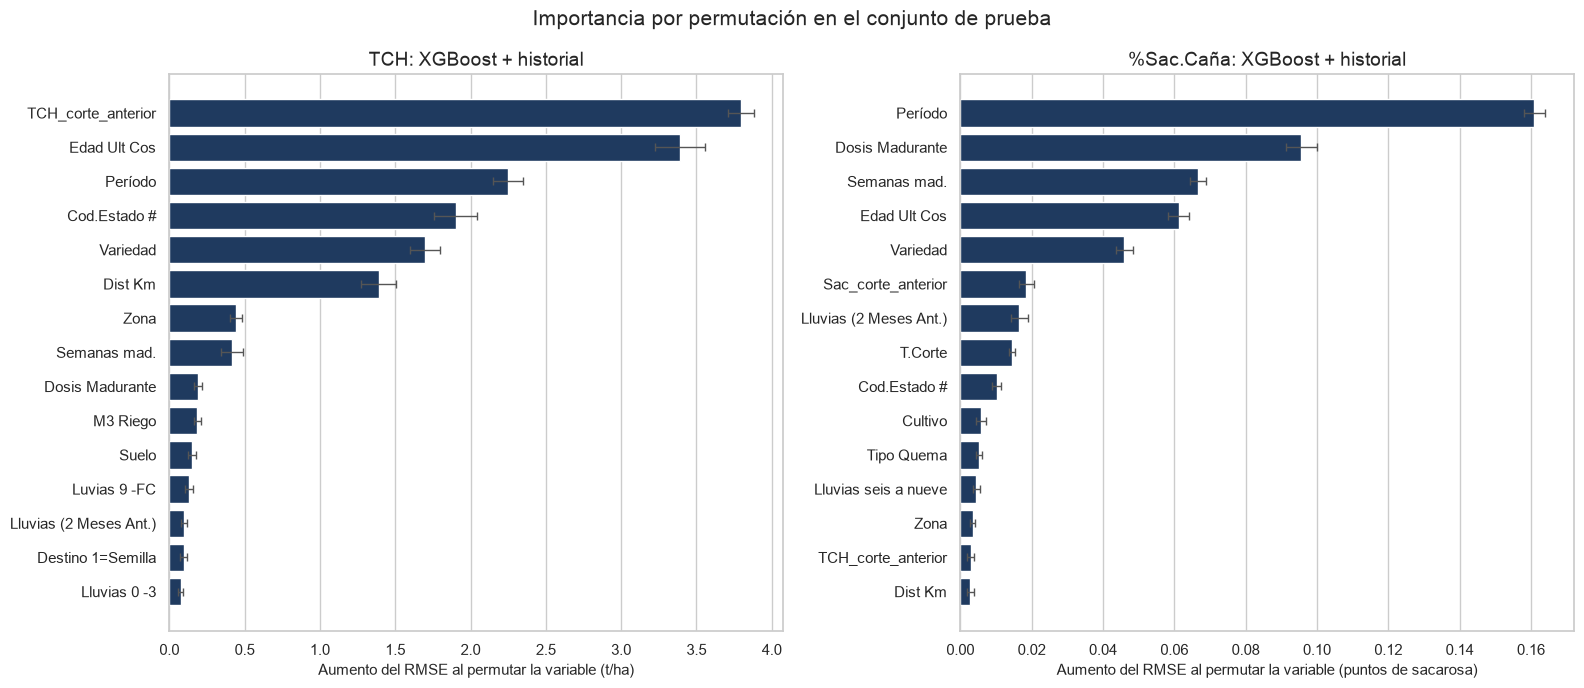


TCH (t/ha): importancia por permutación en los tres modelos con historial


,aumento: Regresión lineal + historial,aumento: Random Forest + historial,aumento: XGBoost + historial,posición: Regresión lineal + historial,posición: Random Forest + historial,posición: XGBoost + historial
TCH_corte_anterior,2.396,4.349,3.794,3,1,1
Edad Ult Cos,3.896,2.943,3.390,1,2,2
Período,1.548,1.352,2.246,4,4,3
Cod.Estado #,0.138,2.620,1.901,14,3,4
Variedad,3.168,0.861,1.700,2,5,5
Dist Km,0.448,0.712,1.391,8,6,6
Zona,0.465,0.295,0.443,7,8,7
Semanas mad.,0.654,0.223,0.417,5,9,8
Dosis Madurante,0.067,0.314,0.190,18,7,9
M3 Riego,0.446,0.100,0.184,9,13,10



%Sac.Caña (puntos de sacarosa): importancia por permutación en los tres modelos con historial


,aumento: Regresión lineal + historial,aumento: Random Forest + historial,aumento: XGBoost + historial,posición: Regresión lineal + historial,posición: Random Forest + historial,posición: XGBoost + historial
Período,0.115,0.121,0.161,1,1,1
Dosis Madurante,0.087,0.111,0.096,2,2,2
Semanas mad.,0.006,0.059,0.067,10,3,3
Edad Ult Cos,0.005,0.052,0.061,11,4,4
Variedad,0.056,0.028,0.046,3,5,5
Sac_corte_anterior,0.013,0.022,0.018,7,6,6
Lluvias (2 Meses Ant.),0.011,0.018,0.017,9,7,7
T.Corte,0.020,0.005,0.015,6,10,8
Cod.Estado #,-0.000,0.009,0.010,23,8,9
Cultivo,0.012,0.009,0.006,8,9,10


In [35]:
# 8.1 Importancia por permutación de las variables originales, en el conjunto de prueba
from sklearn.inspection import permutation_importance

N_REPETICIONES_PERMUTACION = 10
MODELOS_INTERPRETACION = ["Regresión lineal + historial", "Random Forest + historial", "XGBoost + historial"]
COLUMNAS_AUXILIARES = ["Producto"]  # solo se usa para imputar las semanas de madurante; no es un predictor
N_VARIABLES_GRAFICO = 15
RUTA_PERMUTACION = CARPETA_RESULTADOS / "importancia_permutacion.joblib"


def calcular_importancia_permutacion():
    """Aumento del RMSE al permutar cada variable original, para cada modelo y target."""
    importancias = {}
    for target in TARGETS:
        datos = datos_por_target[target]
        for nombre_modelo in MODELOS_INTERPRETACION:
            print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target}", flush=True)
            resultado = permutation_importance(
                modelo_final_ajustado(nombre_modelo, target), datos.X_test, datos.y_test,
                scoring="neg_root_mean_squared_error", n_repeats=N_REPETICIONES_PERMUTACION,
                random_state=RANDOM_STATE, n_jobs=PROCESOS_RANDOM_FOREST,
            )
            importancias[(nombre_modelo, target)] = pd.DataFrame(
                {"aumento del RMSE": resultado.importances_mean, "desv.": resultado.importances_std},
                index=datos.X_test.columns,
            ).drop(index=COLUMNAS_AUXILIARES).sort_values("aumento del RMSE", ascending=False)
    return importancias


# Resultados guardados: Random Forest predice despacio y el cálculo tarda unos minutos
guardado = None
if RUTA_PERMUTACION.exists() and not RECALCULAR_BUSQUEDAS:
    try:
        guardado = joblib.load(RUTA_PERMUTACION)
    except Exception as error:  # archivo dañado o de otra versión de las librerías
        print(f"No se pudo leer {RUTA_PERMUTACION} ({type(error).__name__}); el cálculo se repite.")
if isinstance(guardado, dict) and guardado.get("modelos") == MODELOS_INTERPRETACION:
    importancia_permutacion = guardado["importancias"]
    print(f"Resultados cargados de {RUTA_PERMUTACION}")
else:
    importancia_permutacion = calcular_importancia_permutacion()
    guardar_busqueda(RUTA_PERMUTACION, {"modelos": MODELOS_INTERPRETACION, "importancias": importancia_permutacion})

# Gráfico: las variables más importantes del modelo elegido
fig, ejes = plt.subplots(1, len(TARGETS), figsize=(16, 7))
for eje, target in zip(ejes, TARGETS):
    principales = importancia_permutacion[(MODELO_ELEGIDO[target], target)].head(N_VARIABLES_GRAFICO).iloc[::-1]
    eje.barh(principales.index, principales["aumento del RMSE"], xerr=principales["desv."],
             color="#1F3A5F", capsize=3, error_kw={"elinewidth": 1, "ecolor": "#555555"})
    eje.set(title=f"{target}: {MODELO_ELEGIDO[target]}",
            xlabel=f"Aumento del RMSE al permutar la variable ({UNIDADES[target]})")
    eje.grid(axis="y", visible=False)
fig.suptitle("Importancia por permutación en el conjunto de prueba", fontsize=15)
plt.tight_layout()
plt.show()

# Tabla: posición y aumento del RMSE de cada variable en los tres modelos
for target in TARGETS:
    comparacion = pd.concat({
        nombre_modelo: importancia_permutacion[(nombre_modelo, target)]["aumento del RMSE"]
        for nombre_modelo in MODELOS_INTERPRETACION
    }, axis=1)
    posiciones = comparacion.rank(ascending=False).astype(int).add_prefix("posición: ")
    tabla = pd.concat([comparacion.round(3).add_prefix("aumento: "), posiciones], axis=1)
    print(f"\n{target} ({UNIDADES[target]}): importancia por permutación en los tres modelos con historial")
    display(tabla.sort_values(f"posición: {MODELO_ELEGIDO[target]}"))

#### Conclusión de 8.1

**`TCH`.** Para el modelo elegido, las variables más importantes son el TCH del corte anterior (permutarla aumenta el RMSE en 3.79 t/ha), la edad del cultivo al corte (3.39), el periodo de cosecha (2.25), el número de corte (1.90), la variedad (1.70) y la distancia al ingenio (1.39). Después de esas seis variables, la importancia cae por debajo de 0.5 t/ha. Los tres modelos coinciden en que el historial, la edad, el periodo y la variedad están entre las variables principales. La importancia del periodo concuerda con lo visto en 6.2: parte de lo que los modelos aprenden son condiciones propias de cada año y mes.

**`%Sac.Caña`.** El periodo de cosecha es la variable más importante (0.161 puntos), seguido de la dosis de madurante (0.096), las semanas desde su aplicación (0.067), la edad del cultivo (0.061) y la variedad (0.046). La sacarosa del corte anterior (0.018) y la lluvia de los dos meses previos al corte (0.017) aportan menos. Los tres modelos coinciden en que el periodo y la dosis de madurante son las dos variables principales.

**Lo que los árboles aprovechan y el modelo lineal no.** Las diferencias entre modelos están en variables cuyo efecto no es lineal:

- **Número de corte en `TCH`.** Es casi irrelevante para la regresión lineal (0.14 t/ha, posición 14), pero es la cuarta variable de XGBoost (1.90) y Random Forest (2.62). El EDA mostró que el TCH cae con el número de corte hasta el corte 9 o 10 y después se aplana; una pendiente única no representa ese codo, y en 4.2 su coeficiente fue de solo −0.52 t/ha por corte.
- **Semanas de madurante y edad en `%Sac.Caña`.** En la regresión lineal casi no importan (0.006 y 0.005 puntos), mientras que en los árboles son la tercera y la cuarta variable (0.06–0.07). En 4.2, el coeficiente de la edad no fue significativo y el de las semanas fue muy pequeño. Su efecto sobre la sacarosa existe, pero no tiene la forma de una recta.
- **Distancia al ingenio en `TCH`.** Pesa tres veces más en XGBoost (1.39 t/ha) que en la regresión lineal (0.45). En el EDA su relación con el TCH era por tramos; además, como toma un valor por hacienda, ayuda a los árboles a ubicar grupos de fincas parecidas.

Al revés, la regresión lineal depende más de la variedad (3.17 t/ha, segunda variable) que los árboles (0.86 y 1.70) y es la única que usa la marca `lluvia_sin_dato` (0.64 t/ha frente a casi cero). Sin poder combinar variables, el modelo lineal concentra en ellas efectos que los árboles reparten entre varias.

Las ventanas de lluvia tienen importancias individuales pequeñas en todos los modelos. Puede deberse a que su efecto es pequeño, como sugerían los coeficientes de 4.2, pero también a la limitación de la técnica: como están correlacionadas entre sí, al permutar una el modelo se apoya en las demás.

### 8.2 Importancia propia de XGBoost

XGBoost registra, durante el ajuste, cuánto reduce la pérdida cada división de cada árbol. La ganancia total de una columna es la suma de esas reducciones en todas las divisiones que la usan. A diferencia de la permutación, se mide en el entrenamiento y refleja cómo el modelo construyó sus árboles, no cuánto pierde en datos nuevos si la variable deja de estar disponible.

Como la ganancia total es aditiva, se suma por variable original: las indicadoras de cada variable categórica se agrupan en su variable, y `Año` y `Mes` en `Período`, igual que en 8.1. Para comparar las dos técnicas, cada importancia se expresa como fracción del total de su técnica.

Las dos medidas pueden diferir. La ganancia tiende a favorecer las variables numéricas con muchos valores distintos, porque ofrecen más puntos de corte; la permutación, en cambio, subestima las variables correlacionadas. Una variable importante en las dos es una conclusión más sólida.

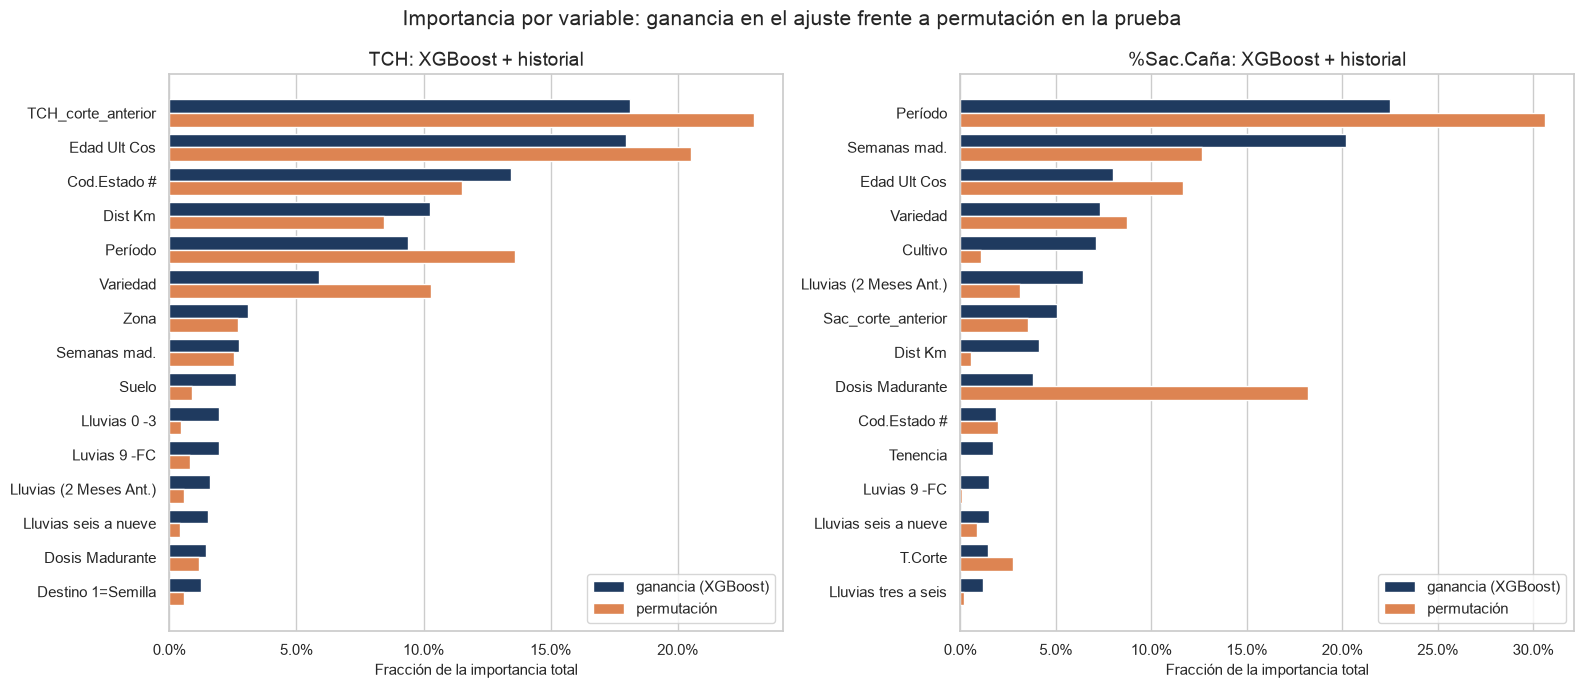


TCH: fracción de la importancia total según cada técnica


,ganancia (XGBoost),permutación,posición (ganancia),posición (permutación)
TCH_corte_anterior,0.181,0.230,1,1
Edad Ult Cos,0.180,0.205,2,2
Cod.Estado #,0.134,0.115,3,4
Dist Km,0.103,0.084,4,6
Período,0.094,0.136,5,3
Variedad,0.059,0.103,6,5
Zona,0.031,0.027,7,7
Semanas mad.,0.027,0.025,8,8
Suelo,0.026,0.009,9,11
Lluvias 0 -3,0.020,0.005,10,15



%Sac.Caña: fracción de la importancia total según cada técnica


,ganancia (XGBoost),permutación,posición (ganancia),posición (permutación)
Período,0.225,0.306,1,1
Semanas mad.,0.202,0.127,2,3
Edad Ult Cos,0.080,0.116,3,4
Variedad,0.073,0.087,4,5
Cultivo,0.071,0.011,5,10
Lluvias (2 Meses Ant.),0.064,0.031,6,7
Sac_corte_anterior,0.051,0.035,7,6
Dist Km,0.041,0.005,8,15
Dosis Madurante,0.038,0.182,9,2
Cod.Estado #,0.019,0.019,10,9


In [36]:
# 8.2 Importancia propia de XGBoost (ganancia total), agrupada por variable original y comparada con la permutación
PREFIJOS_VARIABLE = {
    "Zona_agrup_": "Zona", "Variedad_agrup_": "Variedad", "Suelo_agrup_": "Suelo", "T.Corte_agrup_": "T.Corte",
    "Tipo Quema_": "Tipo Quema", "Cultivo_": "Cultivo", "Tenencia_agrup_": "Tenencia", "Mes_": "Período",
}
COLORES_TECNICA = {"ganancia (XGBoost)": "#1F3A5F", "permutación": "#DD8452"}


def variable_original(columna):
    """Variable original de una columna del preprocesamiento: las indicadoras se agrupan en su variable,
    y Año y Mes en Período."""
    if columna == "Año":
        return "Período"
    for prefijo, variable in PREFIJOS_VARIABLE.items():
        if columna.startswith(prefijo):
            return variable
    return columna


comparacion_importancias = {}
for target in TARGETS:
    booster = modelo_final_ajustado(MODELO_ELEGIDO[target], target).named_steps["modelo"].get_booster()
    ganancia = pd.Series(booster.get_score(importance_type="total_gain"))
    ganancia_por_variable = ganancia.groupby(ganancia.index.map(variable_original)).sum()

    permutacion = importancia_permutacion[(MODELO_ELEGIDO[target], target)]["aumento del RMSE"].clip(lower=0)
    comparacion = pd.DataFrame({
        "ganancia (XGBoost)": ganancia_por_variable / ganancia_por_variable.sum(),
        "permutación": permutacion / permutacion.sum(),
    }).fillna(0.0)
    comparacion_importancias[target] = comparacion.sort_values("ganancia (XGBoost)", ascending=False)

# Gráfico: las dos importancias, como fracción del total, para las variables principales
fig, ejes = plt.subplots(1, len(TARGETS), figsize=(16, 7))
for eje, target in zip(ejes, TARGETS):
    principales = comparacion_importancias[target].head(N_VARIABLES_GRAFICO).iloc[::-1]
    posiciones = np.arange(len(principales))
    for desplazamiento, (tecnica, color) in zip((0.2, -0.2), COLORES_TECNICA.items()):
        eje.barh(posiciones + desplazamiento, principales[tecnica], height=0.4, color=color, label=tecnica)
    eje.set_yticks(posiciones, principales.index)
    eje.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    eje.set(title=f"{target}: {MODELO_ELEGIDO[target]}", xlabel="Fracción de la importancia total")
    eje.grid(axis="y", visible=False)
    eje.legend(loc="lower right")
fig.suptitle("Importancia por variable: ganancia en el ajuste frente a permutación en la prueba", fontsize=15)
plt.tight_layout()
plt.show()

for target in TARGETS:
    tabla = comparacion_importancias[target].copy()
    tabla["posición (ganancia)"] = tabla["ganancia (XGBoost)"].rank(ascending=False).astype(int)
    tabla["posición (permutación)"] = tabla["permutación"].rank(ascending=False).astype(int)
    print(f"\n{target}: fracción de la importancia total según cada técnica")
    display(tabla.round(3))